In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

ZIP_PATH = "/content/Mumbai_Slum_Final_Tiled_Dataset.zip"
EXTRACT_DIR = "/content/mumbai_slum_dataset"

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted.")

Dataset extracted.


In [ ]:
import os

for root, dirs, files in os.walk(EXTRACT_DIR):
    if files:
        print(root, len(files))

/content/mumbai_slum_dataset/tiles/Wadala 272
/content/mumbai_slum_dataset/tiles/Kurla 206
/content/mumbai_slum_dataset/tiles/Bandra_East 272
/content/mumbai_slum_dataset/tiles/Mankhurd 264
/content/mumbai_slum_dataset/tiles/Sion_Koliwada 272
/content/mumbai_slum_dataset/tiles/Antop_Hill 272
/content/mumbai_slum_dataset/tiles/Govandi 272
/content/mumbai_slum_dataset/tiles/Cuffe_Parade_Backside 71
/content/mumbai_slum_dataset/tiles/Chembur 272
/content/mumbai_slum_dataset/tiles/Dharavi 68
/content/mumbai_slum_dataset/tiles/Kandivali 276
/content/mumbai_slum_dataset/tiles/Andheri_East 408
/content/mumbai_slum_dataset/tiles/Jogeshwari 270
/content/mumbai_slum_dataset/tiles/Malad_Malvani 414
/content/mumbai_slum_dataset/metadata 1


In [ ]:
!pip install -q opencv-python-headless scikit-image scikit-learn pandas matplotlib tqdm

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import pandas as pd
import os

METADATA_PATH = os.path.join(
    EXTRACT_DIR,
    "metadata",
    "tile_metadata.csv"
)

df = pd.read_csv(METADATA_PATH)

print("Total tiles:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nLocations:")
print(df["location"].nunique())
print(df["location"].unique())

print("\nYears:")
print(sorted(df["year"].unique()))

Total tiles: 3609

Columns:
['location', 'year', 'original_filename', 'tile_filename', 'original_width', 'original_height', 'tile_x', 'tile_y', 'tile_width_original', 'tile_height_original', 'tile_size', 'stride', 'overlap', 'padding_width', 'padding_height', 'has_padding']

Locations:
14
['Andheri_East' 'Antop_Hill' 'Bandra_East' 'Chembur'
 'Cuffe_Parade_Backside' 'Dharavi' 'Govandi' 'Jogeshwari' 'Kandivali'
 'Kurla' 'Malad_Malvani' 'Mankhurd' 'Sion_Koliwada' 'Wadala']

Years:
[np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


year
2017    360
2018    374
2019    387
2020    474
2021    416
2022    369
2023    422
2024    437
2025    370
dtype: int64


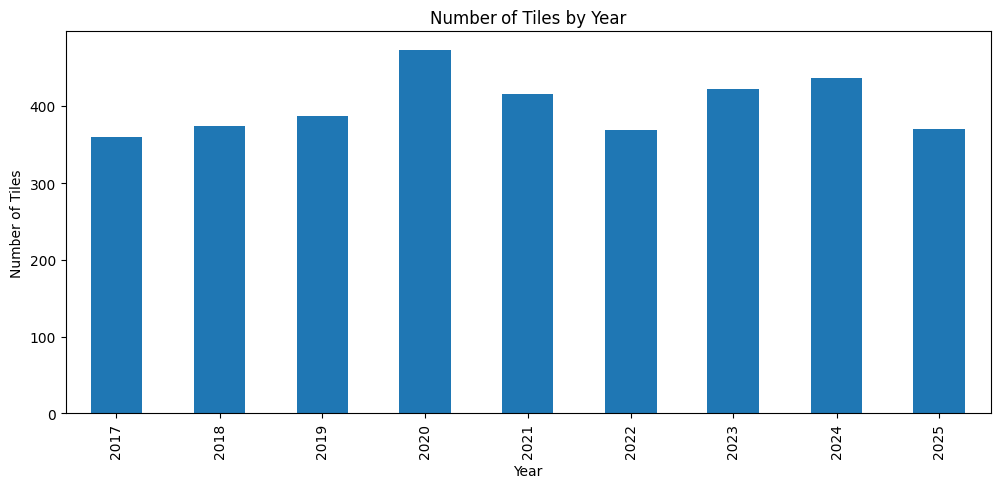

In [ ]:
year_counts = df.groupby("year").size()

print(year_counts)

year_counts.plot(
    kind="bar",
    figsize=(12,5),
    title="Number of Tiles by Year"
)

import matplotlib.pyplot as plt
plt.xlabel("Year")
plt.ylabel("Number of Tiles")
plt.show()

In [ ]:
location_year = pd.crosstab(
    df["location"],
    df["year"]
)

display(location_year)

year,2017,2018,2019,2020,2021,2022,2023,2024,2025
location,,,,,,,,,
Andheri_East,42,42,48,54,42,42,48,48,42
Antop_Hill,28,28,28,36,32,28,32,32,28
Bandra_East,28,28,28,36,32,28,32,32,28
Chembur,24,28,32,36,32,28,32,32,28
Cuffe_Parade_Backside,7,7,8,9,8,8,8,9,7
Dharavi,7,7,7,9,8,7,8,8,7
Govandi,24,28,32,36,32,28,32,32,28
Jogeshwari,28,28,28,36,30,28,32,32,28
Kandivali,28,28,28,36,32,28,32,36,28


Image shape: (256, 256, 3)


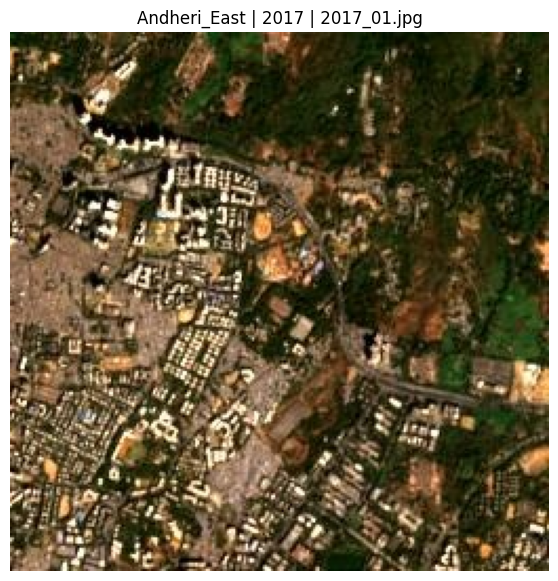

In [ ]:
import cv2
import matplotlib.pyplot as plt

sample = df.iloc[0]

tile_path = os.path.join(
    EXTRACT_DIR,
    "tiles",
    sample["location"],
    sample["tile_filename"]
)

img = cv2.imread(tile_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image shape:", img.shape)

plt.figure(figsize=(7,7))
plt.imshow(img)
plt.title(
    f"{sample['location']} | {sample['year']} | "
    f"{sample['original_filename']}"
)
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
import cv2
from skimage.feature import local_binary_pattern

def extract_pixel_features(image):
    """
    Extract automatic pixel-level features.
    """

    image = image.astype(np.uint8)

    # RGB
    rgb = image / 255.0

    # HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hsv = hsv.astype(np.float32)
    hsv[:, :, 0] /= 179.0
    hsv[:, :, 1:] /= 255.0

    # LAB
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    lab = lab.astype(np.float32) / 255.0

    # Gray
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Local variance / texture
    gray_float = gray.astype(np.float32)

    mean = cv2.blur(gray_float, (11, 11))
    mean_sq = cv2.blur(gray_float ** 2, (11, 11))

    local_variance = np.maximum(
        mean_sq - mean ** 2,
        0
    )

    local_variance = np.sqrt(local_variance)
    local_variance /= 255.0

    # Gradient
    gx = cv2.Sobel(gray_float, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_float, cv2.CV_32F, 0, 1, ksize=3)

    gradient = np.sqrt(gx ** 2 + gy ** 2)
    gradient = np.clip(gradient / 255.0, 0, 1)

    # Green dominance
    r = rgb[:, :, 0]
    g = rgb[:, :, 1]
    b = rgb[:, :, 2]

    green_index = (
        g - (r + b) / 2
    )

    green_index = np.clip(
        green_index,
        -1,
        1
    )

    features = np.concatenate(
        [
            rgb,
            hsv,
            lab,
            local_variance[..., None],
            gradient[..., None],
            green_index[..., None]
        ],
        axis=2
    )

    return features

In [ ]:
import numpy as np
import cv2


def normalize_feature(x):
    """
    Robust min-max normalization using percentiles.
    """

    low = np.percentile(x, 5)
    high = np.percentile(x, 95)

    if high - low < 1e-6:
        return np.zeros_like(x)

    x = (x - low) / (high - low)

    return np.clip(x, 0, 1)




In [ ]:
import os
import glob

EXTRACT_DIR = "/content/mumbai_slum_dataset"

image_paths = []

for ext in ["*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG"]:
    image_paths.extend(
        glob.glob(
            os.path.join(
                EXTRACT_DIR,
                "**",
                ext
            ),
            recursive=True
        )
    )

image_paths = sorted(image_paths)

print("Total images found:", len(image_paths))

print("\nFirst 10 images:")
for p in image_paths[:10]:
    print(p)

Total images found: 3609

First 10 images:
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0000_x0_y0.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0001_x171_y0.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0002_x0_y192.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0003_x171_y192.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0004_x0_y193.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0005_x171_y193.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_02_tile_0000_x0_y0.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_02_tile_0001_x171_y0.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_02_tile_0002_x0_y192.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_02_tile_0003_x171_y192.jpg


In [ ]:
# ============================================================
# STEP 8 — SELECT 30 REPRESENTATIVE TILES
# ============================================================

import numpy as np
import os

SAMPLE_SIZE = 30

sample_indices = np.linspace(
    0,
    len(image_paths) - 1,
    SAMPLE_SIZE,
    dtype=int
)

sample_paths = [
    image_paths[i]
    for i in sample_indices
]

print("Selected tiles:", len(sample_paths))

print("\nSelected sample:")
for i, p in enumerate(sample_paths):
    print(
        f"{i+1:02d}. {p}"
    )

Selected tiles: 30

Selected sample:
01. /content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0000_x0_y0.jpg
02. /content/mumbai_slum_dataset/tiles/Andheri_East/2019_11_tile_0004_x0_y193.jpg
03. /content/mumbai_slum_dataset/tiles/Andheri_East/2022_04_tile_0002_x0_y192.jpg
04. /content/mumbai_slum_dataset/tiles/Andheri_East/2025_02_tile_0001_x176_y0.jpg
05. /content/mumbai_slum_dataset/tiles/Antop_Hill/2020_02_tile_0001_x14_y0.jpg
06. /content/mumbai_slum_dataset/tiles/Antop_Hill/2024_01_tile_0002_x0_y28.jpg
07. /content/mumbai_slum_dataset/tiles/Bandra_East/2019_03_tile_0002_x0_y84.jpg
08. /content/mumbai_slum_dataset/tiles/Bandra_East/2023_03_tile_0002_x0_y84.jpg
09. /content/mumbai_slum_dataset/tiles/Chembur/2018_10_tile_0003_x118_y136.jpg
10. /content/mumbai_slum_dataset/tiles/Chembur/2022_04_tile_0003_x118_y136.jpg
11. /content/mumbai_slum_dataset/tiles/Cuffe_Parade_Backside/2019_11_tile_0000_x0_y0.jpg
12. /content/mumbai_slum_dataset/tiles/Govandi/2017_02_tile_0001_x54_y0.

In [ ]:
# ============================================================
# CLEAN OLD V4 MASK DIRECTORY
# ============================================================

import os
import shutil

V4_MASK_DIR = "/content/mumbai_slum_dataset/pseudo_masks_v4"

if os.path.exists(V4_MASK_DIR):
    shutil.rmtree(V4_MASK_DIR)

os.makedirs(V4_MASK_DIR, exist_ok=True)

print("Old V4 mask directory deleted.")
print("Fresh V4 mask directory created.")

Old V4 mask directory deleted.
Fresh V4 mask directory created.


In [ ]:
# ============================================================
# STEP 11 — V4 ADAPTIVE PSEUDO-MASK GENERATOR
# ============================================================

import numpy as np
import cv2


def generate_pseudo_mask_v4(image):

    # ==================================================
    # 1. IMAGE PREPARATION
    # ==================================================

    image = image.astype(np.uint8)

    h, w = image.shape[:2]

    rgb = image.astype(
        np.float32
    ) / 255.0

    r = rgb[:, :, 0]
    g = rgb[:, :, 1]
    b = rgb[:, :, 2]

    # ==================================================
    # 2. GRAYSCALE / BRIGHTNESS
    # ==================================================

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    ).astype(np.float32) / 255.0

    brightness = normalize_feature(
        gray
    )

    # ==================================================
    # 3. VEGETATION INDEX
    # ==================================================

    green_index = (
        g - (r + b) / 2.0
    )

    green_index = normalize_feature(
        green_index
    )

    vegetation = (
        green_index > 0.58
    ).astype(np.float32)

    # ==================================================
    # 4. LOCAL TEXTURE
    # ==================================================

    local_mean = cv2.blur(
        gray,
        (11, 11)
    )

    local_mean_sq = cv2.blur(
        gray ** 2,
        (11, 11)
    )

    local_variance = np.sqrt(
        np.maximum(
            local_mean_sq - local_mean ** 2,
            0
        )
    )

    texture = normalize_feature(
        local_variance
    )

    # ==================================================
    # 5. EDGE DENSITY
    # ==================================================

    gx = cv2.Sobel(
        gray,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    gy = cv2.Sobel(
        gray,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    edge_strength = np.sqrt(
        gx ** 2 + gy ** 2
    )

    edge_strength = normalize_feature(
        edge_strength
    )

    edge_density = cv2.blur(
        edge_strength,
        (15, 15)
    )

    edge_density = normalize_feature(
        edge_density
    )

    # ==================================================
    # 6. LOCAL CONTRAST
    # ==================================================

    local_min = cv2.erode(
        gray,
        np.ones((7, 7), np.uint8)
    )

    local_max = cv2.dilate(
        gray,
        np.ones((7, 7), np.uint8)
    )

    local_contrast = (
        local_max - local_min
    )

    local_contrast = normalize_feature(
        local_contrast
    )

    # ==================================================
    # 7. SETTLEMENT SCORE
    # ==================================================

    settlement_score = (
        0.30 * texture
        + 0.30 * edge_density
        + 0.20 * brightness
        + 0.20 * local_contrast
    )

    # Suppress vegetation
    settlement_score[
        vegetation > 0
    ] *= 0.25

    settlement_score = np.clip(
        settlement_score,
        0,
        1
    )

    # ==================================================
    # 8. SMOOTH SCORE
    # ==================================================

    smooth_score = cv2.GaussianBlur(
        settlement_score,
        (9, 9),
        0
    )

    # ==================================================
    # 9. ADAPTIVE THRESHOLD
    # ==================================================

    # Instead of using a fixed 0.65 threshold,
    # calculate the threshold from this image.

    otsu_uint8 = (
        smooth_score * 255
    ).astype(np.uint8)

    otsu_value, _ = cv2.threshold(
        otsu_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    otsu_threshold = (
        otsu_value / 255.0
    )

    # Image-relative percentile.
    #
    # The 80th percentile selects the strongest
    # settlement candidates while adapting to
    # different image brightness/contrast conditions.

    percentile_threshold = np.percentile(
        smooth_score,
        80
    )

    # Combine both estimates.
    #
    # Otsu prevents the threshold from becoming
    # excessively low.
    #
    # Percentile adaptation prevents the threshold
    # from becoming excessively high on bright imagery.

    adaptive_threshold = max(
        otsu_threshold,
        percentile_threshold
    )

    # Safety limits
    adaptive_threshold = np.clip(
        adaptive_threshold,
        0.35,
        0.60
    )

    # ==================================================
    # 10. INITIAL MASK
    # ==================================================

    mask = (
        smooth_score >= adaptive_threshold
    ).astype(np.uint8)

    # ==================================================
    # 11. VEGETATION REMOVAL
    # ==================================================

    mask[
        vegetation > 0
    ] = 0

    # ==================================================
    # 12. SPATIAL DENSITY FILTER
    # ==================================================

    density = cv2.blur(
        mask.astype(np.float32),
        (21, 21)
    )

    dense_region = (
        density > 0.20
    )

    mask = (
        mask.astype(bool)
        & dense_region
    )

    mask = (
        mask.astype(np.uint8)
        * 255
    )

    # ==================================================
    # 13. MORPHOLOGICAL CLOSING
    # ==================================================

    kernel_close = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (11, 11)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel_close
    )

    # ==================================================
    # 14. MORPHOLOGICAL OPENING
    # ==================================================

    kernel_open = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (5, 5)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel_open
    )

    # ==================================================
    # 15. CONNECTED COMPONENT FILTERING
    # ==================================================

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    cleaned = np.zeros_like(
        mask
    )

    min_area = max(
        150,
        int(h * w * 0.002)
    )

    for i in range(
        1,
        num_labels
    ):

        area = stats[
            i,
            cv2.CC_STAT_AREA
        ]

        if area >= min_area:

            cleaned[
                labels == i
            ] = 255

    # ==================================================
    # 16. FINAL MASK
    # ==================================================

    final_mask = (
        cleaned > 0
    ).astype(np.uint8)

    return (
        final_mask,
        smooth_score,
        adaptive_threshold
    )

In [ ]:
import os
import glob
import shutil

# Actual tiles directory
TILES_DIR = "/content/mumbai_slum_dataset/tiles"

# Rebuild image_paths from scratch
image_paths = []

for ext in ["*.jpg", "*.jpeg", "*.png",
            "*.JPG", "*.JPEG", "*.PNG"]:

    image_paths.extend(
        glob.glob(
            os.path.join(TILES_DIR, "**", ext),
            recursive=True
        )
    )

image_paths = sorted(set(image_paths))

print("ACTUAL IMAGE COUNT:", len(image_paths))

ACTUAL IMAGE COUNT: 3609


In [ ]:
V4_MASK_DIR = "/content/mumbai_slum_dataset/pseudo_masks_v4"

if os.path.exists(V4_MASK_DIR):
    shutil.rmtree(V4_MASK_DIR)

os.makedirs(V4_MASK_DIR, exist_ok=True)

print("Fresh V4 mask directory created.")

Fresh V4 mask directory created.


In [ ]:
print("Image paths:", len(image_paths))

print("\nFirst 5 image paths:")
for p in image_paths[:5]:
    print(p)

print("\nLast 5 image paths:")
for p in image_paths[-5:]:
    print(p)

Image paths: 3609

First 5 image paths:
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0000_x0_y0.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0001_x171_y0.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0002_x0_y192.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0003_x171_y192.jpg
/content/mumbai_slum_dataset/tiles/Andheri_East/2017_01_tile_0004_x0_y193.jpg

Last 5 image paths:
/content/mumbai_slum_dataset/tiles/Wadala/2025_11_tile_0003_x118_y81.jpg
/content/mumbai_slum_dataset/tiles/Wadala/2025_12_tile_0000_x0_y0.jpg
/content/mumbai_slum_dataset/tiles/Wadala/2025_12_tile_0001_x118_y0.jpg
/content/mumbai_slum_dataset/tiles/Wadala/2025_12_tile_0002_x0_y81.jpg
/content/mumbai_slum_dataset/tiles/Wadala/2025_12_tile_0003_x118_y81.jpg


In [ ]:
# ============================================================
# STEP 13 — GENERATE FINAL V4 PSEUDO-MASKS
# ============================================================

import os
import cv2
import numpy as np
from tqdm import tqdm

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

TILES_DIR = "/content/mumbai_slum_dataset/tiles"

V4_MASK_DIR = "/content/mumbai_slum_dataset/pseudo_masks_v4"

os.makedirs(
    V4_MASK_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Storage for results
# ------------------------------------------------------------

v4_all_results = []

errors = []

print("==========================================")
print("GENERATING V4 PSEUDO-MASKS")
print("==========================================")
print("Total tiles:", len(image_paths))
print("Output directory:", V4_MASK_DIR)
print()


# ============================================================
# PROCESS ALL IMAGES
# ============================================================

for idx, path in enumerate(
    tqdm(image_paths)
):

    try:

        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------

        img = cv2.imread(path)

        if img is None:

            errors.append({
                "image_path": path,
                "error": "Image could not be loaded"
            })

            continue


        # ----------------------------------------------------
        # Convert BGR → RGB
        # ----------------------------------------------------

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )


        # ----------------------------------------------------
        # Ensure image is 256 × 256
        # ----------------------------------------------------

        if img.shape[:2] != (256, 256):

            img = cv2.resize(
                img,
                (256, 256),
                interpolation=cv2.INTER_AREA
            )


        # ----------------------------------------------------
        # Generate V4 pseudo-mask
        # ----------------------------------------------------

        mask, score, threshold = (
            generate_pseudo_mask_v4(
                img
            )
        )


        # ----------------------------------------------------
        # Preserve original location folder
        #
        # Example:
        #
        # tiles/
        #   Andheri_East/
        #       image.jpg
        #
        # becomes:
        #
        # pseudo_masks_v4/
        #   Andheri_East/
        #       image_mask.png
        # ----------------------------------------------------

        relative_path = os.path.relpath(
            path,
            TILES_DIR
        )

        relative_dir = os.path.dirname(
            relative_path
        )

        base_name = os.path.splitext(
            os.path.basename(path)
        )[0]


        # ----------------------------------------------------
        # Create corresponding mask directory
        # ----------------------------------------------------

        mask_dir = os.path.join(
            V4_MASK_DIR,
            relative_dir
        )

        os.makedirs(
            mask_dir,
            exist_ok=True
        )


        # ----------------------------------------------------
        # Final mask path
        # ----------------------------------------------------

        mask_path = os.path.join(
            mask_dir,
            base_name + "_mask.png"
        )


        # ----------------------------------------------------
        # Save mask
        # ----------------------------------------------------

        success = cv2.imwrite(
            mask_path,
            (mask * 255).astype(np.uint8)
        )

        if not success:

            errors.append({
                "image_path": path,
                "error": "Mask could not be saved"
            })

            continue


        # ----------------------------------------------------
        # Calculate coverage
        # ----------------------------------------------------

        coverage = float(
            mask.mean() * 100
        )


        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------

        v4_all_results.append({

            "image_path": path,

            "mask_path": mask_path,

            "coverage": coverage,

            "threshold": float(threshold)

        })


    except Exception as e:

        errors.append({

            "image_path": path,

            "error": str(e)

        })


# ============================================================
# FIND ALL SAVED MASKS
# ============================================================

saved_masks = []

for root, dirs, files in os.walk(
    V4_MASK_DIR
):

    for file in files:

        if file.lower().endswith(".png"):

            saved_masks.append(
                os.path.join(
                    root,
                    file
                )
            )


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("==========================================")
print("V4 MASK GENERATION COMPLETED")
print("==========================================")

print(
    "Images expected :",
    len(image_paths)
)

print(
    "Images processed:",
    len(v4_all_results)
)

print(
    "Saved masks     :",
    len(saved_masks)
)

print(
    "Errors          :",
    len(errors)
)

print(
    "Output directory:",
    V4_MASK_DIR
)


# ============================================================
# FINAL VERIFICATION
# ============================================================

print()
print("==========================================")
print("FINAL VERIFICATION")
print("==========================================")

# ------------------------------------------------------------
# Image count
# ------------------------------------------------------------

if len(image_paths) == 3609:

    print(
        "Image count check     : PASS"
    )

else:

    print(
        "Image count check     : FAIL"
    )


# ------------------------------------------------------------
# Processed count
# ------------------------------------------------------------

if len(v4_all_results) == 3609:

    print(
        "Processed count check : PASS"
    )

else:

    print(
        "Processed count check : FAIL"
    )


# ------------------------------------------------------------
# Saved mask count
# ------------------------------------------------------------

if len(saved_masks) == 3609:

    print(
        "Mask count check      : PASS"
    )

else:

    print(
        "Mask count check      : FAIL"
    )


# ------------------------------------------------------------
# Error check
# ------------------------------------------------------------

if len(errors) == 0:

    print(
        "Error check            : PASS"
    )

else:

    print(
        "Error check            : FAIL"
    )


# ============================================================
# OVERALL STATUS
# ============================================================

print()
print("==========================================")

if (
    len(image_paths) == 3609
    and
    len(v4_all_results) == 3609
    and
    len(saved_masks) == 3609
    and
    len(errors) == 0
):

    print(
        "STATUS: V4 GENERATION SUCCESSFUL"
    )

else:

    print(
        "STATUS: CHECK REQUIRED"
    )

print("==========================================")

GENERATING V4 PSEUDO-MASKS
Total tiles: 3609
Output directory: /content/mumbai_slum_dataset/pseudo_masks_v4



100%|██████████| 3609/3609 [01:19<00:00, 45.58it/s]


V4 MASK GENERATION COMPLETED
Images expected : 3609
Images processed: 3609
Saved masks     : 3609
Errors          : 0
Output directory: /content/mumbai_slum_dataset/pseudo_masks_v4

FINAL VERIFICATION
Image count check     : PASS
Processed count check : PASS
Mask count check      : PASS
Error check            : PASS

STATUS: V4 GENERATION SUCCESSFUL


In [ ]:
import os

V4_MASK_DIR = "/content/mumbai_slum_dataset/pseudo_masks_v4"

print("Directory exists:", os.path.exists(V4_MASK_DIR))

if os.path.exists(V4_MASK_DIR):
    mask_count = sum(
        1
        for root, dirs, files in os.walk(V4_MASK_DIR)
        for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    )

    print("V4 masks found:", mask_count)

Directory exists: True
V4 masks found: 3609


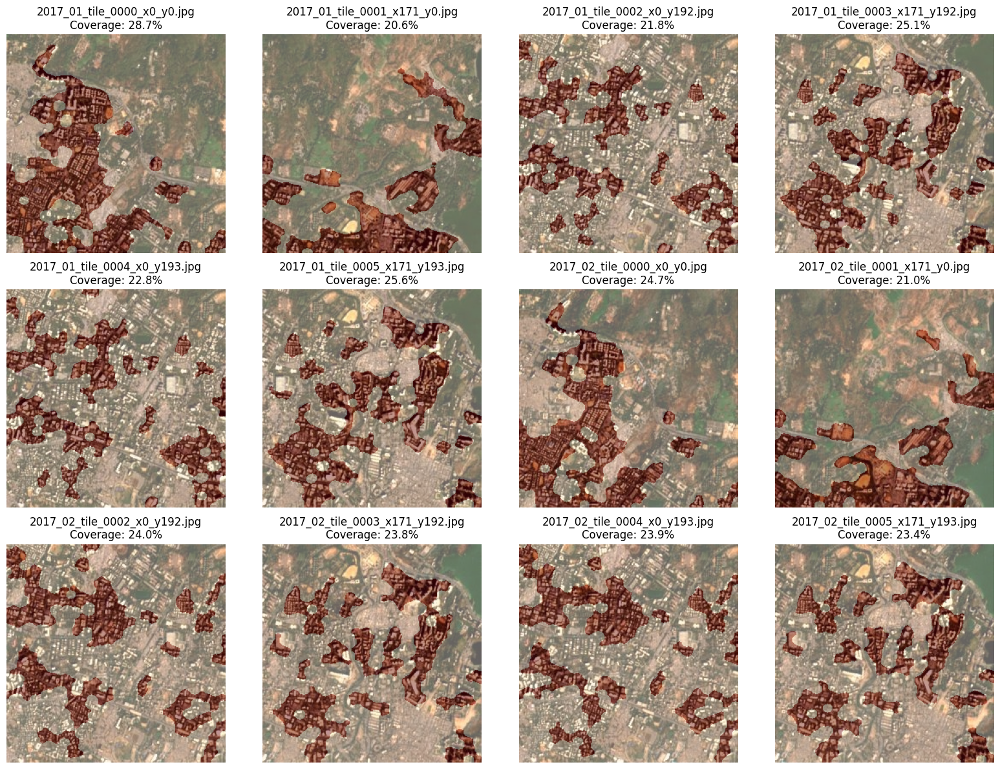

In [ ]:
# ============================================================
# STEP 11.2 — V4 VISUAL CHECK
# ============================================================

import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

TILES_DIR = "/content/mumbai_slum_dataset/tiles"
V4_MASK_DIR = "/content/mumbai_slum_dataset/pseudo_masks_v4"

# ------------------------------------------------------------
# Select 12 images from the verified dataset
# ------------------------------------------------------------

sample_paths = image_paths[:12]

plt.figure(figsize=(16, 12))

for i, image_path in enumerate(sample_paths):

    # --------------------------------------------------------
    # Load original image
    # --------------------------------------------------------

    img = cv2.imread(image_path)

    if img is None:
        continue

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # Construct corresponding mask path
    # --------------------------------------------------------

    relative_path = os.path.relpath(
        image_path,
        TILES_DIR
    )

    relative_dir = os.path.dirname(
        relative_path
    )

    base_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    mask_path = os.path.join(
        V4_MASK_DIR,
        relative_dir,
        base_name + "_mask.png"
    )

    # --------------------------------------------------------
    # Load mask
    # --------------------------------------------------------

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        print("MASK NOT FOUND:", mask_path)
        continue

    # --------------------------------------------------------
    # Convert mask to binary
    # --------------------------------------------------------

    mask = (mask > 127).astype(np.uint8)

    # --------------------------------------------------------
    # Calculate coverage
    # --------------------------------------------------------

    coverage = mask.mean() * 100

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(img)

    plt.imshow(
        mask,
        cmap="Reds",
        alpha=0.40
    )

    plt.title(
        f"{os.path.basename(image_path)}\n"
        f"Coverage: {coverage:.1f}%"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 12 — V4 VALIDATION ON 30 REPRESENTATIVE TILES
# ============================================================

v4_sample_results = []

for idx, path in enumerate(sample_paths):

    img = cv2.imread(path)

    if img is None:
        print("ERROR:", path)
        continue

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    if img.shape[:2] != (256, 256):

        img = cv2.resize(
            img,
            (256, 256),
            interpolation=cv2.INTER_AREA
        )

    # --------------------------------------------------------
    # V4 pseudo-mask
    # --------------------------------------------------------

    mask, score, threshold = (
        generate_pseudo_mask_v4(
            img
        )
    )

    coverage = (
        mask.mean() * 100
    )

    v4_sample_results.append({
        "path": path,
        "image": img,
        "mask": mask,
        "score": score,
        "threshold": threshold,
        "coverage": coverage
    })

    print(
        f"{idx+1:02d}/30 | "
        f"Threshold: {threshold:.3f} | "
        f"Coverage: {coverage:.2f}% | "
        f"{os.path.basename(path)}"
    )

print("\n==========================================")
print("V4 30-TILE VALIDATION COMPLETED")
print("==========================================")

01/30 | Threshold: 0.600 | Coverage: 28.74% | 2017_01_tile_0000_x0_y0.jpg
02/30 | Threshold: 0.578 | Coverage: 20.57% | 2017_01_tile_0001_x171_y0.jpg
03/30 | Threshold: 0.532 | Coverage: 21.76% | 2017_01_tile_0002_x0_y192.jpg
04/30 | Threshold: 0.600 | Coverage: 25.12% | 2017_01_tile_0003_x171_y192.jpg
05/30 | Threshold: 0.536 | Coverage: 22.80% | 2017_01_tile_0004_x0_y193.jpg
06/30 | Threshold: 0.600 | Coverage: 25.61% | 2017_01_tile_0005_x171_y193.jpg
07/30 | Threshold: 0.600 | Coverage: 24.69% | 2017_02_tile_0000_x0_y0.jpg
08/30 | Threshold: 0.591 | Coverage: 20.98% | 2017_02_tile_0001_x171_y0.jpg
09/30 | Threshold: 0.517 | Coverage: 23.96% | 2017_02_tile_0002_x0_y192.jpg
10/30 | Threshold: 0.595 | Coverage: 23.84% | 2017_02_tile_0003_x171_y192.jpg
11/30 | Threshold: 0.510 | Coverage: 23.95% | 2017_02_tile_0004_x0_y193.jpg
12/30 | Threshold: 0.598 | Coverage: 23.35% | 2017_02_tile_0005_x171_y193.jpg

V4 30-TILE VALIDATION COMPLETED


In [ ]:
# ============================================================
# STEP 12.1 — V4 STATISTICS
# ============================================================

v4_coverages = np.array([
    x["coverage"]
    for x in v4_sample_results
])

v4_thresholds = np.array([
    x["threshold"]
    for x in v4_sample_results
])

print("==========================================")
print("V4 VALIDATION STATISTICS")
print("==========================================")

print(
    "Minimum coverage :",
    f"{v4_coverages.min():.2f}%"
)

print(
    "Maximum coverage :",
    f"{v4_coverages.max():.2f}%"
)

print(
    "Mean coverage    :",
    f"{v4_coverages.mean():.2f}%"
)

print(
    "Median coverage  :",
    f"{np.median(v4_coverages):.2f}%"
)

print(
    "Std deviation    :",
    f"{v4_coverages.std():.2f}%"
)

print("\nThreshold statistics")

print(
    "Minimum threshold:",
    f"{v4_thresholds.min():.3f}"
)

print(
    "Maximum threshold:",
    f"{v4_thresholds.max():.3f}"
)

print(
    "Mean threshold   :",
    f"{v4_thresholds.mean():.3f}"
)

V4 VALIDATION STATISTICS
Minimum coverage : 20.57%
Maximum coverage : 28.74%
Mean coverage    : 23.78%
Median coverage  : 23.89%
Std deviation    : 2.12%

Threshold statistics
Minimum threshold: 0.510
Maximum threshold: 0.600
Mean threshold   : 0.571


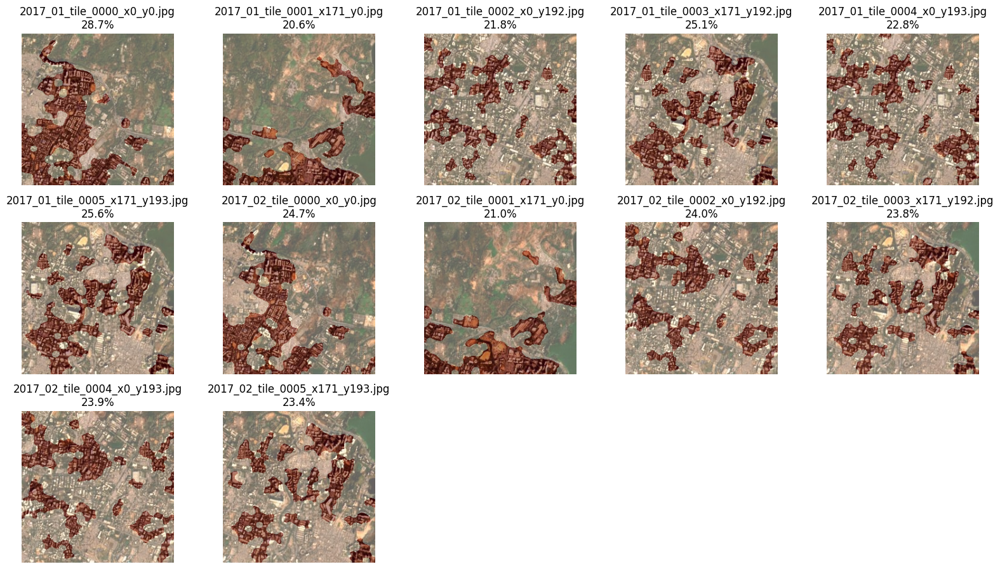

In [ ]:
# ============================================================
# STEP 12.2 — VISUAL V4 VALIDATION
# ============================================================

plt.figure(
    figsize=(16, 18)
)

for i, result in enumerate(v4_sample_results):

    plt.subplot(
        6,
        5,
        i + 1
    )

    plt.imshow(
        result["image"]
    )

    plt.imshow(
        result["mask"],
        cmap="Reds",
        alpha=0.40
    )

    plt.title(
        f"{os.path.basename(result['path'])}\n"
        f"{result['coverage']:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 13.1 — FINAL V4 DATASET STATISTICS
# ============================================================

v4_all_coverages = np.array([
    x["coverage"]
    for x in v4_all_results
])

v4_all_thresholds = np.array([
    x["threshold"]
    for x in v4_all_results
])

print("==========================================")
print("FINAL V4 DATASET STATISTICS")
print("==========================================")

print(
    "Number of masks :",
    len(v4_all_results)
)

print(
    "Minimum coverage:",
    f"{v4_all_coverages.min():.2f}%"
)

print(
    "Maximum coverage:",
    f"{v4_all_coverages.max():.2f}%"
)

print(
    "Mean coverage   :",
    f"{v4_all_coverages.mean():.2f}%"
)

print(
    "Median coverage :",
    f"{np.median(v4_all_coverages):.2f}%"
)

print(
    "Std deviation   :",
    f"{v4_all_coverages.std():.2f}%"
)

print("\nThreshold statistics")

print(
    "Minimum threshold:",
    f"{v4_all_thresholds.min():.3f}"
)

print(
    "Maximum threshold:",
    f"{v4_all_thresholds.max():.3f}"
)

print(
    "Mean threshold   :",
    f"{v4_all_thresholds.mean():.3f}"
)

FINAL V4 DATASET STATISTICS
Number of masks : 3609
Minimum coverage: 10.18%
Maximum coverage: 59.34%
Mean coverage   : 26.39%
Median coverage : 24.02%
Std deviation   : 6.56%

Threshold statistics
Minimum threshold: 0.353
Maximum threshold: 0.600
Mean threshold   : 0.576


In [ ]:
# ============================================================
# STEP 14 — AUTOMATIC PSEUDO-MASK QUALITY CONTROL
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd

qc_results = []

for idx, result in enumerate(v4_all_results):

    mask_path = result["mask_path"]

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        continue

    # --------------------------------------------------------
    # Convert to binary
    # --------------------------------------------------------

    binary = (
        mask > 127
    ).astype(np.uint8)

    h, w = binary.shape

    total_pixels = h * w

    settlement_pixels = binary.sum()

    coverage = (
        settlement_pixels /
        total_pixels
    ) * 100

    # --------------------------------------------------------
    # Connected components
    # --------------------------------------------------------

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            binary,
            connectivity=8
        )
    )

    component_areas = []

    for i in range(1, num_labels):

        area = stats[
            i,
            cv2.CC_STAT_AREA
        ]

        component_areas.append(area)

    component_areas = np.array(
        component_areas,
        dtype=np.float32
    )

    num_components = len(
        component_areas
    )

    # --------------------------------------------------------
    # Largest component
    # --------------------------------------------------------

    if num_components > 0:

        largest_component = (
            component_areas.max()
        )

        largest_component_ratio = (
            largest_component /
            settlement_pixels
        )

    else:

        largest_component = 0

        largest_component_ratio = 0

    # --------------------------------------------------------
    # Small component ratio
    # --------------------------------------------------------

    if num_components > 0:

        small_components = (
            component_areas < 150
        ).sum()

        small_component_ratio = (
            small_components /
            num_components
        )

    else:

        small_component_ratio = 0

    # --------------------------------------------------------
    # Boundary contact
    # --------------------------------------------------------

    boundary_pixels = np.concatenate([
        binary[0, :],
        binary[-1, :],
        binary[:, 0],
        binary[:, -1]
    ])

    boundary_settlement_ratio = (
        boundary_pixels.mean()
    ) * 100

    # --------------------------------------------------------
    # Image-wide settlement density
    # --------------------------------------------------------

    density_map = cv2.blur(
        binary.astype(np.float32),
        (21, 21)
    )

    mean_density = (
        density_map.mean()
    )

    # --------------------------------------------------------
    # QC score
    # --------------------------------------------------------

    qc_score = 100.0

    # --------------------------------
    # Coverage penalty
    # --------------------------------

    if coverage < 5:
        qc_score -= 30

    elif coverage < 10:
        qc_score -= 10

    elif coverage > 60:
        qc_score -= 15

    elif coverage > 70:
        qc_score -= 30

    # --------------------------------
    # Excessive fragmentation
    # --------------------------------

    if num_components > 80:
        qc_score -= 10

    elif num_components > 50:
        qc_score -= 5

    # --------------------------------
    # Excessive tiny components
    # --------------------------------

    if small_component_ratio > 0.70:
        qc_score -= 10

    elif small_component_ratio > 0.50:
        qc_score -= 5

    # --------------------------------
    # Extreme single-component dominance
    # --------------------------------

    if (
        largest_component_ratio > 0.98
        and coverage > 55
    ):
        qc_score -= 10

    # --------------------------------
    # Excessive boundary occupation
    # --------------------------------

    if boundary_settlement_ratio > 70:
        qc_score -= 10

    elif boundary_settlement_ratio > 50:
        qc_score -= 5

    qc_score = np.clip(
        qc_score,
        0,
        100
    )

    # --------------------------------------------------------
    # Quality category
    # --------------------------------------------------------

    if qc_score >= 85:

        quality = "HIGH"

    elif qc_score >= 70:

        quality = "MEDIUM"

    else:

        quality = "LOW"

    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    qc_results.append({

        "image_path":
            result["image_path"],

        "mask_path":
            result["mask_path"],

        "coverage":
            coverage,

        "threshold":
            result["threshold"],

        "num_components":
            num_components,

        "largest_component_ratio":
            largest_component_ratio,

        "small_component_ratio":
            small_component_ratio,

        "boundary_settlement_ratio":
            boundary_settlement_ratio,

        "mean_density":
            mean_density,

        "qc_score":
            qc_score,

        "quality":
            quality
    })


# ============================================================
# CREATE DATAFRAME
# ============================================================

qc_df = pd.DataFrame(
    qc_results
)

print("==========================================")
print("PSEUDO-MASK QC COMPLETED")
print("==========================================")

print(
    "Masks evaluated:",
    len(qc_df)
)

print("\nQuality distribution:")

print(
    qc_df["quality"]
    .value_counts()
)

print("\nQC score statistics:")

print(
    qc_df["qc_score"]
    .describe()
)

PSEUDO-MASK QC COMPLETED
Masks evaluated: 3609

Quality distribution:
quality
HIGH    3609
Name: count, dtype: int64

QC score statistics:
count    3609.000000
mean       99.965364
std         0.581656
min        90.000000
25%       100.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: qc_score, dtype: float64


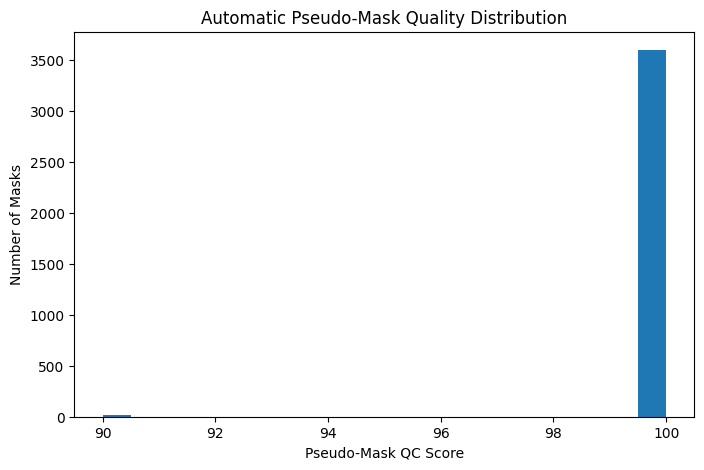

In [ ]:
# ============================================================
# STEP 14.2 — QC SCORE DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    qc_df["qc_score"],
    bins=20
)

plt.xlabel(
    "Pseudo-Mask QC Score"
)

plt.ylabel(
    "Number of Masks"
)

plt.title(
    "Automatic Pseudo-Mask Quality Distribution"
)

plt.show()

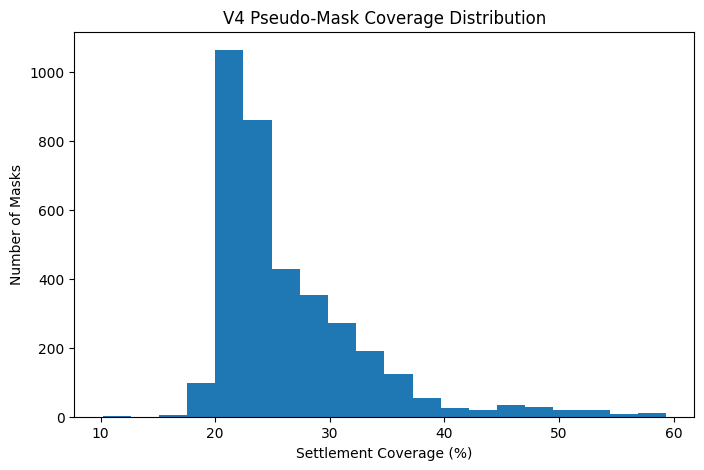

In [ ]:
# ============================================================
# STEP 14.3 — COVERAGE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    qc_df["coverage"],
    bins=20
)

plt.xlabel(
    "Settlement Coverage (%)"
)

plt.ylabel(
    "Number of Masks"
)

plt.title(
    "V4 Pseudo-Mask Coverage Distribution"
)

plt.show()

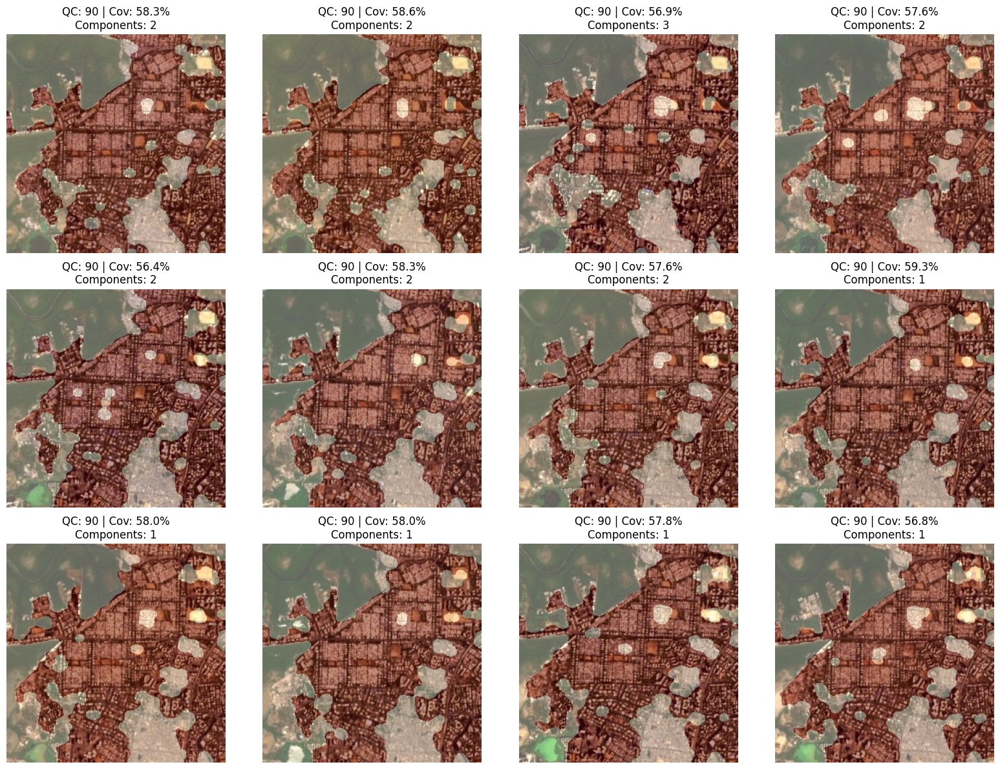

In [ ]:
# ============================================================
# STEP 14.4 — VISUALIZE LOWEST-QUALITY MASKS
# ============================================================

worst_masks = (
    qc_df
    .sort_values(
        "qc_score"
    )
    .head(12)
)

plt.figure(
    figsize=(16, 12)
)

for i, (_, row) in enumerate(
    worst_masks.iterrows()
):

    img = cv2.imread(
        row["image_path"]
    )

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(
        row["mask_path"],
        cv2.IMREAD_GRAYSCALE
    )

    mask = mask / 255.0

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(img)

    plt.imshow(
        mask,
        cmap="Reds",
        alpha=0.40
    )

    plt.title(
        f"QC: {row['qc_score']:.0f} | "
        f"Cov: {row['coverage']:.1f}%\n"
        f"Components: {row['num_components']}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 14.5 — WORST MASK REPORT
# ============================================================

print(
    worst_masks[
        [
            "image_path",
            "coverage",
            "threshold",
            "num_components",
            "largest_component_ratio",
            "small_component_ratio",
            "boundary_settlement_ratio",
            "qc_score",
            "quality"
        ]
    ].to_string(
        index=False
    )
)

                                                              image_path  coverage  threshold  num_components  largest_component_ratio  small_component_ratio  boundary_settlement_ratio  qc_score quality
/content/mumbai_slum_dataset/tiles/Kandivali/2025_01_tile_0000_x0_y0.jpg 58.314514        0.6               2                 0.995133                    0.0                  41.992188      90.0    HIGH
/content/mumbai_slum_dataset/tiles/Kandivali/2025_02_tile_0000_x0_y0.jpg 58.566284        0.6               2                 0.995336                    0.0                  42.285156      90.0    HIGH
/content/mumbai_slum_dataset/tiles/Kandivali/2025_03_tile_0000_x0_y0.jpg 56.896973        0.6               3                 0.982917                    0.0                  43.359375      90.0    HIGH
/content/mumbai_slum_dataset/tiles/Kandivali/2025_04_tile_0000_x0_y0.jpg 57.603455        0.6               2                 0.993166                    0.0                  42.578125    

In [ ]:
# ============================================================
# STEP 14B — DATA-DRIVEN PSEUDO-MASK QC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = qc_df.copy()

# ------------------------------------------------------------
# 1. Coverage percentiles
# ------------------------------------------------------------

coverage_low = df["coverage"].quantile(0.02)
coverage_high = df["coverage"].quantile(0.98)

print("Coverage 2nd percentile :", f"{coverage_low:.2f}%")
print("Coverage 98th percentile:", f"{coverage_high:.2f}%")

# ------------------------------------------------------------
# 2. Component percentiles
# ------------------------------------------------------------

components_high = df["num_components"].quantile(0.98)

print(
    "Components 98th percentile:",
    f"{components_high:.0f}"
)

# ------------------------------------------------------------
# 3. Boundary percentiles
# ------------------------------------------------------------

boundary_high = (
    df["boundary_settlement_ratio"]
    .quantile(0.98)
)

print(
    "Boundary 98th percentile:",
    f"{boundary_high:.2f}%"
)

# ------------------------------------------------------------
# 4. Create data-driven flags
# ------------------------------------------------------------

df["coverage_outlier"] = (
    (df["coverage"] < coverage_low) |
    (df["coverage"] > coverage_high)
)

df["fragmentation_outlier"] = (
    df["num_components"] >
    components_high
)

df["boundary_outlier"] = (
    df["boundary_settlement_ratio"] >
    boundary_high
)

# ------------------------------------------------------------
# 5. Component dominance
# ------------------------------------------------------------

df["dominant_component"] = (
    df["largest_component_ratio"] > 0.95
)

# ------------------------------------------------------------
# 6. Suspicion score
# ------------------------------------------------------------

df["suspicion_score"] = (
    df["coverage_outlier"].astype(int)
    +
    df["fragmentation_outlier"].astype(int)
    +
    df["boundary_outlier"].astype(int)
    +
    df["dominant_component"].astype(int)
)

# ------------------------------------------------------------
# 7. Final QC category
# ------------------------------------------------------------

def assign_qc(row):

    score = row["suspicion_score"]

    if score == 0:
        return "NORMAL"

    elif score == 1:
        return "REVIEW"

    else:
        return "SUSPICIOUS"


df["qc_category"] = df.apply(
    assign_qc,
    axis=1
)

# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

print("\n==========================================")
print("DATA-DRIVEN QC RESULTS")
print("==========================================")

print(
    df["qc_category"]
    .value_counts()
)

print("\nSuspicion score:")
print(
    df["suspicion_score"]
    .value_counts()
    .sort_index()
)

Coverage 2nd percentile : 19.79%
Coverage 98th percentile: 48.13%
Components 98th percentile: 17
Boundary 98th percentile: 41.99%

DATA-DRIVEN QC RESULTS
qc_category
NORMAL        3156
REVIEW         392
SUSPICIOUS      61
Name: count, dtype: int64

Suspicion score:
suspicion_score
0    3156
1     392
2      53
3       8
Name: count, dtype: int64


Suspicious masks: 61


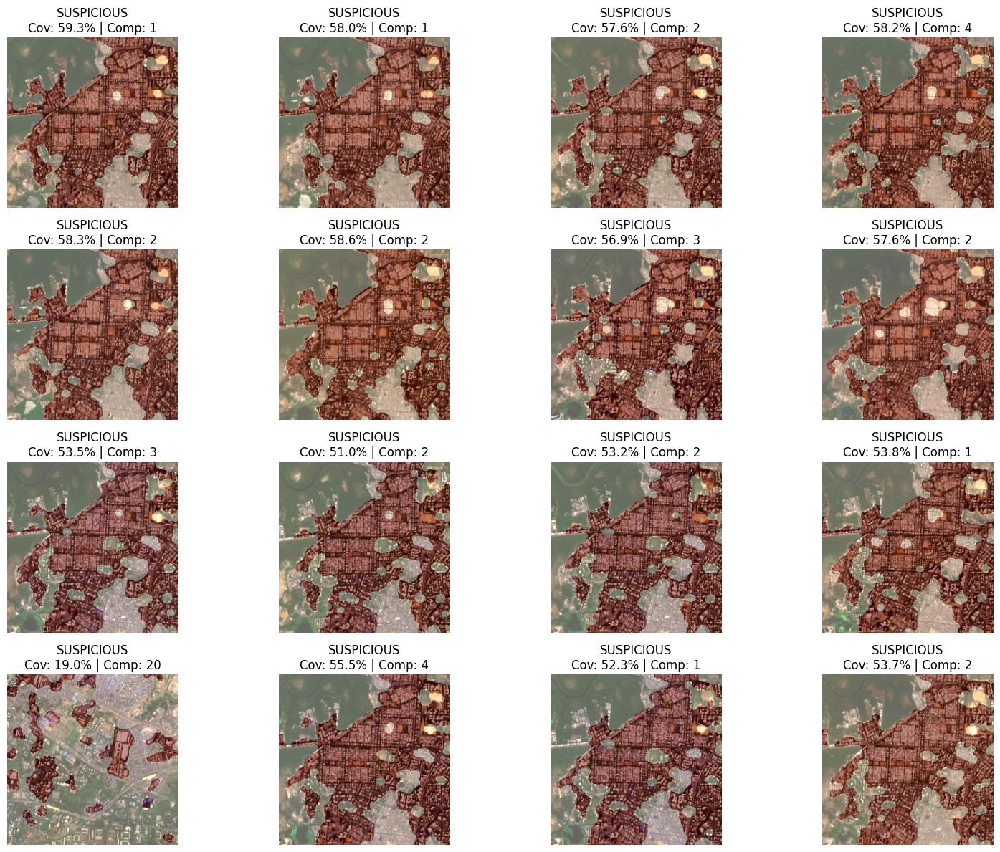

In [ ]:
# ============================================================
# STEP 14B.1 — VISUALIZE SUSPICIOUS MASKS
# ============================================================

suspicious = (
    df[
        df["qc_category"] == "SUSPICIOUS"
    ]
    .sort_values(
        "suspicion_score",
        ascending=False
    )
    .head(16)
)

print(
    "Suspicious masks:",
    len(
        df[
            df["qc_category"] == "SUSPICIOUS"
        ]
    )
)

plt.figure(
    figsize=(16, 12)
)

for i, (_, row) in enumerate(
    suspicious.iterrows()
):

    img = cv2.imread(
        row["image_path"]
    )

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(
        row["mask_path"],
        cv2.IMREAD_GRAYSCALE
    )

    mask = mask / 255.0

    plt.subplot(
        4,
        4,
        i + 1
    )

    plt.imshow(img)

    plt.imshow(
        mask,
        cmap="Reds",
        alpha=0.40
    )

    plt.title(
        f"{row['qc_category']}\n"
        f"Cov: {row['coverage']:.1f}% | "
        f"Comp: {row['num_components']}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

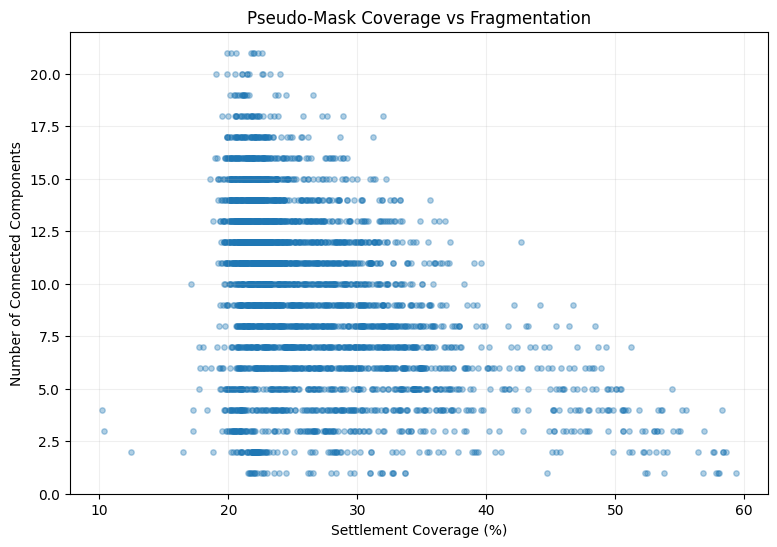

In [ ]:
# ============================================================
# STEP 14B.2 — COVERAGE VS COMPONENTS
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    df["coverage"],
    df["num_components"],
    alpha=0.35,
    s=15
)

plt.xlabel(
    "Settlement Coverage (%)"
)

plt.ylabel(
    "Number of Connected Components"
)

plt.title(
    "Pseudo-Mask Coverage vs Fragmentation"
)

plt.grid(
    alpha=0.2
)

plt.show()

In [ ]:
# ============================================================
# STEP 14B.3 — SAVE QC RESULTS
# ============================================================

QC_OUTPUT = (
    "/content/mumbai_slum_dataset/"
    "pseudo_mask_qc_v2.csv"
)

df.to_csv(
    QC_OUTPUT,
    index=False
)

print(
    "QC table saved to:"
)

print(
    QC_OUTPUT
)

QC table saved to:
/content/mumbai_slum_dataset/pseudo_mask_qc_v2.csv


In [ ]:
# ============================================================
# STEP 1 — CHECK QC DATAFRAME
# ============================================================

import pandas as pd
import os

QC_CSV = "/content/mumbai_slum_dataset/pseudo_mask_qc_v2.csv"

qc_df = pd.read_csv(QC_CSV)

print("QC dataframe shape:", qc_df.shape)
print("\nColumns:")
print(qc_df.columns.tolist())

print("\nQC categories:")
print(qc_df["qc_category"].value_counts())

print("\nFirst 5 rows:")
display(qc_df.head())

QC dataframe shape: (3609, 17)

Columns:
['image_path', 'mask_path', 'coverage', 'threshold', 'num_components', 'largest_component_ratio', 'small_component_ratio', 'boundary_settlement_ratio', 'mean_density', 'qc_score', 'quality', 'coverage_outlier', 'fragmentation_outlier', 'boundary_outlier', 'dominant_component', 'suspicion_score', 'qc_category']

QC categories:
qc_category
NORMAL        3156
REVIEW         392
SUSPICIOUS      61
Name: count, dtype: int64

First 5 rows:


,image_path,mask_path,coverage,threshold,num_components,largest_component_ratio,small_component_ratio,boundary_settlement_ratio,mean_density,qc_score,quality,coverage_outlier,fragmentation_outlier,boundary_outlier,dominant_component,suspicion_score,qc_category
0,/content/mumbai_slum_dataset/tiles/Andheri_Eas...,/content/mumbai_slum_dataset/pseudo_masks_v4/A...,28.738403,0.600000,6,0.916056,0.0,23.632812,0.287425,100.0,HIGH,False,False,False,False,0,NORMAL
1,/content/mumbai_slum_dataset/tiles/Andheri_Eas...,/content/mumbai_slum_dataset/pseudo_masks_v4/A...,20.568848,0.577718,8,0.451632,0.0,30.664062,0.205799,100.0,HIGH,False,False,False,False,0,NORMAL
2,/content/mumbai_slum_dataset/tiles/Andheri_Eas...,/content/mumbai_slum_dataset/pseudo_masks_v4/A...,21.759033,0.532307,15,0.231487,0.0,16.601562,0.217623,100.0,HIGH,False,False,False,False,0,NORMAL
3,/content/mumbai_slum_dataset/tiles/Andheri_Eas...,/content/mumbai_slum_dataset/pseudo_masks_v4/A...,25.123596,0.600000,14,0.488794,0.0,5.859375,0.251424,100.0,HIGH,False,False,False,False,0,NORMAL
4,/content/mumbai_slum_dataset/tiles/Andheri_Eas...,/content/mumbai_slum_dataset/pseudo_masks_v4/A...,22.795105,0.536061,15,0.235089,0.0,17.675781,0.227976,100.0,HIGH,False,False,False,False,0,NORMAL


In [ ]:
# ============================================================
# STEP 2 — BUILD FINAL DATASET FROM QC CSV
# ============================================================

import os
import pandas as pd

QC_CSV = "/content/mumbai_slum_dataset/pseudo_mask_qc_v2.csv"

qc_df = pd.read_csv(QC_CSV)

dataset_df = qc_df.copy()

# ------------------------------------------------------------
# Extract location from image path
# Example:
# /content/.../tiles/Andheri_East/2025_01_tile_0000_x0_y0.jpg
#                         ↑
#                       location
# ------------------------------------------------------------

dataset_df["location"] = (
    dataset_df["image_path"]
    .astype(str)
    .apply(
        lambda x: os.path.basename(
            os.path.dirname(x)
        )
    )
)

# ------------------------------------------------------------
# Verify image and mask paths
# ------------------------------------------------------------

dataset_df["image_exists"] = (
    dataset_df["image_path"]
    .astype(str)
    .apply(os.path.exists)
)

dataset_df["mask_exists"] = (
    dataset_df["mask_path"]
    .astype(str)
    .apply(os.path.exists)
)

print("==========================================")
print("FINAL DATASET")
print("==========================================")

print(
    "Total QC records:",
    len(dataset_df)
)

print(
    "Images existing:",
    dataset_df["image_exists"].sum()
)

print(
    "Masks existing:",
    dataset_df["mask_exists"].sum()
)

print("\nQC distribution:")
print(
    dataset_df["qc_category"].value_counts()
)

print(
    "\nUnique locations:",
    dataset_df["location"].nunique()
)

print(
    "\nLocations:"
)

print(
    dataset_df["location"].value_counts()
)

FINAL DATASET
Total QC records: 3609
Images existing: 3609
Masks existing: 3609

QC distribution:
qc_category
NORMAL        3156
REVIEW         392
SUSPICIOUS      61
Name: count, dtype: int64

Unique locations: 14

Locations:
location
Malad_Malvani            414
Andheri_East             408
Kandivali                276
Chembur                  272
Bandra_East              272
Antop_Hill               272
Wadala                   272
Govandi                  272
Sion_Koliwada            272
Jogeshwari               270
Mankhurd                 264
Kurla                    206
Cuffe_Parade_Backside     71
Dharavi                   68
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 3 — HIGH-CONFIDENCE TRAINING DATA
# ============================================================

train_df = dataset_df[
    (dataset_df["qc_category"] == "NORMAL") &
    (dataset_df["image_exists"]) &
    (dataset_df["mask_exists"])
].copy()

train_df = train_df.reset_index(drop=True)

print("==========================================")
print("TRAINING DATA")
print("==========================================")

print(
    "Training candidates:",
    len(train_df)
)

print("\nQC distribution:")
print(
    train_df["qc_category"].value_counts()
)

print("\nCoverage statistics:")
print(
    train_df["coverage"].describe()
)

TRAINING DATA
Training candidates: 3156

QC distribution:
qc_category
NORMAL    3156
Name: count, dtype: int64

Coverage statistics:
count    3156.000000
mean       25.736321
std         5.062601
min        19.790649
25%        22.050095
50%        23.940277
75%        28.290939
max        47.946167
Name: coverage, dtype: float64


In [ ]:
# ============================================================
# STEP 4 — SANITY CHECK
# ============================================================

if len(train_df) == 0:
    raise ValueError(
        "Training dataframe is empty. "
        "Check image/mask paths and QC categories."
    )

print("Training dataset is valid.")
print("Samples:", len(train_df))
print("Locations:", train_df["location"].nunique())

Training dataset is valid.
Samples: 3156
Locations: 14


In [ ]:
# ============================================================
# STEP 5 — GROUPED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# 80% TRAIN / 20% TEMPORARY
# ------------------------------------------------------------

gss_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    gss_1.split(
        train_df,
        groups=train_df["location"]
    )
)

train_split = train_df.iloc[
    train_idx
].reset_index(drop=True)

temp_split = train_df.iloc[
    temp_idx
].reset_index(drop=True)


# ------------------------------------------------------------
# TEMPORARY → VALIDATION + TEST
# 50% / 50%
# ------------------------------------------------------------

gss_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_2.split(
        temp_split,
        groups=temp_split["location"]
    )
)

val_split = temp_split.iloc[
    val_idx
].reset_index(drop=True)

test_split = temp_split.iloc[
    test_idx
].reset_index(drop=True)


print("==========================================")
print("GROUPED DATASET SPLIT")
print("==========================================")

print(
    "Train:",
    len(train_split)
)

print(
    "Validation:",
    len(val_split)
)

print(
    "Test:",
    len(test_split)
)

print(
    "Total:",
    len(train_split)
    + len(val_split)
    + len(test_split)
)

GROUPED DATASET SPLIT
Train: 2371
Validation: 228
Test: 557
Total: 3156


In [ ]:
# ============================================================
# STEP 6 — LOCATION LEAKAGE CHECK
# ============================================================

train_locations = set(
    train_split["location"]
)

val_locations = set(
    val_split["location"]
)

test_locations = set(
    test_split["location"]
)

print("==========================================")
print("LOCATION LEAKAGE CHECK")
print("==========================================")

print(
    "Train locations:",
    train_locations
)

print(
    "\nValidation locations:",
    val_locations
)

print(
    "\nTest locations:",
    test_locations
)

print(
    "\nTrain ∩ Validation:",
    train_locations & val_locations
)

print(
    "Train ∩ Test:",
    train_locations & test_locations
)

print(
    "Validation ∩ Test:",
    val_locations & test_locations
)

LOCATION LEAKAGE CHECK
Train locations: {'Govandi', 'Jogeshwari', 'Malad_Malvani', 'Dharavi', 'Bandra_East', 'Chembur', 'Cuffe_Parade_Backside', 'Kandivali', 'Antop_Hill', 'Sion_Koliwada', 'Wadala'}

Validation locations: {'Mankhurd'}

Test locations: {'Andheri_East', 'Kurla'}

Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()


In [ ]:
# ============================================================
# STEP 7 — SAVE DATASET SPLITS
# ============================================================

SPLIT_DIR = (
    "/content/mumbai_slum_dataset/splits"
)

os.makedirs(
    SPLIT_DIR,
    exist_ok=True
)

train_split.to_csv(
    os.path.join(
        SPLIT_DIR,
        "train.csv"
    ),
    index=False
)

val_split.to_csv(
    os.path.join(
        SPLIT_DIR,
        "validation.csv"
    ),
    index=False
)

test_split.to_csv(
    os.path.join(
        SPLIT_DIR,
        "test.csv"
    ),
    index=False
)

print("==========================================")
print("SPLITS SAVED")
print("==========================================")

print(
    "Directory:",
    SPLIT_DIR
)

print(
    "\nFiles:"
)

print("train.csv")
print("validation.csv")
print("test.csv")

SPLITS SAVED
Directory: /content/mumbai_slum_dataset/splits

Files:
train.csv
validation.csv
test.csv


In [ ]:
# ============================================================
# STEP 14 — FRESH DATA-DRIVEN QC FOR V4 PSEUDO-MASKS
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

TILES_DIR = "/content/mumbai_slum_dataset/tiles"
V4_MASK_DIR = "/content/mumbai_slum_dataset/pseudo_masks_v4"

print("=" * 60)
print("FRESH V4 PSEUDO-MASK QUALITY CONTROL")
print("=" * 60)

# ------------------------------------------------------------
# 1. Rebuild image list from scratch
# ------------------------------------------------------------

image_paths = []

for root, dirs, files in os.walk(TILES_DIR):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, file))

image_paths = sorted(set(image_paths))

print(f"Total images found: {len(image_paths)}")

assert len(image_paths) == 3609, (
    f"Expected 3609 images, but found {len(image_paths)}"
)

# ------------------------------------------------------------
# 2. Helper: map image -> corresponding V4 mask
# ------------------------------------------------------------

def get_mask_path(image_path):

    relative_path = os.path.relpath(image_path, TILES_DIR)

    relative_dir = os.path.dirname(relative_path)

    base_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    return os.path.join(
        V4_MASK_DIR,
        relative_dir,
        base_name + "_mask.png"
    )


# ------------------------------------------------------------
# 3. Calculate QC metrics
# ------------------------------------------------------------

records = []
missing_masks = []
image_errors = []
mask_errors = []

for image_path in tqdm(image_paths):

    mask_path = get_mask_path(image_path)

    # Check mask existence
    if not os.path.exists(mask_path):
        missing_masks.append(mask_path)
        continue

    # Read image
    img = cv2.imread(image_path)

    if img is None:
        image_errors.append(image_path)
        continue

    # Read mask
    mask_gray = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if mask_gray is None:
        mask_errors.append(mask_path)
        continue

    # Binary mask
    mask = (mask_gray > 127).astype(np.uint8)

    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    coverage = float(mask.mean() * 100)

    # --------------------------------------------------------
    # Connected components
    # --------------------------------------------------------

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )

    # Remove background
    component_areas = stats[1:, cv2.CC_STAT_AREA]

    if len(component_areas) > 0:

        component_areas = np.sort(
            component_areas
        )[::-1]

        num_components = len(component_areas)

        largest_component_ratio = (
            component_areas[0] /
            component_areas.sum()
        )

        # Components smaller than 0.1% of image
        small_threshold = mask.size * 0.001

        small_component_area = component_areas[
            component_areas < small_threshold
        ].sum()

        small_component_ratio = (
            small_component_area /
            component_areas.sum()
        )

    else:

        num_components = 0
        largest_component_ratio = 0.0
        small_component_ratio = 0.0

    # --------------------------------------------------------
    # Boundary settlement ratio
    # --------------------------------------------------------

    boundary_width = max(
        1,
        int(min(mask.shape) * 0.05)
    )

    boundary = np.zeros_like(mask)

    boundary[:boundary_width, :] = 1
    boundary[-boundary_width:, :] = 1
    boundary[:, :boundary_width] = 1
    boundary[:, -boundary_width:] = 1

    boundary_pixels = boundary.sum()

    if boundary_pixels > 0:
        boundary_settlement_ratio = (
            (mask * boundary).sum() /
            boundary_pixels
        )
    else:
        boundary_settlement_ratio = 0.0

    # --------------------------------------------------------
    # Settlement density
    # --------------------------------------------------------

    kernel_size = 15

    kernel = np.ones(
        (kernel_size, kernel_size),
        dtype=np.float32
    ) / (kernel_size * kernel_size)

    density_map = cv2.filter2D(
        mask.astype(np.float32),
        -1,
        kernel
    )

    mean_density = float(
        density_map[mask == 1].mean()
    ) if np.any(mask) else 0.0

    # --------------------------------------------------------
    # Save record
    # --------------------------------------------------------

    records.append({

        "image_path": image_path,

        "mask_path": mask_path,

        "coverage": coverage,

        "num_components": num_components,

        "largest_component_ratio":
            float(largest_component_ratio),

        "small_component_ratio":
            float(small_component_ratio),

        "boundary_settlement_ratio":
            float(boundary_settlement_ratio),

        "mean_density":
            mean_density
    })


# ------------------------------------------------------------
# 4. Create dataframe
# ------------------------------------------------------------

df_qc = pd.DataFrame(records)

print("\n" + "=" * 60)
print("BASIC VERIFICATION")
print("=" * 60)

print(f"Images found       : {len(image_paths)}")
print(f"QC records         : {len(df_qc)}")
print(f"Missing masks      : {len(missing_masks)}")
print(f"Image read errors  : {len(image_errors)}")
print(f"Mask read errors   : {len(mask_errors)}")


assert len(df_qc) == 3609, (
    f"QC record count mismatch: {len(df_qc)}"
)

assert len(missing_masks) == 0
assert len(image_errors) == 0
assert len(mask_errors) == 0


# ------------------------------------------------------------
# 5. Calculate DATA-DRIVEN thresholds
# ------------------------------------------------------------

coverage_low = df_qc["coverage"].quantile(0.02)
coverage_high = df_qc["coverage"].quantile(0.98)

components_high = df_qc["num_components"].quantile(0.98)

boundary_high = df_qc[
    "boundary_settlement_ratio"
].quantile(0.98)

density_low = df_qc[
    "mean_density"
].quantile(0.02)


print("\n" + "=" * 60)
print("DATA-DRIVEN QC THRESHOLDS")
print("=" * 60)

print(f"Coverage 2nd percentile  : {coverage_low:.2f}%")
print(f"Coverage 98th percentile : {coverage_high:.2f}%")
print(f"Components 98th pctile  : {components_high:.0f}")
print(f"Boundary 98th pctile    : {boundary_high:.4f}")
print(f"Density 2nd percentile  : {density_low:.4f}")


# ------------------------------------------------------------
# 6. Identify potential problems
# ------------------------------------------------------------

df_qc["coverage_outlier"] = (
    (df_qc["coverage"] < coverage_low) |
    (df_qc["coverage"] > coverage_high)
)

df_qc["fragmentation_outlier"] = (
    df_qc["num_components"] > components_high
)

df_qc["boundary_outlier"] = (
    df_qc["boundary_settlement_ratio"] > boundary_high
)

df_qc["density_outlier"] = (
    df_qc["mean_density"] < density_low
)

# Very dominant component is generally not a problem by itself,
# so we record it rather than automatically rejecting it.
df_qc["dominant_component"] = (
    df_qc["largest_component_ratio"] > 0.90
)


# ------------------------------------------------------------
# 7. Suspicion score
# ------------------------------------------------------------

df_qc["suspicion_score"] = (
    df_qc["coverage_outlier"].astype(int) +
    df_qc["fragmentation_outlier"].astype(int) +
    df_qc["boundary_outlier"].astype(int) +
    df_qc["density_outlier"].astype(int)
)


# ------------------------------------------------------------
# 8. QC categories
# ------------------------------------------------------------

def assign_qc_category(score):

    if score == 0:
        return "NORMAL"

    elif score == 1:
        return "REVIEW"

    else:
        return "SUSPICIOUS"


df_qc["qc_category"] = (
    df_qc["suspicion_score"]
    .apply(assign_qc_category)
)


# ------------------------------------------------------------
# 9. Save fresh QC
# ------------------------------------------------------------

QC_DIR = "/content/mumbai_slum_dataset"

QC_PATH = os.path.join(
    QC_DIR,
    "pseudo_mask_qc_v4_fresh.csv"
)

df_qc.to_csv(
    QC_PATH,
    index=False
)


# ------------------------------------------------------------
# 10. Final QC report
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL FRESH QC REPORT")
print("=" * 60)

print(
    df_qc["qc_category"]
    .value_counts()
    .sort_index()
)

print("\nSuspicion score distribution:")
print(
    df_qc["suspicion_score"]
    .value_counts()
    .sort_index()
)

print("\nCoverage statistics:")
print(
    df_qc["coverage"].describe()
)

print("\nQC file saved:")
print(QC_PATH)

print("\n" + "=" * 60)
print("FRESH QC COMPLETED SUCCESSFULLY")
print("=" * 60)

FRESH V4 PSEUDO-MASK QUALITY CONTROL
Total images found: 3609


100%|██████████| 3609/3609 [00:22<00:00, 162.85it/s]


BASIC VERIFICATION
Images found       : 3609
QC records         : 3609
Missing masks      : 0
Image read errors  : 0
Mask read errors   : 0

DATA-DRIVEN QC THRESHOLDS
Coverage 2nd percentile  : 19.79%
Coverage 98th percentile : 48.13%
Components 98th pctile  : 17
Boundary 98th pctile    : 0.4268
Density 2nd percentile  : 0.7022

FINAL FRESH QC REPORT
qc_category
NORMAL        3286
REVIEW         285
SUSPICIOUS      38
Name: count, dtype: int64

Suspicion score distribution:
suspicion_score
0    3286
1     285
2      38
Name: count, dtype: int64

Coverage statistics:
count    3609.000000
mean       26.388374
std         6.565172
min        10.177612
25%        21.969604
50%        24.023438
75%        29.051208
max        59.344482
Name: coverage, dtype: float64

QC file saved:
/content/mumbai_slum_dataset/pseudo_mask_qc_v4_fresh.csv

FRESH QC COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# STEP 15 — FINAL LEAKAGE-FREE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

QC_PATH = "/content/mumbai_slum_dataset/pseudo_mask_qc_v4_fresh.csv"

SPLIT_DIR = "/content/mumbai_slum_dataset/splits"
os.makedirs(SPLIT_DIR, exist_ok=True)

print("=" * 60)
print("CREATING FINAL LEAKAGE-FREE DATASET SPLIT")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load fresh QC
# ------------------------------------------------------------

df = pd.read_csv(QC_PATH)

print(f"Total QC records: {len(df)}")

assert len(df) == 3609

# ------------------------------------------------------------
# 2. Extract location from image path
# ------------------------------------------------------------

df["location"] = (
    df["image_path"]
    .apply(
        lambda x: os.path.basename(
            os.path.dirname(x)
        )
    )
)

print(f"Unique locations: {df['location'].nunique()}")

print("\nLocations:")
print(
    sorted(
        df["location"].unique()
    )
)

# ------------------------------------------------------------
# 3. Use ONLY NORMAL pseudo-masks
# ------------------------------------------------------------

df_normal = df[
    df["qc_category"] == "NORMAL"
].copy()

df_normal = df_normal.reset_index(drop=True)

print("\n" + "=" * 60)
print("NORMAL DATASET")
print("=" * 60)

print(f"Normal samples: {len(df_normal)}")

# ------------------------------------------------------------
# 4. Verify every image has a corresponding mask
# ------------------------------------------------------------

missing_masks = []

for mask_path in df_normal["mask_path"]:

    if not os.path.exists(mask_path):
        missing_masks.append(mask_path)

print(f"Missing masks: {len(missing_masks)}")

assert len(missing_masks) == 0

# ------------------------------------------------------------
# 5. GROUPED SPLIT BY LOCATION
#
# IMPORTANT:
# Tiles from the same geographical location must never
# appear in different splits.
# ------------------------------------------------------------

groups = df_normal["location"]

# First split:
# 80% development
# 20% final test

gss_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    gss_1.split(
        df_normal,
        groups=groups
    )
)

df_train_val = df_normal.iloc[
    train_val_idx
].copy()

df_test = df_normal.iloc[
    test_idx
].copy()

# ------------------------------------------------------------
# 6. Split development set into train + validation
#
# 87.5% train
# 12.5% validation
#
# Overall approximately:
# Train      70%
# Validation 10%
# Test       20%
# ------------------------------------------------------------

gss_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.125,
    random_state=42
)

train_idx, val_idx = next(
    gss_2.split(
        df_train_val,
        groups=df_train_val["location"]
    )
)

df_train = df_train_val.iloc[
    train_idx
].copy()

df_val = df_train_val.iloc[
    val_idx
].copy()

# ------------------------------------------------------------
# 7. Reset indexes
# ------------------------------------------------------------

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# ------------------------------------------------------------
# 8. Verify location leakage
# ------------------------------------------------------------

train_locations = set(
    df_train["location"]
)

val_locations = set(
    df_val["location"]
)

test_locations = set(
    df_test["location"]
)

print("\n" + "=" * 60)
print("LOCATION LEAKAGE CHECK")
print("=" * 60)

print("Train locations:")
print(sorted(train_locations))

print("\nValidation locations:")
print(sorted(val_locations))

print("\nTest locations:")
print(sorted(test_locations))

print("\nTrain ∩ Validation:")
print(train_locations & val_locations)

print("\nTrain ∩ Test:")
print(train_locations & test_locations)

print("\nValidation ∩ Test:")
print(val_locations & test_locations)

assert len(
    train_locations & val_locations
) == 0

assert len(
    train_locations & test_locations
) == 0

assert len(
    val_locations & test_locations
) == 0

print("\nSTATUS: NO LOCATION LEAKAGE")


# ------------------------------------------------------------
# 9. Dataset size verification
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL DATASET SIZES")
print("=" * 60)

print(f"Train      : {len(df_train)}")
print(f"Validation : {len(df_val)}")
print(f"Test       : {len(df_test)}")
print(f"Total      : {len(df_train) + len(df_val) + len(df_test)}")

assert (
    len(df_train)
    + len(df_val)
    + len(df_test)
    == len(df_normal)
)

# ------------------------------------------------------------
# 10. Coverage statistics
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COVERAGE DISTRIBUTION")
print("=" * 60)

print("\nTRAIN")
print(df_train["coverage"].describe())

print("\nVALIDATION")
print(df_val["coverage"].describe())

print("\nTEST")
print(df_test["coverage"].describe())

# ------------------------------------------------------------
# 11. Location distribution
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LOCATION DISTRIBUTION")
print("=" * 60)

print("\nTRAIN:")
print(
    df_train["location"]
    .value_counts()
    .sort_index()
)

print("\nVALIDATION:")
print(
    df_val["location"]
    .value_counts()
    .sort_index()
)

print("\nTEST:")
print(
    df_test["location"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 12. Save FINAL splits
# ------------------------------------------------------------

train_path = os.path.join(
    SPLIT_DIR,
    "train.csv"
)

val_path = os.path.join(
    SPLIT_DIR,
    "validation.csv"
)

test_path = os.path.join(
    SPLIT_DIR,
    "test.csv"
)

df_train.to_csv(
    train_path,
    index=False
)

df_val.to_csv(
    val_path,
    index=False
)

df_test.to_csv(
    test_path,
    index=False
)

print("\n" + "=" * 60)
print("FINAL SPLITS SAVED")
print("=" * 60)

print(train_path)
print(val_path)
print(test_path)

print("\n" + "=" * 60)
print("FINAL SPLIT CREATION SUCCESSFUL")
print("=" * 60)

CREATING FINAL LEAKAGE-FREE DATASET SPLIT
Total QC records: 3609
Unique locations: 14

Locations:
['Andheri_East', 'Antop_Hill', 'Bandra_East', 'Chembur', 'Cuffe_Parade_Backside', 'Dharavi', 'Govandi', 'Jogeshwari', 'Kandivali', 'Kurla', 'Malad_Malvani', 'Mankhurd', 'Sion_Koliwada', 'Wadala']

NORMAL DATASET
Normal samples: 3286
Missing masks: 0

LOCATION LEAKAGE CHECK
Train locations:
['Bandra_East', 'Chembur', 'Cuffe_Parade_Backside', 'Dharavi', 'Jogeshwari', 'Kandivali', 'Malad_Malvani', 'Sion_Koliwada', 'Wadala']

Validation locations:
['Antop_Hill', 'Govandi']

Test locations:
['Andheri_East', 'Kurla', 'Mankhurd']

Train ∩ Validation:
set()

Train ∩ Test:
set()

Validation ∩ Test:
set()

STATUS: NO LOCATION LEAKAGE

FINAL DATASET SIZES
Train      : 1941
Validation : 543
Test       : 802
Total      : 3286

COVERAGE DISTRIBUTION

TRAIN
count    1941.000000
mean       26.288009
std         5.692345
min        19.790649
25%        22.132874
50%        23.979187
75%        29.344177
ma

In [ ]:
# ============================================================
# STEP 16 — SEGMENTATION DATASET & DATALOADERS
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("STEP 16 — SEGMENTATION DATASET SETUP")
print("=" * 60)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

SPLIT_DIR = "/content/mumbai_slum_dataset/splits"

TRAIN_CSV = os.path.join(
    SPLIT_DIR, "train.csv"
)

VAL_CSV = os.path.join(
    SPLIT_DIR, "validation.csv"
)

TEST_CSV = os.path.join(
    SPLIT_DIR, "test.csv"
)

# ------------------------------------------------------------
# 2. Load split files
# ------------------------------------------------------------

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print(f"Train samples      : {len(train_df)}")
print(f"Validation samples : {len(val_df)}")
print(f"Test samples       : {len(test_df)}")

# ------------------------------------------------------------
# 3. Basic verification
# ------------------------------------------------------------

required_columns = [
    "image_path",
    "mask_path",
    "location"
]

for column in required_columns:

    assert column in train_df.columns, \
        f"Missing column in train.csv: {column}"

    assert column in val_df.columns, \
        f"Missing column in validation.csv: {column}"

    assert column in test_df.columns, \
        f"Missing column in test.csv: {column}"

print("\nRequired columns verified.")

# ------------------------------------------------------------
# 4. Verify files exist
# ------------------------------------------------------------

def verify_files(df, split_name):

    missing_images = []
    missing_masks = []

    for _, row in df.iterrows():

        if not os.path.exists(row["image_path"]):
            missing_images.append(row["image_path"])

        if not os.path.exists(row["mask_path"]):
            missing_masks.append(row["mask_path"])

    print(f"\n{split_name}")
    print(f"Missing images: {len(missing_images)}")
    print(f"Missing masks : {len(missing_masks)}")

    assert len(missing_images) == 0
    assert len(missing_masks) == 0


verify_files(train_df, "TRAIN")
verify_files(val_df, "VALIDATION")
verify_files(test_df, "TEST")

# ------------------------------------------------------------
# 5. Dataset class
# ------------------------------------------------------------

class SettlementSegmentationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        augment=False
    ):

        self.df = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["image_path"]
        mask_path = row["mask_path"]

        # ----------------------------------------------------
        # Read image
        # ----------------------------------------------------

        image = cv2.imread(
            image_path,
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise RuntimeError(
                f"Could not read image: {image_path}"
            )

        # BGR -> RGB
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # ----------------------------------------------------
        # Read mask
        # ----------------------------------------------------

        mask = cv2.imread(
            mask_path,
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            raise RuntimeError(
                f"Could not read mask: {mask_path}"
            )

        # ----------------------------------------------------
        # Ensure 256 x 256
        # ----------------------------------------------------

        image = cv2.resize(
            image,
            (256, 256),
            interpolation=cv2.INTER_LINEAR
        )

        mask = cv2.resize(
            mask,
            (256, 256),
            interpolation=cv2.INTER_NEAREST
        )

        # ----------------------------------------------------
        # Binary mask
        # ----------------------------------------------------

        mask = (
            mask > 127
        ).astype(np.float32)

        # ----------------------------------------------------
        # Data augmentation
        #
        # IMPORTANT:
        # Only training dataset will have augment=True.
        # ----------------------------------------------------

        if self.augment:

            # Horizontal flip
            if np.random.random() < 0.5:

                image = np.fliplr(
                    image
                ).copy()

                mask = np.fliplr(
                    mask
                ).copy()

            # Vertical flip
            if np.random.random() < 0.5:

                image = np.flipud(
                    image
                ).copy()

                mask = np.flipud(
                    mask
                ).copy()

        # ----------------------------------------------------
        # Normalize image
        # ----------------------------------------------------

        image = image.astype(
            np.float32
        ) / 255.0

        # ----------------------------------------------------
        # HWC -> CHW
        # ----------------------------------------------------

        image = np.transpose(
            image,
            (2, 0, 1)
        )

        # ----------------------------------------------------
        # Convert to tensors
        # ----------------------------------------------------

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        )

        # Add channel dimension to mask
        mask = mask.unsqueeze(0)

        return image, mask


# ------------------------------------------------------------
# 6. Create datasets
# ------------------------------------------------------------

train_dataset = SettlementSegmentationDataset(
    train_df,
    augment=True
)

val_dataset = SettlementSegmentationDataset(
    val_df,
    augment=False
)

test_dataset = SettlementSegmentationDataset(
    test_df,
    augment=False
)

print("\nDatasets created successfully.")

# ------------------------------------------------------------
# 7. Create DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 16

NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("\nDataLoaders created.")

# ------------------------------------------------------------
# 8. Inspect one batch
# ------------------------------------------------------------

images, masks = next(
    iter(train_loader)
)

print("\n" + "=" * 60)
print("BATCH VERIFICATION")
print("=" * 60)

print("Image tensor shape :", images.shape)
print("Mask tensor shape  :", masks.shape)

print(
    "Image dtype        :",
    images.dtype
)

print(
    "Mask dtype         :",
    masks.dtype
)

print(
    "Image min/max      :",
    images.min().item(),
    images.max().item()
)

print(
    "Mask unique values :",
    torch.unique(masks)
)

# ------------------------------------------------------------
# 9. Assertions
# ------------------------------------------------------------

assert images.ndim == 4
assert masks.ndim == 4

assert images.shape[1] == 3
assert masks.shape[1] == 1

assert images.shape[2:] == (256, 256)
assert masks.shape[2:] == (256, 256)

assert images.dtype == torch.float32
assert masks.dtype == torch.float32

assert images.min() >= 0
assert images.max() <= 1

assert set(
    torch.unique(masks).cpu().numpy()
).issubset({0.0, 1.0})

print("\n" + "=" * 60)
print("STEP 16 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 16 — SEGMENTATION DATASET SETUP
Train samples      : 1941
Validation samples : 543
Test samples       : 802

Required columns verified.

TRAIN
Missing images: 0
Missing masks : 0

VALIDATION
Missing images: 0
Missing masks : 0

TEST
Missing images: 0
Missing masks : 0

Datasets created successfully.

DataLoaders created.

BATCH VERIFICATION
Image tensor shape : torch.Size([16, 3, 256, 256])
Mask tensor shape  : torch.Size([16, 1, 256, 256])
Image dtype        : torch.float32
Mask dtype         : torch.float32
Image min/max      : 0.0 1.0
Mask unique values : tensor([0., 1.])

STEP 16 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# STEP 17 — U-NET MODEL, LOSS FUNCTIONS & GPU SETUP
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 60)
print("STEP 17 — U-NET SETUP")
print("=" * 60)

# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "CUDA version:",
        torch.version.cuda
    )
else:
    print("WARNING: CUDA is not available.")
    print("Training will run on CPU and may be slow.")


# ------------------------------------------------------------
# 2. Double Convolution Block
# ------------------------------------------------------------

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )

    def forward(self, x):

        return self.block(x)


# ------------------------------------------------------------
# 3. U-Net
# ------------------------------------------------------------

class UNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):

        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(
            in_channels,
            32
        )

        self.enc2 = DoubleConv(
            32,
            64
        )

        self.enc3 = DoubleConv(
            64,
            128
        )

        self.enc4 = DoubleConv(
            128,
            256
        )

        # Bottleneck
        self.bottleneck = DoubleConv(
            256,
            512
        )

        # Pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            512,
            256
        )

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )

        # Output
        self.output = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )


    def forward(self, x):

        # ---------------- Encoder ----------------

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        # ---------------- Bottleneck ----------------

        b = self.bottleneck(
            self.pool(e4)
        )

        # ---------------- Decoder ----------------

        d4 = self.up4(b)

        d4 = torch.cat(
            [d4, e4],
            dim=1
        )

        d4 = self.dec4(d4)

        d3 = self.up3(d4)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.output(d1)


# ------------------------------------------------------------
# 4. Create model
# ------------------------------------------------------------

model = UNet(
    in_channels=3,
    out_channels=1
)

model = model.to(device)

print("\nModel created successfully.")


# ------------------------------------------------------------
# 5. Parameter count
# ------------------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Total parameters     : {total_parameters:,}"
)

print(
    f"Trainable parameters : {trainable_parameters:,}"
)


# ------------------------------------------------------------
# 6. Dice Loss
# ------------------------------------------------------------

class DiceLoss(nn.Module):

    def __init__(
        self,
        smooth=1.0
    ):

        super().__init__()

        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probabilities = torch.sigmoid(
            logits
        )

        probabilities = probabilities.contiguous().view(
            probabilities.size(0),
            -1
        )

        targets = targets.contiguous().view(
            targets.size(0),
            -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        dice = (
            2.0 * intersection
            + self.smooth
        ) / (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
            + self.smooth
        )

        return 1.0 - dice.mean()


# ------------------------------------------------------------
# 7. Combined BCE + Dice Loss
# ------------------------------------------------------------

bce_loss = nn.BCEWithLogitsLoss()

dice_loss = DiceLoss()


def combined_loss(
    logits,
    targets
):

    bce = bce_loss(
        logits,
        targets
    )

    dice = dice_loss(
        logits,
        targets
    )

    return bce + dice


# ------------------------------------------------------------
# 8. Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# 9. Test forward pass
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    sample_images, sample_masks = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(
        device
    )

    sample_masks = sample_masks.to(
        device
    )

    sample_outputs = model(
        sample_images
    )

print("\n" + "=" * 60)
print("FORWARD PASS CHECK")
print("=" * 60)

print(
    "Input shape :",
    sample_images.shape
)

print(
    "Target shape:",
    sample_masks.shape
)

print(
    "Output shape:",
    sample_outputs.shape
)

print(
    "Output dtype:",
    sample_outputs.dtype
)

# ------------------------------------------------------------
# 10. Assertions
# ------------------------------------------------------------

assert sample_outputs.shape == sample_masks.shape

assert sample_outputs.shape[1] == 1

assert sample_outputs.shape[2:] == (
    256,
    256
)

print("\n" + "=" * 60)
print("STEP 17 COMPLETED SUCCESSFULLY")
print("=" * 60)

STEP 17 — U-NET SETUP
Device: cuda
GPU: Tesla T4
CUDA version: 13.0

Model created successfully.
Total parameters     : 7,763,041
Trainable parameters : 7,763,041

FORWARD PASS CHECK
Input shape : torch.Size([16, 3, 256, 256])
Target shape: torch.Size([16, 1, 256, 256])
Output shape: torch.Size([16, 1, 256, 256])
Output dtype: torch.float32

STEP 17 COMPLETED SUCCESSFULLY


STEP 18 — U-NET TRAINING
Epochs           : 30
Early stop       : 7 epochs
Learning rate     : 1e-4
Device            : cuda

EPOCH 1/30


Validation: 100%|██████████| 34/34 [00:03<00:00,  9.91it/s, dice=0.7029, iou=0.5460, loss=0.7917]



Epoch Summary
Train Loss : 0.8779
Val Loss   : 0.7460
Train Dice : 0.6927
Val Dice   : 0.7488
Train IoU  : 0.5560
Val IoU    : 0.6097
LR         : 0.000100

✓ Best model saved.

EPOCH 2/30


Validation: 100%|██████████| 34/34 [00:03<00:00,  9.74it/s, dice=0.7123, iou=0.5567, loss=0.7297]



Epoch Summary
Train Loss : 0.6889
Val Loss   : 0.6842
Train Dice : 0.8035
Val Dice   : 0.7550
Train IoU  : 0.6791
Val IoU    : 0.6127
LR         : 0.000100

✓ Best model saved.

EPOCH 3/30


Validation: 100%|██████████| 34/34 [00:03<00:00,  9.75it/s, dice=0.6449, iou=0.4790, loss=0.7773]


... (21 outputs left out)

Validation: 100%|██████████| 34/34 [00:03<00:00,  9.38it/s, dice=0.7306, iou=0.5792, loss=0.7051]



Epoch Summary
Train Loss : 0.2965
Val Loss   : 0.4890
Train Dice : 0.8939
Val Dice   : 0.8012
Train IoU  : 0.8110
Val IoU    : 0.6754
LR         : 0.000025

No improvement (6/7)

EPOCH 15/30


Validation: 100%|██████████| 34/34 [00:03<00:00,  9.36it/s, dice=0.7380, iou=0.5880, loss=0.6928]



Epoch Summary
Train Loss : 0.2818
Val Loss   : 0.4701
Train Dice : 0.8999
Val Dice   : 0.8106
Train IoU  : 0.8206
Val IoU    : 0.6882
LR         : 0.000025

No improvement (7/7)

Early stopping triggered.

TRAINING COMPLETED
Best validation loss: 0.4667
Best model: /content/mumbai_slum_dataset/best_unet_v4_refinement.pth
History: /content/mumbai_slum_dataset/unet_training_history.csv


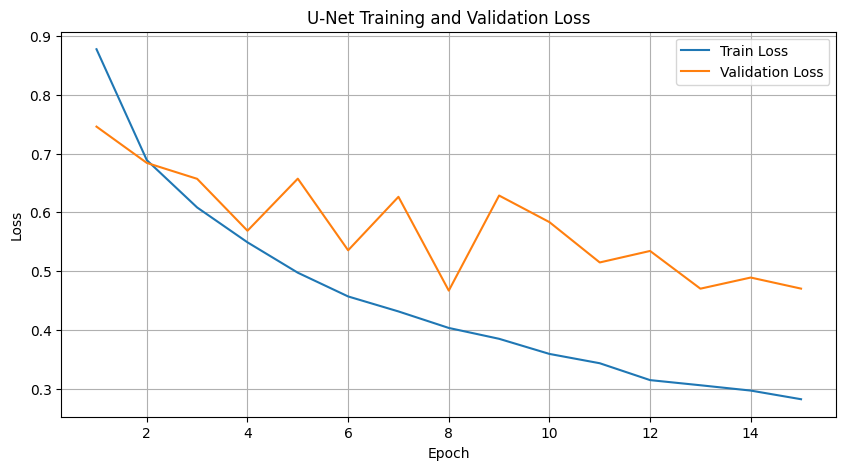

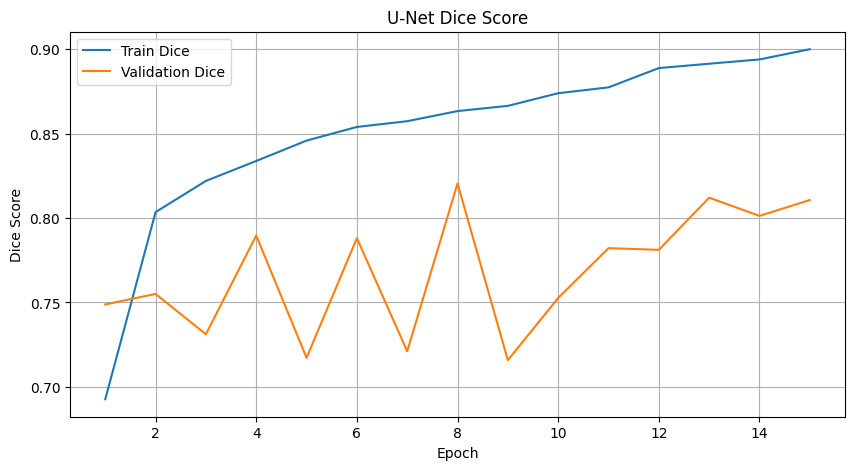

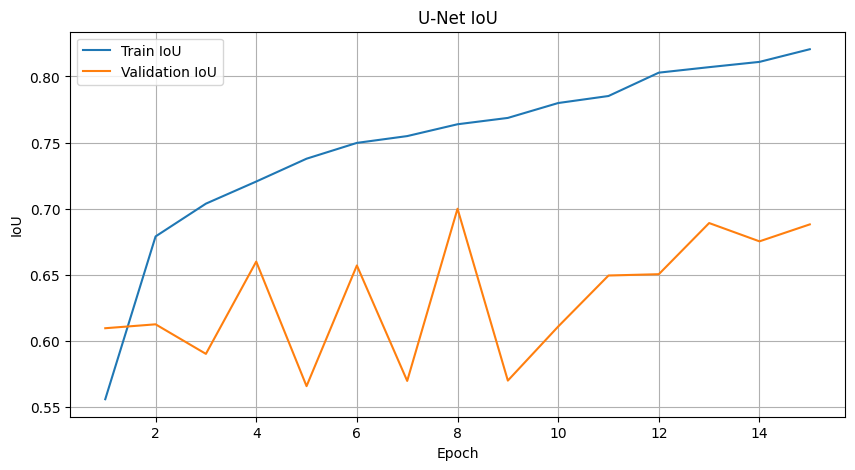


STEP 18 COMPLETED


In [ ]:
# ============================================================
# STEP 18 — U-NET TRAINING LOOP
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

# ------------------------------------------------------------
# 1. Training configuration
# ------------------------------------------------------------

NUM_EPOCHS = 30

PATIENCE = 7

BEST_MODEL_PATH = (
    "/content/mumbai_slum_dataset/"
    "best_unet_v4_refinement.pth"
)

HISTORY_PATH = (
    "/content/mumbai_slum_dataset/"
    "unet_training_history.csv"
)

print("=" * 60)
print("STEP 18 — U-NET TRAINING")
print("=" * 60)

print(f"Epochs           : {NUM_EPOCHS}")
print(f"Early stop       : {PATIENCE} epochs")
print(f"Learning rate     : 1e-4")
print(f"Device            : {device}")


# ------------------------------------------------------------
# 2. Dice / IoU metric
# ------------------------------------------------------------

def calculate_metrics(
    logits,
    targets,
    threshold=0.5
):

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.view(
        predictions.size(0),
        -1
    )

    targets = targets.view(
        targets.size(0),
        -1
    )

    intersection = (
        predictions * targets
    ).sum(dim=1)

    prediction_area = predictions.sum(
        dim=1
    )

    target_area = targets.sum(
        dim=1
    )

    union = (
        prediction_area
        + target_area
        - intersection
    )

    # Dice
    dice = (
        2 * intersection + 1e-7
    ) / (
        prediction_area
        + target_area
        + 1e-7
    )

    # IoU
    iou = (
        intersection + 1e-7
    ) / (
        union + 1e-7
    )

    return (
        dice.mean().item(),
        iou.mean().item()
    )


# ------------------------------------------------------------
# 3. Optimizer / scheduler
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# 4. Training history
# ------------------------------------------------------------

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],
    "learning_rate": []
}


# ------------------------------------------------------------
# 5. Early stopping variables
# ------------------------------------------------------------

best_val_loss = float("inf")

epochs_without_improvement = 0


# ------------------------------------------------------------
# 6. Training loop
# ------------------------------------------------------------

for epoch in range(NUM_EPOCHS):

    print("\n" + "=" * 60)
    print(
        f"EPOCH {epoch + 1}/{NUM_EPOCHS}"
    )
    print("=" * 60)

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss_total = 0.0
    train_dice_total = 0.0
    train_iou_total = 0.0

    train_batches = 0

    train_bar = tqdm(
        train_loader,
        desc="Training"
    )

    for images, masks in train_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(
            images
        )

        loss = combined_loss(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        dice, iou = calculate_metrics(
            outputs.detach(),
            masks
        )

        train_loss_total += loss.item()
        train_dice_total += dice
        train_iou_total += iou

        train_batches += 1

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            dice=f"{dice:.4f}",
            iou=f"{iou:.4f}"
        )

    train_loss = (
        train_loss_total /
        train_batches
    )

    train_dice = (
        train_dice_total /
        train_batches
    )

    train_iou = (
        train_iou_total /
        train_batches
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss_total = 0.0
    val_dice_total = 0.0
    val_iou_total = 0.0

    val_batches = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc="Validation"
        )

        for images, masks in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            outputs = model(
                images
            )

            loss = combined_loss(
                outputs,
                masks
            )

            dice, iou = calculate_metrics(
                outputs,
                masks
            )

            val_loss_total += loss.item()
            val_dice_total += dice
            val_iou_total += iou

            val_batches += 1

            val_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                dice=f"{dice:.4f}",
                iou=f"{iou:.4f}"
            )

    val_loss = (
        val_loss_total /
        val_batches
    )

    val_dice = (
        val_dice_total /
        val_batches
    )

    val_iou = (
        val_iou_total /
        val_batches
    )


    # ========================================================
    # LEARNING RATE SCHEDULER
    # ========================================================

    scheduler.step(
        val_loss
    )

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history["epoch"].append(
        epoch + 1
    )

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["train_dice"].append(
        train_dice
    )

    history["val_dice"].append(
        val_dice
    )

    history["train_iou"].append(
        train_iou
    )

    history["val_iou"].append(
        val_iou
    )

    history["learning_rate"].append(
        current_lr
    )


    # ========================================================
    # PRINT EPOCH SUMMARY
    # ========================================================

    print("\nEpoch Summary")

    print(
        f"Train Loss : {train_loss:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f}"
    )

    print(
        f"Train Dice : {train_dice:.4f}"
    )

    print(
        f"Val Dice   : {val_dice:.4f}"
    )

    print(
        f"Train IoU  : {train_iou:.4f}"
    )

    print(
        f"Val IoU    : {val_iou:.4f}"
    )

    print(
        f"LR         : {current_lr:.6f}"
    )


    # ========================================================
    # BEST MODEL CHECKPOINT
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            BEST_MODEL_PATH
        )

        print(
            "\n✓ Best model saved."
        )

    else:

        epochs_without_improvement += 1

        print(
            f"\nNo improvement "
            f"({epochs_without_improvement}/"
            f"{PATIENCE})"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print(
            "\nEarly stopping triggered."
        )

        break


# ------------------------------------------------------------
# 7. Save history
# ------------------------------------------------------------

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print(
    f"Best validation loss: "
    f"{best_val_loss:.4f}"
)

print(
    f"Best model: {BEST_MODEL_PATH}"
)

print(
    f"History: {HISTORY_PATH}"
)


# ============================================================
# 8. Plot training curves
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_dice"],
    label="Train Dice"
)

plt.plot(
    history_df["epoch"],
    history_df["val_dice"],
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("U-Net Dice Score")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_iou"],
    label="Train IoU"
)

plt.plot(
    history_df["epoch"],
    history_df["val_iou"],
    label="Validation IoU"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("U-Net IoU")
plt.legend()
plt.grid(True)
plt.show()


print("\n" + "=" * 60)
print("STEP 18 COMPLETED")
print("=" * 60)

STEP 19 — VISUAL MASK REFINEMENT CHECK
Best checkpoint epoch: 8
Best validation loss: 0.4667259305715561
Best validation Dice: 0.8204512210453258
Best validation IoU: 0.7000262772335726

Validation locations:
['Antop_Hill', 'Govandi']

Total visual samples: 6


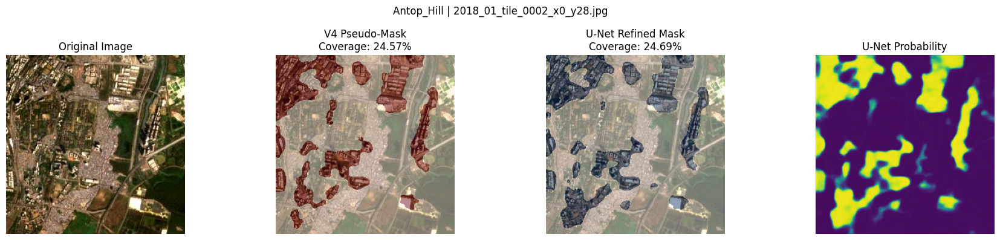

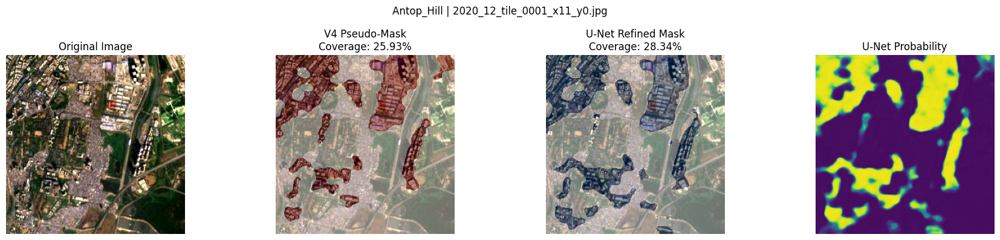

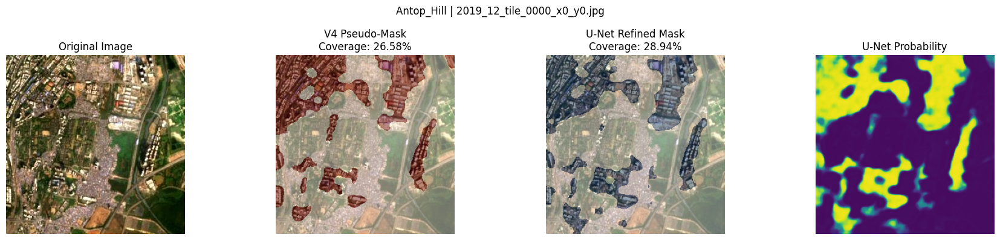

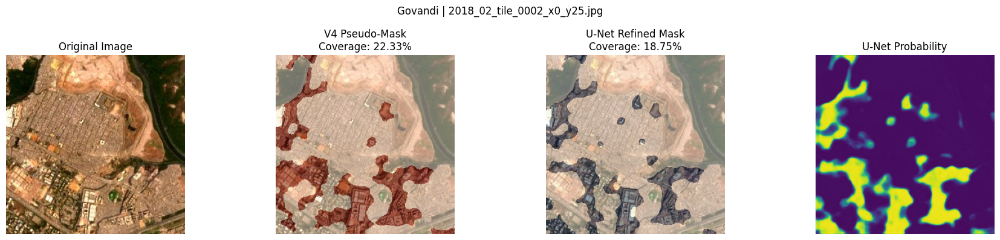

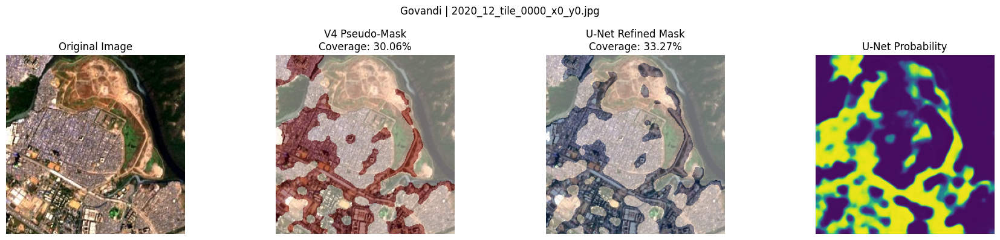

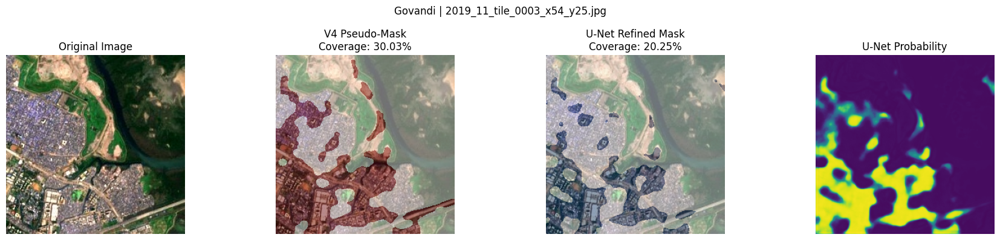


STEP 19 VISUAL CHECK COMPLETED


In [ ]:
# ============================================================
# STEP 19 — V4 PSEUDO-MASK vs U-NET REFINED MASK
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 60)
print("STEP 19 — VISUAL MASK REFINEMENT CHECK")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load BEST model
# ------------------------------------------------------------

BEST_MODEL_PATH = (
    "/content/mumbai_slum_dataset/"
    "best_unet_v4_refinement.pth"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print(
    "Best checkpoint epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation loss:",
    checkpoint["val_loss"]
)

print(
    "Best validation Dice:",
    checkpoint["val_dice"]
)

print(
    "Best validation IoU:",
    checkpoint["val_iou"]
)

# ------------------------------------------------------------
# 2. Use validation samples from different locations
# ------------------------------------------------------------

locations = sorted(
    val_df["location"].unique()
)

print("\nValidation locations:")
print(locations)

samples = []

for location in locations:

    location_df = val_df[
        val_df["location"] == location
    ]

    # Take up to 3 samples per location
    samples.extend(
        location_df
        .sample(
            n=min(3, len(location_df)),
            random_state=42
        )["image_path"].tolist()
    )

print(
    f"\nTotal visual samples: {len(samples)}"
)

# ------------------------------------------------------------
# 3. Visualize
# ------------------------------------------------------------

for image_path in samples:

    row = val_df[
        val_df["image_path"] == image_path
    ].iloc[0]

    mask_path = row["mask_path"]

    # Read image
    image = cv2.imread(
        image_path
    )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (256, 256)
    )

    # Read V4 mask
    v4_mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    v4_mask = (
        v4_mask > 127
    ).astype(np.float32)

    # --------------------------------------------------------
    # Prepare image for U-Net
    # --------------------------------------------------------

    image_tensor = (
        image.astype(np.float32) / 255.0
    )

    image_tensor = np.transpose(
        image_tensor,
        (2, 0, 1)
    )

    image_tensor = torch.tensor(
        image_tensor,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # --------------------------------------------------------
    # U-Net prediction
    # --------------------------------------------------------

    with torch.no_grad():

        logits = model(
            image_tensor
        )

        probability = torch.sigmoid(
            logits
        )[0, 0].cpu().numpy()

    unet_mask = (
        probability >= 0.5
    ).astype(np.float32)

    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    v4_coverage = (
        v4_mask.mean() * 100
    )

    unet_coverage = (
        unet_mask.mean() * 100
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(18, 4)
    )

    # Original
    axes[0].imshow(image)
    axes[0].set_title(
        "Original Image"
    )
    axes[0].axis("off")

    # V4
    axes[1].imshow(image)
    axes[1].imshow(
        v4_mask,
        cmap="Reds",
        alpha=0.45
    )
    axes[1].set_title(
        f"V4 Pseudo-Mask\n"
        f"Coverage: {v4_coverage:.2f}%"
    )
    axes[1].axis("off")

    # U-Net
    axes[2].imshow(image)
    axes[2].imshow(
        unet_mask,
        cmap="Blues",
        alpha=0.45
    )
    axes[2].set_title(
        f"U-Net Refined Mask\n"
        f"Coverage: {unet_coverage:.2f}%"
    )
    axes[2].axis("off")

    # Probability
    axes[3].imshow(
        probability,
        cmap="viridis",
        vmin=0,
        vmax=1
    )
    axes[3].set_title(
        "U-Net Probability"
    )
    axes[3].axis("off")

    plt.suptitle(
        f"{row['location']} | "
        f"{os.path.basename(image_path)}"
    )

    plt.tight_layout()
    plt.show()

print("\n" + "=" * 60)
print("STEP 19 VISUAL CHECK COMPLETED")
print("=" * 60)

In [ ]:
# ============================================================
# STEP 20 — QUANTITATIVE V4 vs U-NET REFINEMENT ANALYSIS
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

print("=" * 60)
print("STEP 20 — QUANTITATIVE REFINEMENT ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load BEST U-Net checkpoint
# ------------------------------------------------------------

BEST_MODEL_PATH = (
    "/content/mumbai_slum_dataset/"
    "best_unet_v4_refinement.pth"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print(
    f"Using checkpoint from epoch "
    f"{checkpoint['epoch']}"
)

# ------------------------------------------------------------
# 2. Results
# ------------------------------------------------------------

results = []

# ------------------------------------------------------------
# 3. Process validation dataset
# ------------------------------------------------------------

for _, row in tqdm(
    val_df.iterrows(),
    total=len(val_df),
    desc="Analyzing validation masks"
):

    image_path = row["image_path"]
    mask_path = row["mask_path"]

    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------

    image = cv2.imread(
        image_path
    )

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (256, 256)
    )

    # --------------------------------------------------------
    # Read V4 mask
    # --------------------------------------------------------

    v4_mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if v4_mask is None:
        continue

    v4_mask = (
        v4_mask > 127
    ).astype(np.float32)

    # --------------------------------------------------------
    # Prepare image
    # --------------------------------------------------------

    image_tensor = (
        image.astype(np.float32) / 255.0
    )

    image_tensor = np.transpose(
        image_tensor,
        (2, 0, 1)
    )

    image_tensor = torch.tensor(
        image_tensor,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # --------------------------------------------------------
    # U-Net prediction
    # --------------------------------------------------------

    with torch.no_grad():

        logits = model(
            image_tensor
        )

        probability = torch.sigmoid(
            logits
        )[0, 0].cpu().numpy()

    unet_mask = (
        probability >= 0.5
    ).astype(np.float32)

    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    v4_coverage = (
        v4_mask.mean() * 100
    )

    unet_coverage = (
        unet_mask.mean() * 100
    )

    coverage_change = (
        unet_coverage -
        v4_coverage
    )

    absolute_change = abs(
        coverage_change
    )

    # --------------------------------------------------------
    # V4 vs U-Net overlap
    # --------------------------------------------------------

    intersection = (
        v4_mask * unet_mask
    ).sum()

    v4_area = v4_mask.sum()
    unet_area = unet_mask.sum()

    union = (
        v4_area +
        unet_area -
        intersection
    )

    dice = (
        2 * intersection + 1e-7
    ) / (
        v4_area +
        unet_area +
        1e-7
    )

    iou = (
        intersection + 1e-7
    ) / (
        union + 1e-7
    )

    # --------------------------------------------------------
    # Percentage of changed pixels
    # --------------------------------------------------------

    changed_pixels = (
        v4_mask != unet_mask
    ).sum()

    changed_percentage = (
        changed_pixels /
        v4_mask.size *
        100
    )

    # --------------------------------------------------------
    # Expansion / contraction
    # --------------------------------------------------------

    if coverage_change > 1:
        refinement_type = "EXPANSION"

    elif coverage_change < -1:
        refinement_type = "CONTRACTION"

    else:
        refinement_type = "STABLE"

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    results.append({

        "image_path":
            image_path,

        "location":
            row["location"],

        "v4_coverage":
            v4_coverage,

        "unet_coverage":
            unet_coverage,

        "coverage_change":
            coverage_change,

        "absolute_coverage_change":
            absolute_change,

        "v4_unet_dice":
            dice,

        "v4_unet_iou":
            iou,

        "changed_pixels_percent":
            changed_percentage,

        "refinement_type":
            refinement_type
    })


# ------------------------------------------------------------
# 4. Create dataframe
# ------------------------------------------------------------

refinement_df = pd.DataFrame(
    results
)

# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------

REFINEMENT_ANALYSIS_PATH = (
    "/content/mumbai_slum_dataset/"
    "v4_unet_refinement_analysis.csv"
)

refinement_df.to_csv(
    REFINEMENT_ANALYSIS_PATH,
    index=False
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("REFINEMENT SUMMARY")
print("=" * 60)

print(
    f"Images analyzed : "
    f"{len(refinement_df)}"
)

print(
    f"\nMean V4 coverage : "
    f"{refinement_df['v4_coverage'].mean():.2f}%"
)

print(
    f"Mean U-Net coverage : "
    f"{refinement_df['unet_coverage'].mean():.2f}%"
)

print(
    f"Mean coverage change : "
    f"{refinement_df['coverage_change'].mean():+.2f} pp"
)

print(
    f"Mean absolute change : "
    f"{refinement_df['absolute_coverage_change'].mean():.2f} pp"
)

print(
    f"\nMean V4-U-Net Dice : "
    f"{refinement_df['v4_unet_dice'].mean():.4f}"
)

print(
    f"Mean V4-U-Net IoU : "
    f"{refinement_df['v4_unet_iou'].mean():.4f}"
)

print(
    f"Mean changed pixels : "
    f"{refinement_df['changed_pixels_percent'].mean():.2f}%"
)

print(
    "\nRefinement type distribution:"
)

print(
    refinement_df[
        "refinement_type"
    ].value_counts()
)

# ------------------------------------------------------------
# 7. Location-wise analysis
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LOCATION-WISE REFINEMENT")
print("=" * 60)

location_summary = (
    refinement_df
    .groupby("location")
    .agg(
        images=("image_path", "count"),
        mean_v4_coverage=(
            "v4_coverage",
            "mean"
        ),
        mean_unet_coverage=(
            "unet_coverage",
            "mean"
        ),
        mean_coverage_change=(
            "coverage_change",
            "mean"
        ),
        mean_dice=(
            "v4_unet_dice",
            "mean"
        ),
        mean_iou=(
            "v4_unet_iou",
            "mean"
        ),
        mean_changed_pixels=(
            "changed_pixels_percent",
            "mean"
        )
    )
    .round(3)
)

print(
    location_summary
)

# ------------------------------------------------------------
# 8. Largest changes
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LARGEST COVERAGE CHANGES")
print("=" * 60)

largest_changes = (
    refinement_df
    .sort_values(
        "absolute_coverage_change",
        ascending=False
    )
    .head(20)
)

print(
    largest_changes[
        [
            "location",
            "v4_coverage",
            "unet_coverage",
            "coverage_change",
            "v4_unet_dice",
            "v4_unet_iou",
            "changed_pixels_percent"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 60)
print("STEP 20 COMPLETED")
print("=" * 60)

print(
    f"Results saved to:\n"
    f"{REFINEMENT_ANALYSIS_PATH}"
)

STEP 20 — QUANTITATIVE REFINEMENT ANALYSIS
Using checkpoint from epoch 8


Analyzing validation masks: 100%|██████████| 543/543 [00:08<00:00, 65.76it/s]


REFINEMENT SUMMARY
Images analyzed : 543

Mean V4 coverage : 26.41%
Mean U-Net coverage : 23.10%
Mean coverage change : -3.31 pp
Mean absolute change : 4.32 pp

Mean V4-U-Net Dice : 0.8205
Mean V4-U-Net IoU : 0.7001
Mean changed pixels : 8.67%

Refinement type distribution:
refinement_type
CONTRACTION    336
STABLE         117
EXPANSION       90
Name: count, dtype: int64

LOCATION-WISE REFINEMENT
            images  mean_v4_coverage  mean_unet_coverage  \
location                                                   
Antop_Hill     271         24.804001              24.809   
Govandi        272         28.010000              21.388   

            mean_coverage_change  mean_dice  mean_iou  mean_changed_pixels  
location                                                                    
Antop_Hill                 0.004      0.854     0.747                7.057  
Govandi                   -6.622      0.787     0.653               10.283  

LARGEST COVERAGE CHANGES
location  v4_coverage  u

In [ ]:
# ============================================================
# STEP 21 — V4 TEMPORAL CONSISTENCY + AREA ESTIMATION
# CORRECTED VERSION
# ============================================================

import os
import re
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

print("=" * 70)
print("STEP 21 — V4 TEMPORAL CONSISTENCY + AREA ESTIMATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

QC_PATH = (
    "/content/mumbai_slum_dataset/"
    "pseudo_mask_qc_v4_fresh.csv"
)

OUTPUT_DIR = (
    "/content/mumbai_slum_dataset/"
    "temporal_analysis"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. LOAD FRESH QC
# ------------------------------------------------------------

qc_df = pd.read_csv(QC_PATH)

print(
    f"Total QC records: {len(qc_df)}"
)

print("\nQC distribution:")

print(
    qc_df["qc_category"].value_counts()
)

print("\nQC columns:")

print(
    list(qc_df.columns)
)

# ------------------------------------------------------------
# 3. KEEP ONLY NORMAL DATA
# ------------------------------------------------------------

normal_df = qc_df[
    qc_df["qc_category"] == "NORMAL"
].copy()

print(
    f"\nNORMAL samples: {len(normal_df)}"
)

# ------------------------------------------------------------
# 4. EXTRACT LOCATION FROM IMAGE PATH
# ------------------------------------------------------------
#
# Example:
#
# /content/mumbai_slum_dataset/tiles/
#     Antop_Hill/
#     2018_01_tile_0002_x0_y28.jpg
#
# Location = Antop_Hill
#
# ------------------------------------------------------------

def extract_location(image_path):

    normalized_path = os.path.normpath(
        image_path
    )

    parts = normalized_path.split(
        os.sep
    )

    if "tiles" in parts:

        tiles_index = parts.index(
            "tiles"
        )

        if (
            tiles_index + 1
            < len(parts)
        ):
            return parts[
                tiles_index + 1
            ]

    return None


# ------------------------------------------------------------
# 5. EXTRACT YEAR / MONTH / X / Y
# ------------------------------------------------------------

def parse_tile_info(image_path):

    filename = os.path.basename(
        image_path
    )

    match = re.search(
        r"^(\d{4})_(\d{2})_tile_\d+_x(\d+)_y(\d+)",
        filename
    )

    if match is None:
        return None

    year = int(
        match.group(1)
    )

    month = int(
        match.group(2)
    )

    x = int(
        match.group(3)
    )

    y = int(
        match.group(4)
    )

    return (
        year,
        month,
        x,
        y
    )


# ------------------------------------------------------------
# 6. BUILD PARSED DATASET
# ------------------------------------------------------------

parsed_records = []

parse_failures = 0
location_failures = 0

for _, row in normal_df.iterrows():

    image_path = row[
        "image_path"
    ]

    # Extract location
    location = extract_location(
        image_path
    )

    # Extract year/month/x/y
    info = parse_tile_info(
        image_path
    )

    if location is None:
        location_failures += 1
        continue

    if info is None:
        parse_failures += 1
        continue

    year, month, x, y = info

    parsed_records.append({

        "image_path":
            image_path,

        "mask_path":
            row["mask_path"],

        "location":
            location,

        "year":
            year,

        "month":
            month,

        "x":
            x,

        "y":
            y
    })


parsed_df = pd.DataFrame(
    parsed_records
)

print("\n" + "=" * 70)
print("PARSING VERIFICATION")
print("=" * 70)

print(
    f"Parsed records       : {len(parsed_df)}"
)

print(
    f"Location failures    : {location_failures}"
)

print(
    f"Filename parse errors: {parse_failures}"
)

print(
    f"Unique locations     : "
    f"{parsed_df['location'].nunique()}"
)

print(
    f"Unique years        : "
    f"{parsed_df['year'].nunique()}"
)

print(
    f"Unique year-months  : "
    f"{parsed_df[['year','month']].drop_duplicates().shape[0]}"
)

print("\nLocations:")

print(
    sorted(
        parsed_df[
            "location"
        ].unique()
    )
)

print("\nYears:")

print(
    sorted(
        parsed_df[
            "year"
        ].unique()
    )
)

print("\nYear-month combinations:")

print(
    parsed_df[
        ["year", "month"]
    ]
    .drop_duplicates()
    .sort_values(
        ["year", "month"]
    )
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. SAFETY CHECK
# ------------------------------------------------------------

if len(parsed_df) == 0:

    raise RuntimeError(
        "No records were successfully parsed."
    )

if (
    parsed_df["location"]
    .isna()
    .any()
):

    raise RuntimeError(
        "Some records have missing locations."
    )

# ------------------------------------------------------------
# 8. BUILD LOCATION-YEAR-MONTH MOSAICS
# ------------------------------------------------------------

TILE_SIZE = 256

mosaic_results = []

grouped = parsed_df.groupby(
    [
        "location",
        "year",
        "month"
    ]
)

print("\n" + "=" * 70)
print(
    "BUILDING OVERLAP-AWARE "
    "LOCATION-YEAR-MONTH MOSAICS"
)
print("=" * 70)

print(
    f"Temporal groups: {len(grouped)}"
)

for (
    location,
    year,
    month
), group in tqdm(
    grouped,
    total=len(grouped),
    desc="Building mosaics"
):

    # --------------------------------------------------------
    # Determine mosaic dimensions
    # --------------------------------------------------------

    max_x = (
        int(group["x"].max())
        + TILE_SIZE
    )

    max_y = (
        int(group["y"].max())
        + TILE_SIZE
    )

    # --------------------------------------------------------
    # Create empty mosaic
    # --------------------------------------------------------

    settlement_mosaic = np.zeros(
        (
            max_y,
            max_x
        ),
        dtype=np.uint8
    )

    valid_tiles = 0

    # --------------------------------------------------------
    # Place masks
    # --------------------------------------------------------

    for _, row in group.iterrows():

        mask = cv2.imread(
            row["mask_path"],
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            continue

        # Ensure 256 × 256
        if mask.shape != (
            TILE_SIZE,
            TILE_SIZE
        ):

            mask = cv2.resize(
                mask,
                (
                    TILE_SIZE,
                    TILE_SIZE
                ),
                interpolation=cv2.INTER_NEAREST
            )

        mask = (
            mask > 127
        ).astype(np.uint8)

        x = int(
            row["x"]
        )

        y = int(
            row["y"]
        )

        # ----------------------------------------------------
        # OVERLAP-AWARE UNION
        # ----------------------------------------------------

        current_region = (
            settlement_mosaic[
                y:y + TILE_SIZE,
                x:x + TILE_SIZE
            ]
        )

        settlement_mosaic[
            y:y + TILE_SIZE,
            x:x + TILE_SIZE
        ] = np.maximum(
            current_region,
            mask
        )

        valid_tiles += 1

    # --------------------------------------------------------
    # AREA / COVERAGE
    # --------------------------------------------------------

    settlement_pixels = int(
        settlement_mosaic.sum()
    )

    total_pixels = int(
        settlement_mosaic.size
    )

    coverage = (
        settlement_pixels /
        total_pixels *
        100
    )

    # --------------------------------------------------------
    # SAVE MOSAIC
    # --------------------------------------------------------

    location_dir = os.path.join(
        OUTPUT_DIR,
        location
    )

    os.makedirs(
        location_dir,
        exist_ok=True
    )

    mosaic_filename = (
        f"{year}_{month:02d}"
        "_settlement_mosaic.png"
    )

    mosaic_path = os.path.join(
        location_dir,
        mosaic_filename
    )

    success = cv2.imwrite(
        mosaic_path,
        settlement_mosaic * 255
    )

    if not success:

        print(
            f"WARNING: Could not save "
            f"{mosaic_path}"
        )

    # --------------------------------------------------------
    # SAVE RESULT
    # --------------------------------------------------------

    mosaic_results.append({

        "location":
            location,

        "year":
            year,

        "month":
            month,

        "tiles_used":
            valid_tiles,

        "mosaic_width":
            max_x,

        "mosaic_height":
            max_y,

        "total_mosaic_pixels":
            total_pixels,

        "settlement_pixels":
            settlement_pixels,

        "settlement_coverage_percent":
            coverage,

        "mosaic_path":
            mosaic_path
    })


# ------------------------------------------------------------
# 9. CREATE TEMPORAL DATAFRAME
# ------------------------------------------------------------

temporal_df = pd.DataFrame(
    mosaic_results
)

temporal_df = temporal_df.sort_values(
    [
        "location",
        "year",
        "month"
    ]
).reset_index(
    drop=True
)

# ------------------------------------------------------------
# 10. TEMPORAL CHANGE WITHIN EACH LOCATION
# ------------------------------------------------------------

temporal_df[
    "previous_year"
] = temporal_df.groupby(
    "location"
)["year"].shift(1)

temporal_df[
    "previous_month"
] = temporal_df.groupby(
    "location"
)["month"].shift(1)

temporal_df[
    "previous_coverage"
] = temporal_df.groupby(
    "location"
)[
    "settlement_coverage_percent"
].shift(1)

# Difference in percentage points

temporal_df[
    "coverage_change_pp"
] = (
    temporal_df[
        "settlement_coverage_percent"
    ]
    -
    temporal_df[
        "previous_coverage"
    ]
)

# Relative percentage change

temporal_df[
    "percentage_change"
] = np.where(

    temporal_df[
        "previous_coverage"
    ] > 0,

    (
        temporal_df[
            "coverage_change_pp"
        ]
        /
        temporal_df[
            "previous_coverage"
        ]
        *
        100
    ),

    np.nan
)

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

TEMPORAL_PATH = os.path.join(
    OUTPUT_DIR,
    "v4_location_year_month_area.csv"
)

temporal_df.to_csv(
    TEMPORAL_PATH,
    index=False
)

# ------------------------------------------------------------
# 12. BASIC RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEMPORAL AREA RESULTS")
print("=" * 70)

print(
    temporal_df[
        [
            "location",
            "year",
            "month",
            "tiles_used",
            "settlement_pixels",
            "settlement_coverage_percent"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 13. TEMPORAL CHANGE RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEMPORAL CHANGE RESULTS")
print("=" * 70)

print(
    temporal_df[
        [
            "location",
            "year",
            "month",
            "settlement_coverage_percent",
            "coverage_change_pp",
            "percentage_change"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 14. FINAL CHECKS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 21 VERIFICATION")
print("=" * 70)

print(
    f"Temporal groups created : "
    f"{len(temporal_df)}"
)

print(
    f"Locations represented  : "
    f"{temporal_df['location'].nunique()}"
)

print(
    f"Years represented      : "
    f"{temporal_df['year'].nunique()}"
)

print(
    f"Minimum tiles/group    : "
    f"{temporal_df['tiles_used'].min()}"
)

print(
    f"Maximum tiles/group    : "
    f"{temporal_df['tiles_used'].max()}"
)

print(
    f"Mean coverage          : "
    f"{temporal_df['settlement_coverage_percent'].mean():.2f}%"
)

print(
    f"Min coverage           : "
    f"{temporal_df['settlement_coverage_percent'].min():.2f}%"
)

print(
    f"Max coverage           : "
    f"{temporal_df['settlement_coverage_percent'].max():.2f}%"
)

print("\nResults saved to:")

print(
    TEMPORAL_PATH
)

print("\nMosaics saved under:")

print(
    OUTPUT_DIR
)

print("\n" + "=" * 70)
print("STEP 21 COMPLETED SUCCESSFULLY")
print("=" * 70)

STEP 21 — V4 TEMPORAL CONSISTENCY + AREA ESTIMATION
Total QC records: 3609

QC distribution:
qc_category
NORMAL        3286
REVIEW         285
SUSPICIOUS      38
Name: count, dtype: int64

QC columns:
['image_path', 'mask_path', 'coverage', 'num_components', 'largest_component_ratio', 'small_component_ratio', 'boundary_settlement_ratio', 'mean_density', 'coverage_outlier', 'fragmentation_outlier', 'boundary_outlier', 'density_outlier', 'dominant_component', 'suspicion_score', 'qc_category']

NORMAL samples: 3286

PARSING VERIFICATION
Parsed records       : 3286
Location failures    : 0
Filename parse errors: 0
Unique locations     : 14
Unique years        : 9
Unique year-months  : 71

Locations:
['Andheri_East', 'Antop_Hill', 'Bandra_East', 'Chembur', 'Cuffe_Parade_Backside', 'Dharavi', 'Govandi', 'Jogeshwari', 'Kandivali', 'Kurla', 'Malad_Malvani', 'Mankhurd', 'Sion_Koliwada', 'Wadala']

Years:
[np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2

Building mosaics: 100%|██████████| 955/955 [00:02<00:00, 342.98it/s]



TEMPORAL AREA RESULTS
             location  year  month  tiles_used  settlement_pixels  settlement_coverage_percent
         Andheri_East  2017      1           6              55665                    29.034075
         Andheri_East  2017      2           6              52785                    27.531908
         Andheri_East  2017      3           6              58914                    30.038546
         Andheri_East  2017      4           5              55641                    28.369738
         Andheri_East  2017     10           5              53410                    27.232216
         Andheri_East  2017     11           5              57651                    30.069945
         Andheri_East  2017     12           6              51076                    26.640518
         Andheri_East  2018      1           6              53840                    27.451460
         Andheri_East  2018      2           6              54531                    27.803781
         Andheri_East  2018

In [ ]:
# ============================================================
# STEP 22 — REPRESENTATIVE TEMPORAL YEAR SELECTION
# 2017 → 2021 → 2025
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 22 — REPRESENTATIVE TEMPORAL YEAR SELECTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD STEP 21 RESULTS
# ------------------------------------------------------------

TEMPORAL_PATH = (
    "/content/mumbai_slum_dataset/"
    "temporal_analysis/"
    "v4_location_year_month_area.csv"
)

temporal_df = pd.read_csv(
    TEMPORAL_PATH
)

print(
    f"Temporal records loaded: "
    f"{len(temporal_df)}"
)

print(
    f"Locations: "
    f"{temporal_df['location'].nunique()}"
)

print(
    f"Years: "
    f"{sorted(temporal_df['year'].unique())}"
)

# ------------------------------------------------------------
# 2. REQUIRED YEARS
# ------------------------------------------------------------

TARGET_YEARS = [
    2017,
    2021,
    2025
]

print("\nTarget years:")

print(TARGET_YEARS)

# ------------------------------------------------------------
# 3. KEEP ONLY TARGET YEARS
# ------------------------------------------------------------

target_df = temporal_df[
    temporal_df["year"].isin(
        TARGET_YEARS
    )
].copy()

print(
    f"\nRecords in target years: "
    f"{len(target_df)}"
)

# ------------------------------------------------------------
# 4. CALCULATE LOCATION-YEAR MEDIAN
# ------------------------------------------------------------
#
# This is used only to resolve ties between months
# having the same spatial tile coverage.
#
# ------------------------------------------------------------

year_median = (
    target_df
    .groupby(
        [
            "location",
            "year"
        ]
    )[
        "settlement_coverage_percent"
    ]
    .median()
    .reset_index()
)

year_median = year_median.rename(
    columns={
        "settlement_coverage_percent":
            "year_median_coverage"
    }
)

target_df = target_df.merge(
    year_median,
    on=[
        "location",
        "year"
    ],
    how="left"
)

# Distance from the typical coverage
target_df[
    "median_distance"
] = np.abs(
    target_df[
        "settlement_coverage_percent"
    ]
    -
    target_df[
        "year_median_coverage"
    ]
)

# ------------------------------------------------------------
# 5. SELECT REPRESENTATIVE MONTH
# ------------------------------------------------------------
#
# Priority:
#
#   1. Maximum number of tiles
#   2. Coverage closest to location-year median
#   3. Earlier month if still tied
#
# ------------------------------------------------------------

representative_records = []

for (
    location,
    year
), group in target_df.groupby(
    [
        "location",
        "year"
    ]
):

    group = group.copy()

    # Highest spatial coverage first
    max_tiles = group[
        "tiles_used"
    ].max()

    candidates = group[
        group["tiles_used"] ==
        max_tiles
    ].copy()

    # Closest to median coverage
    min_distance = candidates[
        "median_distance"
    ].min()

    candidates = candidates[
        candidates["median_distance"] ==
        min_distance
    ].copy()

    # Final deterministic tie-breaker
    selected = candidates.sort_values(
        [
            "month"
        ]
    ).iloc[0]

    representative_records.append(
        selected.to_dict()
    )


representative_df = pd.DataFrame(
    representative_records
)

representative_df = (
    representative_df
    .sort_values(
        [
            "location",
            "year"
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. VERIFY REPRESENTATIVE SELECTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REPRESENTATIVE OBSERVATIONS")
print("=" * 70)

print(
    representative_df[
        [
            "location",
            "year",
            "month",
            "tiles_used",
            "settlement_coverage_percent",
            "year_median_coverage",
            "median_distance"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 7. CHECK LOCATION-YEAR COMPLETENESS
# ------------------------------------------------------------

expected_pairs = (
    temporal_df[
        "location"
    ]
    .drop_duplicates()
    .shape[0]
    * len(TARGET_YEARS)
)

actual_pairs = len(
    representative_df
)

print("\n" + "=" * 70)
print("COMPLETENESS CHECK")
print("=" * 70)

print(
    f"Expected location-year pairs: "
    f"{expected_pairs}"
)

print(
    f"Actual representative pairs : "
    f"{actual_pairs}"
)

missing_pairs = []

locations = sorted(
    temporal_df[
        "location"
    ].unique()
)

for location in locations:

    for year in TARGET_YEARS:

        exists = (
            (
                representative_df[
                    "location"
                ] == location
            )
            &
            (
                representative_df[
                    "year"
                ] == year
            )
        ).any()

        if not exists:

            missing_pairs.append(
                (
                    location,
                    year
                )
            )

if missing_pairs:

    print("\nWARNING — Missing pairs:")

    for pair in missing_pairs:
        print(pair)

else:

    print(
        "STATUS: All locations have "
        "2017, 2021 and 2025 observations."
    )

# ------------------------------------------------------------
# 8. CREATE WIDE TEMPORAL TABLE
# ------------------------------------------------------------

coverage_wide = (
    representative_df
    .pivot(
        index="location",
        columns="year",
        values="settlement_coverage_percent"
    )
    .reset_index()
)

coverage_wide = coverage_wide.rename(
    columns={
        2017: "coverage_2017",
        2021: "coverage_2021",
        2025: "coverage_2025"
    }
)

# ------------------------------------------------------------
# 9. REPRESENTATIVE MONTH TABLE
# ------------------------------------------------------------

month_wide = (
    representative_df
    .pivot(
        index="location",
        columns="year",
        values="month"
    )
    .reset_index()
)

month_wide = month_wide.rename(
    columns={
        2017: "month_2017",
        2021: "month_2021",
        2025: "month_2025"
    }
)

# ------------------------------------------------------------
# 10. TILE COVERAGE TABLE
# ------------------------------------------------------------

tiles_wide = (
    representative_df
    .pivot(
        index="location",
        columns="year",
        values="tiles_used"
    )
    .reset_index()
)

tiles_wide = tiles_wide.rename(
    columns={
        2017: "tiles_2017",
        2021: "tiles_2021",
        2025: "tiles_2025"
    }
)

# ------------------------------------------------------------
# 11. COMBINE
# ------------------------------------------------------------

growth_df = (
    coverage_wide
    .merge(
        month_wide,
        on="location",
        how="left"
    )
    .merge(
        tiles_wide,
        on="location",
        how="left"
    )
)

# ------------------------------------------------------------
# 12. TEMPORAL CHANGE
# ------------------------------------------------------------

growth_df[
    "change_2017_2021_pp"
] = (
    growth_df["coverage_2021"]
    -
    growth_df["coverage_2017"]
)

growth_df[
    "change_2021_2025_pp"
] = (
    growth_df["coverage_2025"]
    -
    growth_df["coverage_2021"]
)

growth_df[
    "change_2017_2025_pp"
] = (
    growth_df["coverage_2025"]
    -
    growth_df["coverage_2017"]
)

# ------------------------------------------------------------
# 13. RELATIVE GROWTH
# ------------------------------------------------------------

growth_df[
    "growth_2017_2021_percent"
] = np.where(

    growth_df[
        "coverage_2017"
    ] > 0,

    (
        growth_df[
            "change_2017_2021_pp"
        ]
        /
        growth_df[
            "coverage_2017"
        ]
        *
        100
    ),

    np.nan
)

growth_df[
    "growth_2021_2025_percent"
] = np.where(

    growth_df[
        "coverage_2021"
    ] > 0,

    (
        growth_df[
            "change_2021_2025_pp"
        ]
        /
        growth_df[
            "coverage_2021"
        ]
        *
        100
    ),

    np.nan
)

growth_df[
    "growth_2017_2025_percent"
] = np.where(

    growth_df[
        "coverage_2017"
    ] > 0,

    (
        growth_df[
            "change_2017_2025_pp"
        ]
        /
        growth_df[
            "coverage_2017"
        ]
        *
        100
    ),

    np.nan
)

# ------------------------------------------------------------
# 14. COMPOUND ANNUAL GROWTH RATE
# ------------------------------------------------------------
#
# 2017 → 2025 = 8 years
#
# CAGR is meaningful only when both values are positive.
#
# ------------------------------------------------------------

growth_df[
    "cagr_2017_2025_percent"
] = np.where(

    (
        (growth_df["coverage_2017"] > 0)
        &
        (growth_df["coverage_2025"] > 0)
    ),

    (
        (
            growth_df["coverage_2025"]
            /
            growth_df["coverage_2017"]
        )
        **
        (1 / 8)
        - 1
    )
    * 100,

    np.nan
)

# ------------------------------------------------------------
# 15. GROWTH CLASS
# ------------------------------------------------------------

def classify_growth(value):

    if pd.isna(value):
        return "UNKNOWN"

    if value > 5:
        return "GROWTH"

    elif value < -5:
        return "DECLINE"

    else:
        return "STABLE"


growth_df[
    "growth_class_2017_2025"
] = growth_df[
    "growth_2017_2025_percent"
].apply(
    classify_growth
)

# ------------------------------------------------------------
# 16. SORT BY OVERALL GROWTH
# ------------------------------------------------------------

growth_df = growth_df.sort_values(
    "growth_2017_2025_percent",
    ascending=False
).reset_index(
    drop=True
)

# ------------------------------------------------------------
# 17. SAVE REPRESENTATIVE DATA
# ------------------------------------------------------------

TEMPORAL_SELECTION_PATH = os.path.join(
    "/content/mumbai_slum_dataset",
    "temporal_analysis",
    "representative_2017_2021_2025.csv"
)

GROWTH_PATH = os.path.join(
    "/content/mumbai_slum_dataset",
    "temporal_analysis",
    "settlement_growth_2017_2025.csv"
)

representative_df.to_csv(
    TEMPORAL_SELECTION_PATH,
    index=False
)

growth_df.to_csv(
    GROWTH_PATH,
    index=False
)

# ------------------------------------------------------------
# 18. DISPLAY FINAL GROWTH TABLE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2017 → 2021 → 2025 SETTLEMENT CHANGE")
print("=" * 70)

display_columns = [

    "location",

    "month_2017",
    "coverage_2017",

    "month_2021",
    "coverage_2021",

    "month_2025",
    "coverage_2025",

    "change_2017_2021_pp",
    "change_2021_2025_pp",
    "change_2017_2025_pp",

    "growth_2017_2025_percent",

    "cagr_2017_2025_percent",

    "growth_class_2017_2025"
]

print(
    growth_df[
        display_columns
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 19. SUMMARY STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OVERALL TEMPORAL SUMMARY")
print("=" * 70)

print(
    f"Mean 2017 coverage: "
    f"{growth_df['coverage_2017'].mean():.2f}%"
)

print(
    f"Mean 2021 coverage: "
    f"{growth_df['coverage_2021'].mean():.2f}%"
)

print(
    f"Mean 2025 coverage: "
    f"{growth_df['coverage_2025'].mean():.2f}%"
)

print(
    f"Mean 2017→2025 change: "
    f"{growth_df['change_2017_2025_pp'].mean():.2f} pp"
)

print(
    f"Mean relative growth: "
    f"{growth_df['growth_2017_2025_percent'].mean():.2f}%"
)

print(
    f"Mean CAGR: "
    f"{growth_df['cagr_2017_2025_percent'].mean():.2f}%"
)

print("\nGrowth classification:")

print(
    growth_df[
        "growth_class_2017_2025"
    ].value_counts()
)

# ------------------------------------------------------------
# 20. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 22 VERIFICATION")
print("=" * 70)

print(
    f"Locations analyzed: "
    f"{len(growth_df)}"
)

print(
    f"Representative observations: "
    f"{len(representative_df)}"
)

print(
    f"Expected observations: "
    f"{len(locations) * 3}"
)

print(
    f"Missing location-year pairs: "
    f"{len(missing_pairs)}"
)

print(
    f"2017 coverage available: "
    f"{growth_df['coverage_2017'].notna().sum()}"
)

print(
    f"2021 coverage available: "
    f"{growth_df['coverage_2021'].notna().sum()}"
)

print(
    f"2025 coverage available: "
    f"{growth_df['coverage_2025'].notna().sum()}"
)

print("\nRepresentative data saved to:")

print(
    TEMPORAL_SELECTION_PATH
)

print("\nGrowth analysis saved to:")

print(
    GROWTH_PATH
)

print("\n" + "=" * 70)
print("STEP 22 COMPLETED SUCCESSFULLY")
print("=" * 70)

STEP 22 — REPRESENTATIVE TEMPORAL YEAR SELECTION
Temporal records loaded: 955
Locations: 14
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Target years:
[2017, 2021, 2025]

Records in target years: 302

REPRESENTATIVE OBSERVATIONS
             location  year  month  tiles_used  settlement_coverage_percent  year_median_coverage  median_distance
         Andheri_East  2017      1           6                    29.034075             28.369738         0.664337
         Andheri_East  2021      2           6                    27.286772             26.303573         0.983199
         Andheri_East  2025     10           6                    29.077439             29.077439         0.000000
           Antop_Hill  2017     10           4                    25.980699             25.980699         0.000000
           Antop_Hill  2021      3           4                    26.731873             

In [ ]:
# ============================================================
# STEP 23 — SPATIAL TEMPORAL CHANGE VALIDATION
# CORRECTED MASK DISCOVERY VERSION
# ============================================================

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 75)
print("STEP 23 — SPATIAL TEMPORAL CHANGE VALIDATION")
print("=" * 75)


# ============================================================
# 1. PATHS
# ============================================================

DATASET_DIR = "/content/mumbai_slum_dataset"

TILES_DIR = os.path.join(
    DATASET_DIR,
    "tiles"
)

MASK_DIR = os.path.join(
    DATASET_DIR,
    "pseudo_masks_v4"
)

TEMPORAL_DIR = os.path.join(
    DATASET_DIR,
    "temporal_analysis"
)

REPRESENTATIVE_PATH = os.path.join(
    TEMPORAL_DIR,
    "representative_2017_2021_2025.csv"
)

OUTPUT_DIR = os.path.join(
    TEMPORAL_DIR,
    "step23_spatial_validation"
)

VIS_DIR = os.path.join(
    OUTPUT_DIR,
    "visualizations"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

os.makedirs(
    VIS_DIR,
    exist_ok=True
)


# ============================================================
# 2. CHECK REQUIRED DIRECTORIES
# ============================================================

print("\nChecking directories...")

print(
    "Mask directory exists:",
    os.path.exists(MASK_DIR)
)

print(
    "Representative CSV exists:",
    os.path.exists(REPRESENTATIVE_PATH)
)

if not os.path.exists(MASK_DIR):

    raise FileNotFoundError(
        f"V4 mask directory not found:\n{MASK_DIR}"
    )


# ============================================================
# 3. LOAD REPRESENTATIVE OBSERVATIONS
# ============================================================

representative_df = pd.read_csv(
    REPRESENTATIVE_PATH
)

print(
    f"\nRepresentative observations loaded: "
    f"{len(representative_df)}"
)

print(
    f"Locations: "
    f"{representative_df['location'].nunique()}"
)

print(
    f"Years: "
    f"{sorted(representative_df['year'].unique())}"
)


# ============================================================
# 4. TILE FILENAME PARSER
# ============================================================

def parse_tile_filename(filename):

    # Remove extension
    stem = os.path.splitext(
        filename
    )[0]

    pattern = (
        r"^(\d{4})_(\d{2})_"
        r"tile_\d+_x(\d+)_y(\d+)"
    )

    match = re.match(
        pattern,
        stem
    )

    if match is None:
        return None

    return {
        "year": int(match.group(1)),
        "month": int(match.group(2)),
        "x": int(match.group(3)),
        "y": int(match.group(4))
    }


# ============================================================
# 5. INDEX ALL V4 PSEUDO-MASKS
# ============================================================

print("\nIndexing V4 pseudo-masks...")

# Search ALL common image extensions
mask_files = []

for extension in [
    "*.jpg",
    "*.jpeg",
    "*.png",
    "*.JPG",
    "*.JPEG",
    "*.PNG"
]:

    mask_files.extend(
        glob.glob(
            os.path.join(
                MASK_DIR,
                "**",
                extension
            ),
            recursive=True
        )
    )

# Remove duplicates
mask_files = sorted(
    list(
        set(mask_files)
    )
)

print(
    f"Pseudo-mask files found: "
    f"{len(mask_files)}"
)

# Show examples
if len(mask_files) > 0:

    print("\nExample mask files:")

    for path in mask_files[:5]:

        print(
            " ",
            path
        )

else:

    # Show directory contents to diagnose immediately
    print(
        "\nWARNING: No image masks were found."
    )

    print(
        "\nContents of mask directory:"
    )

    try:

        for item in os.listdir(
            MASK_DIR
        )[:20]:

            print(
                " ",
                item
            )

    except Exception as e:

        print(
            "Could not inspect directory:",
            e
        )

    raise FileNotFoundError(
        "\nNo pseudo-mask image files found "
        f"inside:\n{MASK_DIR}\n\n"
        "Check the directory and mask file extension."
    )


# ============================================================
# 6. BUILD MASK INDEX
# ============================================================

mask_index = []

for mask_path in mask_files:

    filename = os.path.basename(
        mask_path
    )

    info = parse_tile_filename(
        filename
    )

    if info is None:

        continue

    # --------------------------------------------------------
    # Find location from directory structure
    # --------------------------------------------------------

    relative_path = os.path.relpath(
        mask_path,
        MASK_DIR
    )

    relative_parts = relative_path.split(
        os.sep
    )

    # Expected:
    #
    # Location/
    #     2017_01_tile_...jpg
    #
    if len(relative_parts) < 2:

        continue

    location = relative_parts[0]

    mask_index.append({

        "location": location,

        "year": info["year"],

        "month": info["month"],

        "x": info["x"],

        "y": info["y"],

        "path": mask_path
    })


# ============================================================
# 7. CREATE DATAFRAME SAFELY
# ============================================================

mask_index_columns = [
    "location",
    "year",
    "month",
    "x",
    "y",
    "path"
]

mask_index_df = pd.DataFrame(
    mask_index,
    columns=mask_index_columns
)

print(
    f"\nIndexed masks: "
    f"{len(mask_index_df)}"
)

if len(mask_index_df) == 0:

    raise ValueError(
        "\nMasks were found but none could be "
        "parsed using the expected filename format.\n\n"
        "Expected example:\n"
        "2017_01_tile_0000_x0_y0.jpg"
    )


# ============================================================
# 8. INDEX VALIDATION
# ============================================================

print(
    f"Indexed locations: "
    f"{mask_index_df['location'].nunique()}"
)

print(
    f"Indexed years: "
    f"{sorted(mask_index_df['year'].unique())}"
)

print(
    f"Indexed year-month groups: "
    f"{mask_index_df.groupby(['location','year','month']).ngroups}"
)

print("\nMasks per location:")

print(
    mask_index_df[
        "location"
    ].value_counts().sort_index()
)


# ============================================================
# 9. MOSAIC RECONSTRUCTION
# ============================================================

TILE_SIZE = 256


def reconstruct_mask(
    location,
    year,
    month
):

    subset = mask_index_df[
        (
            mask_index_df["location"]
            == location
        )
        &
        (
            mask_index_df["year"]
            == year
        )
        &
        (
            mask_index_df["month"]
            == month
        )
    ].copy()

    if len(subset) == 0:

        return None

    min_x = int(
        subset["x"].min()
    )

    max_x = int(
        subset["x"].max()
    )

    min_y = int(
        subset["y"].min()
    )

    max_y = int(
        subset["y"].max()
    )

    width = (
        max_x
        - min_x
        + TILE_SIZE
    )

    height = (
        max_y
        - min_y
        + TILE_SIZE
    )

    mosaic = np.zeros(
        (
            height,
            width
        ),
        dtype=np.uint8
    )

    for _, row in subset.iterrows():

        mask = np.array(
            Image.open(
                row["path"]
            ).convert("L")
        )

        mask = (
            mask > 127
        ).astype(
            np.uint8
        )

        x0 = int(
            row["x"]
        ) - min_x

        y0 = int(
            row["y"]
        ) - min_y

        h, w = mask.shape

        h_use = min(
            h,
            height - y0
        )

        w_use = min(
            w,
            width - x0
        )

        if (
            h_use <= 0
            or
            w_use <= 0
        ):
            continue

        mosaic[
            y0:y0+h_use,
            x0:x0+w_use
        ] = np.maximum(
            mosaic[
                y0:y0+h_use,
                x0:x0+w_use
            ],
            mask[
                :h_use,
                :w_use
            ]
        )

    metadata = {

        "location": location,

        "year": year,

        "month": month,

        "tiles_used": len(subset),

        "min_x": min_x,

        "max_x": max_x,

        "min_y": min_y,

        "max_y": max_y,

        "width": width,

        "height": height
    }

    return mosaic, metadata


# ============================================================
# 10. COMMON FOOTPRINT
# ============================================================

def get_common_bounds(
    metadata_list
):

    common_min_x = max(
        m["min_x"]
        for m in metadata_list
    )

    common_max_x = min(
        m["max_x"] + TILE_SIZE
        for m in metadata_list
    )

    common_min_y = max(
        m["min_y"]
        for m in metadata_list
    )

    common_max_y = min(
        m["max_y"] + TILE_SIZE
        for m in metadata_list
    )

    if (
        common_max_x <= common_min_x
        or
        common_max_y <= common_min_y
    ):

        return None

    return {

        "min_x": common_min_x,

        "max_x": common_max_x,

        "min_y": common_min_y,

        "max_y": common_max_y
    }


# ============================================================
# 11. CROP TO COMMON FOOTPRINT
# ============================================================

def crop_to_common(
    mosaic,
    metadata,
    common_bounds
):

    x_start = (
        common_bounds["min_x"]
        - metadata["min_x"]
    )

    x_end = (
        common_bounds["max_x"]
        - metadata["min_x"]
    )

    y_start = (
        common_bounds["min_y"]
        - metadata["min_y"]
    )

    y_end = (
        common_bounds["max_y"]
        - metadata["min_y"]
    )

    return mosaic[
        y_start:y_end,
        x_start:x_end
    ]


# ============================================================
# 12. CHANGE STATISTICS
# ============================================================

def change_statistics(
    change_map
):

    total = change_map.size

    gain = np.sum(
        change_map == 1
    )

    loss = np.sum(
        change_map == -1
    )

    stable = np.sum(
        change_map == 0
    )

    return {

        "gain_pixels": int(gain),

        "loss_pixels": int(loss),

        "stable_pixels": int(stable),

        "gain_percent":
            gain / total * 100,

        "loss_percent":
            loss / total * 100,

        "changed_percent":
            (gain + loss)
            / total
            * 100
    }


# ============================================================
# 13. PROCESS LOCATIONS
# ============================================================

validation_results = []

locations = sorted(
    representative_df[
        "location"
    ].unique()
)

print("\n" + "=" * 75)
print("PROCESSING LOCATIONS")
print("=" * 75)


for location in locations:

    print(
        f"\nProcessing: {location}"
    )

    location_rep = representative_df[
        representative_df["location"]
        == location
    ].copy()

    mosaics = {}
    metadata = {}

    valid = True

    # --------------------------------------------------------
    # Reconstruct selected observations
    # --------------------------------------------------------

    for year in [
        2017,
        2021,
        2025
    ]:

        row = location_rep[
            location_rep["year"]
            == year
        ]

        if len(row) == 0:

            valid = False

            print(
                f"  Missing representative "
                f"observation for {year}"
            )

            break

        month = int(
            row.iloc[0]["month"]
        )

        result = reconstruct_mask(
            location,
            year,
            month
        )

        if result is None:

            valid = False

            print(
                f"  Missing mask mosaic for "
                f"{year}-{month:02d}"
            )

            break

        mosaic, meta = result

        mosaics[year] = mosaic
        metadata[year] = meta

        print(
            f"  {year}-{month:02d}: "
            f"{meta['tiles_used']} tiles, "
            f"{meta['width']}x{meta['height']}"
        )

    if not valid:

        print(
            "  STATUS: SKIPPED"
        )

        continue

    # --------------------------------------------------------
    # Find common footprint
    # --------------------------------------------------------

    common_bounds = get_common_bounds(
        [
            metadata[2017],
            metadata[2021],
            metadata[2025]
        ]
    )

    if common_bounds is None:

        print(
            "  WARNING: No common spatial "
            "footprint."
        )

        continue

    # --------------------------------------------------------
    # Crop all years
    # --------------------------------------------------------

    common_masks = {}

    for year in [
        2017,
        2021,
        2025
    ]:

        common_masks[year] = crop_to_common(
            mosaics[year],
            metadata[year],
            common_bounds
        )

    if not (
        common_masks[2017].shape
        ==
        common_masks[2021].shape
        ==
        common_masks[2025].shape
    ):

        print(
            "  WARNING: Shape mismatch "
            "after common-footprint crop."
        )

        continue

    mask17 = common_masks[2017]
    mask21 = common_masks[2021]
    mask25 = common_masks[2025]

    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    coverage17 = (
        np.mean(mask17 > 0)
        * 100
    )

    coverage21 = (
        np.mean(mask21 > 0)
        * 100
    )

    coverage25 = (
        np.mean(mask25 > 0)
        * 100
    )

    # --------------------------------------------------------
    # Change maps
    # --------------------------------------------------------

    change17_21 = (
        mask21.astype(np.int8)
        -
        mask17.astype(np.int8)
    )

    change21_25 = (
        mask25.astype(np.int8)
        -
        mask21.astype(np.int8)
    )

    change17_25 = (
        mask25.astype(np.int8)
        -
        mask17.astype(np.int8)
    )

    stats17_21 = change_statistics(
        change17_21
    )

    stats21_25 = change_statistics(
        change21_25
    )

    stats17_25 = change_statistics(
        change17_25
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    validation_results.append({

        "location": location,

        "month_2017":
            int(
                location_rep[
                    location_rep["year"] == 2017
                ].iloc[0]["month"]
            ),

        "month_2021":
            int(
                location_rep[
                    location_rep["year"] == 2021
                ].iloc[0]["month"]
            ),

        "month_2025":
            int(
                location_rep[
                    location_rep["year"] == 2025
                ].iloc[0]["month"]
            ),

        "common_width":
            mask17.shape[1],

        "common_height":
            mask17.shape[0],

        "coverage_2017_common":
            coverage17,

        "coverage_2021_common":
            coverage21,

        "coverage_2025_common":
            coverage25,

        "change_2017_2021_pp":
            coverage21 - coverage17,

        "change_2021_2025_pp":
            coverage25 - coverage21,

        "change_2017_2025_pp":
            coverage25 - coverage17,

        "gain_2017_2025_percent":
            stats17_25["gain_percent"],

        "loss_2017_2025_percent":
            stats17_25["loss_percent"],

        "changed_2017_2025_percent":
            stats17_25["changed_percent"]
    })

    # --------------------------------------------------------
    # Visualization
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 10)
    )

    axes[0, 0].imshow(
        mask17,
        cmap="gray"
    )

    axes[0, 0].set_title(
        f"2017\n"
        f"{coverage17:.2f}% settlement"
    )

    axes[0, 1].imshow(
        mask21,
        cmap="gray"
    )

    axes[0, 1].set_title(
        f"2021\n"
        f"{coverage21:.2f}% settlement"
    )

    axes[0, 2].imshow(
        mask25,
        cmap="gray"
    )

    axes[0, 2].set_title(
        f"2025\n"
        f"{coverage25:.2f}% settlement"
    )

    axes[1, 0].imshow(
        change17_21,
        cmap="bwr",
        vmin=-1,
        vmax=1
    )

    axes[1, 0].set_title(
        "2017 → 2021\n"
        f"Changed: "
        f"{stats17_21['changed_percent']:.2f}%"
    )

    axes[1, 1].imshow(
        change21_25,
        cmap="bwr",
        vmin=-1,
        vmax=1
    )

    axes[1, 1].set_title(
        "2021 → 2025\n"
        f"Changed: "
        f"{stats21_25['changed_percent']:.2f}%"
    )

    axes[1, 2].imshow(
        change17_25,
        cmap="bwr",
        vmin=-1,
        vmax=1
    )

    axes[1, 2].set_title(
        "2017 → 2025\n"
        f"Changed: "
        f"{stats17_25['changed_percent']:.2f}%"
    )

    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(
        f"{location} — Temporal Settlement Change",
        fontsize=16
    )

    plt.tight_layout()

    figure_path = os.path.join(
        VIS_DIR,
        f"{location}_temporal_change.png"
    )

    plt.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close()

    print(
        f"  Common footprint: "
        f"{mask17.shape[1]} x "
        f"{mask17.shape[0]}"
    )

    print(
        f"  Coverage: "
        f"2017={coverage17:.2f}% | "
        f"2021={coverage21:.2f}% | "
        f"2025={coverage25:.2f}%"
    )

    print(
        f"  2017→2025 change: "
        f"{coverage25 - coverage17:+.2f} pp"
    )

    print(
        f"  2017→2025 changed pixels: "
        f"{stats17_25['changed_percent']:.2f}%"
    )


# ============================================================
# 14. SAVE RESULTS
# ============================================================

validation_df = pd.DataFrame(
    validation_results
)

if len(validation_df) == 0:

    raise RuntimeError(
        "\nNo locations were successfully "
        "validated. Check the mask paths above."
    )

validation_df = validation_df.sort_values(
    "change_2017_2025_pp",
    ascending=False
).reset_index(
    drop=True
)

VALIDATION_PATH = os.path.join(
    OUTPUT_DIR,
    "spatial_temporal_validation.csv"
)

validation_df.to_csv(
    VALIDATION_PATH,
    index=False
)


# ============================================================
# 15. FINAL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("SPATIAL TEMPORAL VALIDATION RESULTS")
print("=" * 75)

display_columns = [

    "location",

    "coverage_2017_common",
    "coverage_2021_common",
    "coverage_2025_common",

    "change_2017_2021_pp",
    "change_2021_2025_pp",
    "change_2017_2025_pp",

    "gain_2017_2025_percent",
    "loss_2017_2025_percent",
    "changed_2017_2025_percent"
]

print(
    validation_df[
        display_columns
    ].to_string(index=False)
)


# ============================================================
# 16. SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("OVERALL SPATIAL CHANGE SUMMARY")
print("=" * 75)

print(
    f"Locations successfully validated: "
    f"{len(validation_df)}"
)

print(
    f"Mean 2017 common-footprint coverage: "
    f"{validation_df['coverage_2017_common'].mean():.2f}%"
)

print(
    f"Mean 2021 common-footprint coverage: "
    f"{validation_df['coverage_2021_common'].mean():.2f}%"
)

print(
    f"Mean 2025 common-footprint coverage: "
    f"{validation_df['coverage_2025_common'].mean():.2f}%"
)

print(
    f"Mean 2017→2025 change: "
    f"{validation_df['change_2017_2025_pp'].mean():.2f} pp"
)

print(
    f"Mean changed pixels 2017→2025: "
    f"{validation_df['changed_2017_2025_percent'].mean():.2f}%"
)


# ============================================================
# 17. STRONGEST GROWTH
# ============================================================

print("\n" + "=" * 75)
print("STRONGEST APPARENT GROWTH")
print("=" * 75)

print(
    validation_df[
        [
            "location",
            "change_2017_2025_pp",
            "changed_2017_2025_percent"
        ]
    ]
    .head(5)
    .to_string(index=False)
)


# ============================================================
# 18. STRONGEST DECLINE
# ============================================================

print("\n" + "=" * 75)
print("STRONGEST APPARENT DECLINE")
print("=" * 75)

print(
    validation_df[
        [
            "location",
            "change_2017_2025_pp",
            "changed_2017_2025_percent"
        ]
    ]
    .tail(5)
    .sort_values(
        "change_2017_2025_pp"
    )
    .to_string(index=False)
)


# ============================================================
# 19. FINAL
# ============================================================

print("\n" + "=" * 75)
print("STEP 23 COMPLETED SUCCESSFULLY")
print("=" * 75)

print(
    "\nValidation CSV:"
)

print(
    VALIDATION_PATH
)

print(
    "\nVisualization directory:"
)

print(
    VIS_DIR
)

STEP 23 — SPATIAL TEMPORAL CHANGE VALIDATION

Checking directories...
Mask directory exists: True
Representative CSV exists: True

Representative observations loaded: 42
Locations: 14
Years: [np.int64(2017), np.int64(2021), np.int64(2025)]

Indexing V4 pseudo-masks...
Pseudo-mask files found: 3609

Example mask files:
  /content/mumbai_slum_dataset/pseudo_masks_v4/Andheri_East/2017_01_tile_0000_x0_y0_mask.png
  /content/mumbai_slum_dataset/pseudo_masks_v4/Andheri_East/2017_01_tile_0001_x171_y0_mask.png
  /content/mumbai_slum_dataset/pseudo_masks_v4/Andheri_East/2017_01_tile_0002_x0_y192_mask.png
  /content/mumbai_slum_dataset/pseudo_masks_v4/Andheri_East/2017_01_tile_0003_x171_y192_mask.png
  /content/mumbai_slum_dataset/pseudo_masks_v4/Andheri_East/2017_01_tile_0004_x0_y193_mask.png

Indexed masks: 3609
Indexed locations: 14
Indexed years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
In

In [ ]:
# ============================================================================
# STEP 24A — FULL ANNUAL TEMPORAL SERIES (2017–2025)
# ============================================================================

import os
import numpy as np
import pandas as pd

print("=" * 80)
print("STEP 24A — FULL ANNUAL TEMPORAL SERIES")
print("=" * 80)

# ---------------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------------

TEMP_DIR = "/content/mumbai_slum_dataset/temporal_analysis"

STEP21_CSV = os.path.join(
    TEMP_DIR,
    "v4_location_year_month_area.csv"
)

STEP23_CSV = os.path.join(
    TEMP_DIR,
    "step23_spatial_validation",
    "spatial_temporal_validation.csv"
)

OUTPUT_DIR = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nChecking input files...")
print("Step 21 CSV:", os.path.exists(STEP21_CSV))
print("Step 23 CSV:", os.path.exists(STEP23_CSV))

# ---------------------------------------------------------------------------
# LOAD STEP 21 DATA
# ---------------------------------------------------------------------------

df = pd.read_csv(STEP21_CSV)

print("\nStep 21 records:", len(df))
print("Columns:")
print(df.columns.tolist())

# Normalize column names
df.columns = [
    str(c).strip().lower().replace(" ", "_")
    for c in df.columns
]

print("\nNormalized columns:")
print(df.columns.tolist())

# ---------------------------------------------------------------------------
# USE THE ACTUAL COVERAGE COLUMN FROM STEP 21
# ---------------------------------------------------------------------------

required = [
    "location",
    "year",
    "month",
    "settlement_coverage_percent"
]

missing = [c for c in required if c not in df.columns]

if missing:
    print("\nERROR: Missing required columns:", missing)
    raise ValueError(
        f"Required columns not found: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# Rename to a simpler internal name
df["coverage"] = pd.to_numeric(
    df["settlement_coverage_percent"],
    errors="coerce"
)

df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)

df["month"] = pd.to_numeric(
    df["month"],
    errors="coerce"
)

# ---------------------------------------------------------------------------
# CLEAN DATA
# ---------------------------------------------------------------------------

df = df.dropna(
    subset=[
        "location",
        "year",
        "month",
        "coverage"
    ]
).copy()

df["year"] = df["year"].astype(int)
df["month"] = df["month"].astype(int)

# Keep 2017–2025
df = df[
    (df["year"] >= 2017) &
    (df["year"] <= 2025) &
    (df["month"] >= 1) &
    (df["month"] <= 12)
].copy()

print("\nClean temporal records:", len(df))
print("Locations:", df["location"].nunique())
print("Years:", sorted(df["year"].unique()))

# ---------------------------------------------------------------------------
# MONTHLY TEMPORAL DISTRIBUTION
# ---------------------------------------------------------------------------

print("\nObservations by year:")

year_counts = (
    df.groupby("year")
      .size()
      .reset_index(name="observations")
)

display(year_counts)

# ---------------------------------------------------------------------------
# BUILD ROBUST ANNUAL SERIES
#
# Median is used because different months/acquisition conditions can produce
# unusually high or low coverage values.
# ---------------------------------------------------------------------------

annual = (
    df.groupby(
        ["location", "year"],
        as_index=False
    )
    .agg(
        annual_coverage=("coverage", "median"),
        mean_monthly_coverage=("coverage", "mean"),
        std_monthly_coverage=("coverage", "std"),
        observations=("coverage", "count"),
        min_monthly_coverage=("coverage", "min"),
        max_monthly_coverage=("coverage", "max")
    )
)

annual["std_monthly_coverage"] = (
    annual["std_monthly_coverage"].fillna(0)
)

annual = annual.sort_values(
    ["location", "year"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# YEAR-TO-YEAR CHANGE
# ---------------------------------------------------------------------------

annual["previous_year"] = (
    annual.groupby("location")["year"].shift(1)
)

annual["previous_year_coverage"] = (
    annual.groupby("location")["annual_coverage"].shift(1)
)

annual["absolute_change_pp"] = (
    annual["annual_coverage"]
    - annual["previous_year_coverage"]
)

annual["relative_change_percent"] = np.where(
    annual["previous_year_coverage"] > 0,
    (
        annual["absolute_change_pp"]
        / annual["previous_year_coverage"]
    ) * 100,
    np.nan
)

# ---------------------------------------------------------------------------
# FIRST-YEAR BASELINE
# ---------------------------------------------------------------------------

annual["first_year"] = (
    annual.groupby("location")["year"].transform("first")
)

annual["first_year_coverage"] = (
    annual.groupby("location")["annual_coverage"].transform("first")
)

annual["cumulative_change_pp"] = (
    annual["annual_coverage"]
    - annual["first_year_coverage"]
)

annual["cumulative_change_percent"] = np.where(
    annual["first_year_coverage"] > 0,
    (
        annual["cumulative_change_pp"]
        / annual["first_year_coverage"]
    ) * 100,
    np.nan
)

# ---------------------------------------------------------------------------
# CAGR
# ---------------------------------------------------------------------------

annual["years_from_first"] = (
    annual["year"] - annual["first_year"]
)

annual["cagr_percent"] = np.nan

valid_cagr = (
    (annual["first_year_coverage"] > 0) &
    (annual["annual_coverage"] > 0) &
    (annual["years_from_first"] > 0)
)

annual.loc[valid_cagr, "cagr_percent"] = (
    (
        annual.loc[valid_cagr, "annual_coverage"]
        / annual.loc[valid_cagr, "first_year_coverage"]
    )
    ** (
        1 / annual.loc[valid_cagr, "years_from_first"]
    )
    - 1
) * 100

# ---------------------------------------------------------------------------
# YEARLY STATUS
# ---------------------------------------------------------------------------

def classify_change(x):
    if pd.isna(x):
        return "BASELINE"
    elif x > 1.0:
        return "GROWTH"
    elif x < -1.0:
        return "DECLINE"
    else:
        return "STABLE"

annual["yearly_status"] = (
    annual["absolute_change_pp"]
    .apply(classify_change)
)

# ---------------------------------------------------------------------------
# ANNUAL TEMPORAL TABLE
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("ANNUAL TEMPORAL DATASET")
print("=" * 80)

print("\nTotal location-year records:", len(annual))
print("Locations:", annual["location"].nunique())
print("Years:", sorted(annual["year"].unique()))

print("\nRecords per location:")

records_per_location = (
    annual.groupby("location")["year"]
    .count()
    .sort_values()
)

display(records_per_location)

# ---------------------------------------------------------------------------
# DISPLAY ANNUAL DATA
# ---------------------------------------------------------------------------

display(
    annual[
        [
            "location",
            "year",
            "annual_coverage",
            "observations",
            "min_monthly_coverage",
            "max_monthly_coverage",
            "absolute_change_pp",
            "relative_change_percent",
            "yearly_status"
        ]
    ].round(3)
)

# ---------------------------------------------------------------------------
# OVERALL YEARLY SUMMARY
# ---------------------------------------------------------------------------

year_summary = (
    annual.groupby("year", as_index=False)
    .agg(
        mean_coverage=("annual_coverage", "mean"),
        median_coverage=("annual_coverage", "median"),
        std_coverage=("annual_coverage", "std"),
        locations=("location", "nunique")
    )
)

print("\n" + "=" * 80)
print("OVERALL YEARLY SUMMARY")
print("=" * 80)

display(
    year_summary.round(3)
)

# ---------------------------------------------------------------------------
# LOCATION SUMMARY
# ---------------------------------------------------------------------------

location_summary = (
    annual.groupby("location")
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        first_coverage=("annual_coverage", "first"),
        last_coverage=("annual_coverage", "last"),
        mean_coverage=("annual_coverage", "mean"),
        min_coverage=("annual_coverage", "min"),
        max_coverage=("annual_coverage", "max"),
        total_change_pp=("cumulative_change_pp", "last"),
        total_change_percent=("cumulative_change_percent", "last"),
        final_cagr_percent=("cagr_percent", "last"),
        observations=("year", "count")
    )
    .reset_index()
)

location_summary["overall_status"] = np.select(
    [
        location_summary["total_change_pp"] > 1.0,
        location_summary["total_change_pp"] < -1.0
    ],
    [
        "GROWTH",
        "DECLINE"
    ],
    default="STABLE"
)

location_summary = location_summary.sort_values(
    "total_change_pp",
    ascending=False
)

print("\n" + "=" * 80)
print("LOCATION-LEVEL TEMPORAL SUMMARY")
print("=" * 80)

display(
    location_summary.round(3)
)

# ---------------------------------------------------------------------------
# SAVE RESULTS
# ---------------------------------------------------------------------------

ANNUAL_CSV = os.path.join(
    OUTPUT_DIR,
    "annual_temporal_series_2017_2025.csv"
)

YEAR_SUMMARY_CSV = os.path.join(
    OUTPUT_DIR,
    "yearly_temporal_summary.csv"
)

LOCATION_SUMMARY_CSV = os.path.join(
    OUTPUT_DIR,
    "location_temporal_summary.csv"
)

annual.to_csv(
    ANNUAL_CSV,
    index=False
)

year_summary.to_csv(
    YEAR_SUMMARY_CSV,
    index=False
)

location_summary.to_csv(
    LOCATION_SUMMARY_CSV,
    index=False
)

print("\n" + "=" * 80)
print("STEP 24A COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nSaved files:")
print(ANNUAL_CSV)
print(YEAR_SUMMARY_CSV)
print(LOCATION_SUMMARY_CSV)

STEP 24A — FULL ANNUAL TEMPORAL SERIES

Checking input files...
Step 21 CSV: True
Step 23 CSV: True

Step 21 records: 955
Columns:
['location', 'year', 'month', 'tiles_used', 'mosaic_width', 'mosaic_height', 'total_mosaic_pixels', 'settlement_pixels', 'settlement_coverage_percent', 'mosaic_path', 'previous_year', 'previous_month', 'previous_coverage', 'coverage_change_pp', 'percentage_change']

Normalized columns:
['location', 'year', 'month', 'tiles_used', 'mosaic_width', 'mosaic_height', 'total_mosaic_pixels', 'settlement_pixels', 'settlement_coverage_percent', 'mosaic_path', 'previous_year', 'previous_month', 'previous_coverage', 'coverage_change_pp', 'percentage_change']

Clean temporal records: 955
Locations: 14
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Observations by year:


,year,observations
0,2017,95
1,2018,98
2,2019,103
3,2020,125
4,2021,110
5,2022,99
6,2023,112
7,2024,116
8,2025,97



ANNUAL TEMPORAL DATASET

Total location-year records: 126
Locations: 14
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Records per location:


,year
location,
Andheri_East,9
Antop_Hill,9
Bandra_East,9
Chembur,9
Cuffe_Parade_Backside,9
Dharavi,9
Govandi,9
Jogeshwari,9
Kandivali,9


,location,year,annual_coverage,observations,min_monthly_coverage,max_monthly_coverage,absolute_change_pp,relative_change_percent,yearly_status
0,Andheri_East,2017,28.370,7,26.641,30.070,NaN,NaN,BASELINE
1,Andheri_East,2018,27.129,7,23.764,27.804,-1.240,-4.373,DECLINE
2,Andheri_East,2019,26.868,8,20.813,28.504,-0.261,-0.962,STABLE
3,Andheri_East,2020,28.437,9,22.171,30.703,1.569,5.840,GROWTH
4,Andheri_East,2021,26.304,7,21.883,29.922,-2.134,-7.504,DECLINE
...,...,...,...,...,...,...,...,...,...
121,Wadala,2021,28.400,8,21.411,34.637,-6.262,-18.067,DECLINE
122,Wadala,2022,31.225,7,25.445,32.494,2.825,9.946,GROWTH
123,Wadala,2023,32.240,8,27.551,36.273,1.015,3.251,GROWTH
124,Wadala,2024,31.465,8,25.631,35.983,-0.775,-2.405,STABLE



OVERALL YEARLY SUMMARY


,year,mean_coverage,median_coverage,std_coverage,locations
0,2017,27.500,28.283,4.271,14
1,2018,27.412,27.732,4.348,14
2,2019,27.122,27.357,4.500,14
3,2020,27.767,28.441,4.048,14
4,2021,27.334,26.483,3.693,14
5,2022,29.169,30.636,5.821,14
6,2023,28.846,29.146,3.481,14
7,2024,28.551,28.118,3.920,14
8,2025,29.348,30.653,5.713,14



LOCATION-LEVEL TEMPORAL SUMMARY


,location,first_year,last_year,first_coverage,last_coverage,mean_coverage,min_coverage,max_coverage,total_change_pp,total_change_percent,final_cagr_percent,observations,overall_status
1,Antop_Hill,2017,2025,25.981,34.312,28.790,25.943,34.312,8.331,32.066,3.538,9,GROWTH
2,Bandra_East,2017,2025,29.971,35.179,31.292,28.818,35.179,5.208,17.377,2.023,9,GROWTH
5,Dharavi,2017,2025,30.684,35.751,30.222,23.265,35.751,5.067,16.515,1.929,9,GROWTH
6,Govandi,2017,2025,30.990,35.224,32.263,29.084,35.224,4.235,13.665,1.614,9,GROWTH
9,Kurla,2017,2025,28.196,32.228,31.498,26.537,39.672,4.032,14.299,1.685,9,GROWTH
13,Wadala,2017,2025,29.179,32.974,30.981,28.030,34.663,3.795,13.006,1.540,9,GROWTH
7,Jogeshwari,2017,2025,31.179,34.581,31.379,28.902,34.581,3.401,10.908,1.303,9,GROWTH
12,Sion_Koliwada,2017,2025,23.660,24.677,24.936,23.660,25.790,1.017,4.297,0.527,9,GROWTH
0,Andheri_East,2017,2025,28.370,29.077,27.531,26.304,29.077,0.708,2.495,0.308,9,STABLE
11,Mankhurd,2017,2025,25.682,26.091,26.330,25.137,27.857,0.408,1.589,0.197,9,STABLE



STEP 24A COMPLETED SUCCESSFULLY

Saved files:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/annual_temporal_series_2017_2025.csv
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/yearly_temporal_summary.csv
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/location_temporal_summary.csv


In [ ]:
# ============================================================================
# STEP 24B — TEMPORAL TREND ANALYSIS & BASELINE MODEL COMPARISON
# ============================================================================
#
# Purpose:
#   1. Analyze 2017–2025 temporal trends for all 14 locations
#   2. Fit Linear, Polynomial and Exponential baseline trends
#   3. Calculate R², MAE and RMSE
#   4. Rank locations by temporal growth/decline
#   5. Generate publication-ready trend plots
#
# IMPORTANT:
#   This step does NOT forecast future years yet.
#   We first evaluate which temporal model best describes the observed data.
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 80)
print("STEP 24B — TEMPORAL TREND ANALYSIS")
print("=" * 80)

# ---------------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------------

INPUT_CSV = (
    "/content/mumbai_slum_dataset/"
    "temporal_analysis/step24_temporal_growth/"
    "annual_temporal_series_2017_2025.csv"
)

OUTPUT_DIR = (
    "/content/mumbai_slum_dataset/"
    "temporal_analysis/step24_temporal_growth/"
    "trend_analysis"
)

PLOT_DIR = os.path.join(
    OUTPUT_DIR,
    "location_trends"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

print("\nInput file exists:", os.path.exists(INPUT_CSV))

# ---------------------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------------------

annual = pd.read_csv(INPUT_CSV)

print("\nLoaded records:", len(annual))
print("Locations:", annual["location"].nunique())
print("Years:", sorted(annual["year"].unique()))

# ---------------------------------------------------------------------------
# SORT DATA
# ---------------------------------------------------------------------------

annual = annual.sort_values(
    ["location", "year"]
).reset_index(drop=True)

# ---------------------------------------------------------------------------
# STORAGE FOR MODEL RESULTS
# ---------------------------------------------------------------------------

trend_results = []

fitted_records = []

# ---------------------------------------------------------------------------
# PROCESS EACH LOCATION
# ---------------------------------------------------------------------------

locations = sorted(
    annual["location"].unique()
)

print("\n" + "=" * 80)
print("FITTING TEMPORAL BASELINE MODELS")
print("=" * 80)

for location in locations:

    location_df = annual[
        annual["location"] == location
    ].sort_values("year").copy()

    years = location_df["year"].values
    y = location_df["annual_coverage"].values

    # Time index:
    # 0 = 2017
    # 1 = 2018
    # ...
    # 8 = 2025
    X = (years - years.min()).reshape(-1, 1)

    # =======================================================================
    # MODEL 1 — LINEAR REGRESSION
    # =======================================================================

    linear_model = LinearRegression()
    linear_model.fit(X, y)

    linear_pred = linear_model.predict(X)

    linear_mae = mean_absolute_error(
        y,
        linear_pred
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            y,
            linear_pred
        )
    )

    linear_r2 = r2_score(
        y,
        linear_pred
    )

    linear_slope = float(
        linear_model.coef_[0]
    )

    # =======================================================================
    # MODEL 2 — POLYNOMIAL REGRESSION (DEGREE 2)
    # =======================================================================

    poly_transformer = PolynomialFeatures(
        degree=2,
        include_bias=False
    )

    X_poly = poly_transformer.fit_transform(X)

    poly_model = LinearRegression()
    poly_model.fit(X_poly, y)

    poly_pred = poly_model.predict(X_poly)

    poly_mae = mean_absolute_error(
        y,
        poly_pred
    )

    poly_rmse = np.sqrt(
        mean_squared_error(
            y,
            poly_pred
        )
    )

    poly_r2 = r2_score(
        y,
        poly_pred
    )

    # =======================================================================
    # MODEL 3 — EXPONENTIAL TREND
    #
    # log(y) = a + b*t
    #
    # Only valid for positive coverage values.
    # =======================================================================

    exponential_valid = np.all(y > 0)

    if exponential_valid:

        log_y = np.log(y)

        exp_model = LinearRegression()
        exp_model.fit(X, log_y)

        exp_pred = np.exp(
            exp_model.predict(X)
        )

        exp_mae = mean_absolute_error(
            y,
            exp_pred
        )

        exp_rmse = np.sqrt(
            mean_squared_error(
                y,
                exp_pred
            )
        )

        exp_r2 = r2_score(
            y,
            exp_pred
        )

        exp_growth_rate = (
            np.exp(exp_model.coef_[0]) - 1
        ) * 100

    else:

        exp_pred = np.full_like(
            y,
            np.nan,
            dtype=float
        )

        exp_mae = np.nan
        exp_rmse = np.nan
        exp_r2 = np.nan
        exp_growth_rate = np.nan

    # =======================================================================
    # SELECT BEST MODEL
    #
    # Primary criterion: lowest RMSE.
    # =======================================================================

    model_rmse = {
        "Linear": linear_rmse,
        "Polynomial": poly_rmse,
        "Exponential": exp_rmse
    }

    best_model = min(
        model_rmse,
        key=model_rmse.get
    )

    # =======================================================================
    # OBSERVED CHANGE
    # =======================================================================

    total_change_pp = (
        y[-1] - y[0]
    )

    total_change_percent = (
        total_change_pp / y[0]
    ) * 100

    # CAGR
    number_of_years = years[-1] - years[0]

    if y[0] > 0 and number_of_years > 0:

        cagr = (
            (y[-1] / y[0])
            ** (1 / number_of_years)
            - 1
        ) * 100

    else:

        cagr = np.nan

    # =======================================================================
    # STORE SUMMARY
    # =======================================================================

    trend_results.append({

        "location": location,

        "start_year": int(years[0]),
        "end_year": int(years[-1]),

        "start_coverage": y[0],
        "end_coverage": y[-1],

        "total_change_pp": total_change_pp,
        "total_change_percent": total_change_percent,

        "cagr_percent": cagr,

        # Linear
        "linear_slope_pp_per_year": linear_slope,
        "linear_r2": linear_r2,
        "linear_mae": linear_mae,
        "linear_rmse": linear_rmse,

        # Polynomial
        "polynomial_r2": poly_r2,
        "polynomial_mae": poly_mae,
        "polynomial_rmse": poly_rmse,

        # Exponential
        "exponential_r2": exp_r2,
        "exponential_mae": exp_mae,
        "exponential_rmse": exp_rmse,
        "exponential_growth_percent_per_year": exp_growth_rate,

        "best_model": best_model
    })

    # =======================================================================
    # SAVE FITTED VALUES
    # =======================================================================

    for i in range(len(years)):

        fitted_records.append({

            "location": location,
            "year": int(years[i]),

            "observed_coverage": y[i],

            "linear_fitted": linear_pred[i],

            "polynomial_fitted": poly_pred[i],

            "exponential_fitted": exp_pred[i]
        })

    # =======================================================================
    # LOCATION TREND PLOT
    # =======================================================================

    plt.figure(figsize=(10, 6))

    plt.plot(
        years,
        y,
        marker="o",
        linewidth=2,
        label="Observed"
    )

    plt.plot(
        years,
        linear_pred,
        linestyle="--",
        linewidth=2,
        label="Linear"
    )

    plt.plot(
        years,
        poly_pred,
        linestyle=":",
        linewidth=2,
        label="Polynomial"
    )

    if exponential_valid:

        plt.plot(
            years,
            exp_pred,
            linestyle="-.",
            linewidth=2,
            label="Exponential"
        )

    plt.xlabel(
        "Year",
        fontsize=12
    )

    plt.ylabel(
        "Settlement Coverage (%)",
        fontsize=12
    )

    plt.title(
        f"Temporal Settlement Coverage — {location}",
        fontsize=14
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plot_path = os.path.join(
        PLOT_DIR,
        f"{location}_temporal_trend.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

# ---------------------------------------------------------------------------
# CREATE RESULTS DATAFRAME
# ---------------------------------------------------------------------------

trend_df = pd.DataFrame(
    trend_results
)

fitted_df = pd.DataFrame(
    fitted_records
)

# ---------------------------------------------------------------------------
# RANK LOCATIONS BY LONG-TERM CHANGE
# ---------------------------------------------------------------------------

trend_df = trend_df.sort_values(
    "total_change_pp",
    ascending=False
).reset_index(drop=True)

trend_df["rank_by_change"] = (
    np.arange(1, len(trend_df) + 1)
)

# ---------------------------------------------------------------------------
# CLASSIFICATION
# ---------------------------------------------------------------------------

def classify_long_term_change(x):

    if x > 1.0:
        return "GROWTH"

    elif x < -1.0:
        return "DECLINE"

    else:
        return "STABLE"


trend_df["long_term_status"] = (
    trend_df["total_change_pp"]
    .apply(classify_long_term_change)
)

# ---------------------------------------------------------------------------
# PRINT RESULTS
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("TEMPORAL TREND RESULTS")
print("=" * 80)

display(
    trend_df[
        [
            "rank_by_change",
            "location",
            "start_coverage",
            "end_coverage",
            "total_change_pp",
            "total_change_percent",
            "cagr_percent",
            "linear_slope_pp_per_year",
            "linear_r2",
            "linear_rmse",
            "polynomial_rmse",
            "exponential_rmse",
            "best_model",
            "long_term_status"
        ]
    ].round(3)
)

# ---------------------------------------------------------------------------
# MODEL SELECTION SUMMARY
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("BEST MODEL COUNTS")
print("=" * 80)

print(
    trend_df["best_model"]
    .value_counts()
)

# ---------------------------------------------------------------------------
# OVERALL MODEL PERFORMANCE
# ---------------------------------------------------------------------------

overall_model_summary = pd.DataFrame({

    "model": [
        "Linear",
        "Polynomial",
        "Exponential"
    ],

    "mean_MAE": [
        trend_df["linear_mae"].mean(),
        trend_df["polynomial_mae"].mean(),
        trend_df["exponential_mae"].mean()
    ],

    "mean_RMSE": [
        trend_df["linear_rmse"].mean(),
        trend_df["polynomial_rmse"].mean(),
        trend_df["exponential_rmse"].mean()
    ],

    "mean_R2": [
        trend_df["linear_r2"].mean(),
        trend_df["polynomial_r2"].mean(),
        trend_df["exponential_r2"].mean()
    ]
})

print("\n" + "=" * 80)
print("OVERALL MODEL PERFORMANCE")
print("=" * 80)

display(
    overall_model_summary.round(4)
)

# ---------------------------------------------------------------------------
# LONG-TERM STATUS COUNTS
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("LONG-TERM LOCATION STATUS")
print("=" * 80)

status_counts = (
    trend_df["long_term_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="locations")
)

display(status_counts)

# ---------------------------------------------------------------------------
# STRONGEST GROWTH
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STRONGEST LONG-TERM GROWTH")
print("=" * 80)

display(
    trend_df[
        trend_df["long_term_status"] == "GROWTH"
    ][
        [
            "location",
            "total_change_pp",
            "total_change_percent",
            "cagr_percent",
            "linear_slope_pp_per_year",
            "linear_r2"
        ]
    ].head(10).round(3)
)

# ---------------------------------------------------------------------------
# STRONGEST DECLINE
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STRONGEST LONG-TERM DECLINE")
print("=" * 80)

display(
    trend_df[
        trend_df["long_term_status"] == "DECLINE"
    ][
        [
            "location",
            "total_change_pp",
            "total_change_percent",
            "cagr_percent",
            "linear_slope_pp_per_year",
            "linear_r2"
        ]
    ].sort_values(
        "total_change_pp"
    ).head(10).round(3)
)

# ---------------------------------------------------------------------------
# OVERALL MUMBAI TEMPORAL TREND
# ---------------------------------------------------------------------------

overall_temporal = (
    annual.groupby("year", as_index=False)
    .agg(
        mean_coverage=("annual_coverage", "mean"),
        median_coverage=("annual_coverage", "median")
    )
)

X_overall = (
    overall_temporal["year"].values
    - overall_temporal["year"].min()
).reshape(-1, 1)

y_overall = (
    overall_temporal["mean_coverage"].values
)

overall_linear = LinearRegression()

overall_linear.fit(
    X_overall,
    y_overall
)

overall_pred = overall_linear.predict(
    X_overall
)

overall_r2 = r2_score(
    y_overall,
    overall_pred
)

overall_slope = float(
    overall_linear.coef_[0]
)

# ---------------------------------------------------------------------------
# OVERALL TREND PLOT
# ---------------------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    overall_temporal["year"],
    overall_temporal["mean_coverage"],
    marker="o",
    linewidth=2,
    label="Mean settlement coverage"
)

plt.plot(
    overall_temporal["year"],
    overall_pred,
    linestyle="--",
    linewidth=2,
    label="Linear trend"
)

plt.xlabel(
    "Year",
    fontsize=12
)

plt.ylabel(
    "Mean Settlement Coverage (%)",
    fontsize=12
)

plt.title(
    "Overall Temporal Settlement Coverage Trend (2017–2025)",
    fontsize=14
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

OVERALL_PLOT = os.path.join(
    OUTPUT_DIR,
    "overall_temporal_trend.png"
)

plt.savefig(
    OVERALL_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("\nOverall linear trend:")
print(
    f"Slope: {overall_slope:.4f} percentage points/year"
)

print(
    f"R²: {overall_r2:.4f}"
)

# ---------------------------------------------------------------------------
# SAVE RESULTS
# ---------------------------------------------------------------------------

TREND_RESULTS_CSV = os.path.join(
    OUTPUT_DIR,
    "temporal_trend_model_results.csv"
)

FITTED_VALUES_CSV = os.path.join(
    OUTPUT_DIR,
    "temporal_fitted_values.csv"
)

MODEL_SUMMARY_CSV = os.path.join(
    OUTPUT_DIR,
    "baseline_model_performance.csv"
)

STATUS_CSV = os.path.join(
    OUTPUT_DIR,
    "location_growth_status.csv"
)

trend_df.to_csv(
    TREND_RESULTS_CSV,
    index=False
)

fitted_df.to_csv(
    FITTED_VALUES_CSV,
    index=False
)

overall_model_summary.to_csv(
    MODEL_SUMMARY_CSV,
    index=False
)

status_counts.to_csv(
    STATUS_CSV,
    index=False
)

print("\n" + "=" * 80)
print("STEP 24B COMPLETED")
print("=" * 80)

print("\nSaved:")
print(TREND_RESULTS_CSV)
print(FITTED_VALUES_CSV)
print(MODEL_SUMMARY_CSV)
print(STATUS_CSV)
print(OVERALL_PLOT)
print(PLOT_DIR)

STEP 24B — TEMPORAL TREND ANALYSIS

Input file exists: True

Loaded records: 126
Locations: 14
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

FITTING TEMPORAL BASELINE MODELS

TEMPORAL TREND RESULTS


,rank_by_change,location,start_coverage,end_coverage,total_change_pp,total_change_percent,cagr_percent,linear_slope_pp_per_year,linear_r2,linear_rmse,polynomial_rmse,exponential_rmse,best_model,long_term_status
0,1,Antop_Hill,25.981,34.312,8.331,32.066,3.538,0.790,0.600,1.667,1.588,1.651,Polynomial,GROWTH
1,2,Bandra_East,29.971,35.179,5.208,17.377,2.023,0.670,0.576,1.483,1.239,1.463,Polynomial,GROWTH
2,3,Dharavi,30.684,35.751,5.067,16.515,1.929,0.412,0.101,3.176,2.342,3.173,Polynomial,GROWTH
3,4,Govandi,30.990,35.224,4.235,13.665,1.614,0.553,0.604,1.155,1.061,1.144,Polynomial,GROWTH
4,5,Kurla,28.196,32.228,4.032,14.299,1.685,0.868,0.347,3.074,2.603,3.118,Polynomial,GROWTH
5,6,Wadala,29.179,32.974,3.795,13.006,1.540,0.376,0.223,1.814,1.814,1.815,Polynomial,GROWTH
6,7,Jogeshwari,31.179,34.581,3.401,10.908,1.303,0.107,0.027,1.654,1.375,1.655,Polynomial,GROWTH
7,8,Sion_Koliwada,23.660,24.677,1.017,4.297,0.527,0.077,0.110,0.568,0.510,0.568,Polynomial,GROWTH
8,9,Andheri_East,28.370,29.077,0.708,2.495,0.308,0.041,0.011,1.025,0.890,1.025,Polynomial,STABLE
9,10,Mankhurd,25.682,26.091,0.408,1.589,0.197,0.047,0.018,0.890,0.879,0.890,Polynomial,STABLE



BEST MODEL COUNTS
best_model
Polynomial    14
Name: count, dtype: int64

OVERALL MODEL PERFORMANCE


,model,mean_MAE,mean_RMSE,mean_R2
0,Linear,1.3373,1.6073,0.2741
1,Polynomial,1.1870,1.4274,0.4051
2,Exponential,1.3360,1.6110,0.2724



LONG-TERM LOCATION STATUS


,status,locations
0,GROWTH,8
1,STABLE,4
2,DECLINE,2



STRONGEST LONG-TERM GROWTH


,location,total_change_pp,total_change_percent,cagr_percent,linear_slope_pp_per_year,linear_r2
0,Antop_Hill,8.331,32.066,3.538,0.790,0.600
1,Bandra_East,5.208,17.377,2.023,0.670,0.576
2,Dharavi,5.067,16.515,1.929,0.412,0.101
3,Govandi,4.235,13.665,1.614,0.553,0.604
4,Kurla,4.032,14.299,1.685,0.868,0.347
5,Wadala,3.795,13.006,1.540,0.376,0.223
6,Jogeshwari,3.401,10.908,1.303,0.107,0.027
7,Sion_Koliwada,1.017,4.297,0.527,0.077,0.110



STRONGEST LONG-TERM DECLINE


,location,total_change_pp,total_change_percent,cagr_percent,linear_slope_pp_per_year,linear_r2
13,Malad_Malvani,-8.594,-24.307,-3.421,-0.828,0.521
12,Chembur,-1.621,-6.587,-0.848,-0.179,0.393



Overall linear trend:
Slope: 0.2610 percentage points/year
R²: 0.6874

STEP 24B COMPLETED

Saved:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/temporal_trend_model_results.csv
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/temporal_fitted_values.csv
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/baseline_model_performance.csv
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/location_growth_status.csv
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/overall_temporal_trend.png
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/location_trends


In [ ]:
# ============================================================================
# STEP 24C — TEMPORAL FORECAST VALIDATION + 2026–2030 FORECAST
# ============================================================================
#
# Train: 2017–2023
# Validation: 2024–2025
#
# Models:
#   1. Persistence baseline
#   2. Linear regression
#   3. Polynomial regression (degree 2)
#
# After validation:
#   Best model is selected per location.
#   Final model is retrained using 2017–2025.
#   Forecast is generated for 2026–2030.
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("=" * 80)
print("STEP 24C — FORECAST VALIDATION AND 2026–2030 FORECAST")
print("=" * 80)

# ---------------------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------------------

INPUT_CSV = (
    "/content/mumbai_slum_dataset/"
    "temporal_analysis/step24_temporal_growth/"
    "annual_temporal_series_2017_2025.csv"
)

OUTPUT_DIR = (
    "/content/mumbai_slum_dataset/"
    "temporal_analysis/step24_temporal_growth/"
    "forecast_2026_2030"
)

PLOT_DIR = os.path.join(
    OUTPUT_DIR,
    "forecast_plots"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

os.makedirs(
    PLOT_DIR,
    exist_ok=True
)

# ---------------------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------------------

df = pd.read_csv(INPUT_CSV)

df = df.sort_values(
    ["location", "year"]
).reset_index(drop=True)

print("\nRecords:", len(df))
print("Locations:", df["location"].nunique())
print("Years:", sorted(df["year"].unique()))

# ---------------------------------------------------------------------------
# VALIDATION PERIOD
# ---------------------------------------------------------------------------

TRAIN_END = 2023
VALIDATION_START = 2024
VALIDATION_END = 2025

FORECAST_YEARS = np.arange(
    2026,
    2031
)

# ---------------------------------------------------------------------------
# STORAGE
# ---------------------------------------------------------------------------

validation_results = []
forecast_records = []

locations = sorted(
    df["location"].unique()
)

# ============================================================================
# STEP 1 — TEMPORAL HOLDOUT VALIDATION
# ============================================================================

print("\n" + "=" * 80)
print("TEMPORAL HOLDOUT VALIDATION")
print("=" * 80)

for location in locations:

    loc_df = df[
        df["location"] == location
    ].sort_values("year").copy()

    train = loc_df[
        loc_df["year"] <= TRAIN_END
    ]

    validation = loc_df[
        loc_df["year"] >= VALIDATION_START
    ]

    train_years = train["year"].values
    train_y = train["annual_coverage"].values

    val_years = validation["year"].values
    val_y = validation["annual_coverage"].values

    # Time index relative to 2017
    X_train = (
        train_years - 2017
    ).reshape(-1, 1)

    X_val = (
        val_years - 2017
    ).reshape(-1, 1)

    # ========================================================================
    # MODEL 1 — PERSISTENCE
    # ========================================================================

    persistence_pred = np.repeat(
        train_y[-1],
        len(val_y)
    )

    persistence_mae = mean_absolute_error(
        val_y,
        persistence_pred
    )

    persistence_rmse = np.sqrt(
        mean_squared_error(
            val_y,
            persistence_pred
        )
    )

    # ========================================================================
    # MODEL 2 — LINEAR
    # ========================================================================

    linear_model = LinearRegression()

    linear_model.fit(
        X_train,
        train_y
    )

    linear_pred = linear_model.predict(
        X_val
    )

    linear_mae = mean_absolute_error(
        val_y,
        linear_pred
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            val_y,
            linear_pred
        )
    )

    # ========================================================================
    # MODEL 3 — POLYNOMIAL
    # ========================================================================

    poly_transformer = PolynomialFeatures(
        degree=2,
        include_bias=False
    )

    X_train_poly = (
        poly_transformer.fit_transform(
            X_train
        )
    )

    X_val_poly = (
        poly_transformer.transform(
            X_val
        )
    )

    poly_model = LinearRegression()

    poly_model.fit(
        X_train_poly,
        train_y
    )

    poly_pred = poly_model.predict(
        X_val_poly
    )

    poly_mae = mean_absolute_error(
        val_y,
        poly_pred
    )

    poly_rmse = np.sqrt(
        mean_squared_error(
            val_y,
            poly_pred
        )
    )

    # ========================================================================
    # SELECT BEST MODEL
    # ========================================================================

    validation_rmse = {

        "Persistence":
            persistence_rmse,

        "Linear":
            linear_rmse,

        "Polynomial":
            poly_rmse
    }

    best_model = min(
        validation_rmse,
        key=validation_rmse.get
    )

    validation_results.append({

        "location": location,

        "validation_years":
            "2024-2025",

        "persistence_mae":
            persistence_mae,

        "persistence_rmse":
            persistence_rmse,

        "linear_mae":
            linear_mae,

        "linear_rmse":
            linear_rmse,

        "polynomial_mae":
            poly_mae,

        "polynomial_rmse":
            poly_rmse,

        "best_model":
            best_model
    })

# ---------------------------------------------------------------------------
# VALIDATION RESULTS
# ---------------------------------------------------------------------------

validation_df = pd.DataFrame(
    validation_results
)

print("\nValidation results:")

display(
    validation_df.round(4)
)

# ============================================================================
# MODEL PERFORMANCE SUMMARY
# ============================================================================

model_summary = pd.DataFrame({

    "model": [
        "Persistence",
        "Linear",
        "Polynomial"
    ],

    "mean_MAE": [
        validation_df["persistence_mae"].mean(),
        validation_df["linear_mae"].mean(),
        validation_df["polynomial_mae"].mean()
    ],

    "mean_RMSE": [
        validation_df["persistence_rmse"].mean(),
        validation_df["linear_rmse"].mean(),
        validation_df["polynomial_rmse"].mean()
    ]
})

print("\n" + "=" * 80)
print("OUT-OF-SAMPLE MODEL PERFORMANCE")
print("=" * 80)

display(
    model_summary.round(4)
)

# ============================================================================
# BEST MODEL COUNTS
# ============================================================================

print("\n" + "=" * 80)
print("BEST MODEL BY LOCATION")
print("=" * 80)

display(
    validation_df[
        [
            "location",
            "best_model"
        ]
    ]
)

print(
    "\nModel selection counts:"
)

print(
    validation_df[
        "best_model"
    ].value_counts()
)

# ============================================================================
# STEP 2 — FINAL FORECAST
# ============================================================================

print("\n" + "=" * 80)
print("GENERATING 2026–2030 FORECAST")
print("=" * 80)

for location in locations:

    loc_df = df[
        df["location"] == location
    ].sort_values("year").copy()

    years = loc_df["year"].values
    y = loc_df["annual_coverage"].values

    # Retrieve best validation model
    selected_model = validation_df.loc[
        validation_df["location"] == location,
        "best_model"
    ].iloc[0]

    X = (
        years - 2017
    ).reshape(-1, 1)

    X_future = (
        FORECAST_YEARS - 2017
    ).reshape(-1, 1)

    # ========================================================================
    # PERSISTENCE
    # ========================================================================

    if selected_model == "Persistence":

        future_pred = np.repeat(
            y[-1],
            len(FORECAST_YEARS)
        )

    # ========================================================================
    # LINEAR
    # ========================================================================

    elif selected_model == "Linear":

        model = LinearRegression()

        model.fit(
            X,
            y
        )

        future_pred = model.predict(
            X_future
        )

    # ========================================================================
    # POLYNOMIAL
    # ========================================================================

    elif selected_model == "Polynomial":

        transformer = PolynomialFeatures(
            degree=2,
            include_bias=False
        )

        X_poly = transformer.fit_transform(
            X
        )

        X_future_poly = transformer.transform(
            X_future
        )

        model = LinearRegression()

        model.fit(
            X_poly,
            y
        )

        future_pred = model.predict(
            X_future_poly
        )

    # ------------------------------------------------------------------------
    # Coverage should remain physically meaningful.
    #
    # Since coverage is a percentage:
    #   minimum = 0
    #   maximum = 100
    # ------------------------------------------------------------------------

    future_pred = np.clip(
        future_pred,
        0,
        100
    )

    # ------------------------------------------------------------------------
    # Store forecasts
    # ------------------------------------------------------------------------

    for year, prediction in zip(
        FORECAST_YEARS,
        future_pred
    ):

        forecast_records.append({

            "location": location,

            "year": int(year),

            "predicted_coverage": float(
                prediction
            ),

            "selected_model":
                selected_model
        })

# ---------------------------------------------------------------------------
# FORECAST DATAFRAME
# ---------------------------------------------------------------------------

forecast_df = pd.DataFrame(
    forecast_records
)

# ============================================================================
# STEP 3 — CALCULATE FORECAST GROWTH
# ============================================================================

forecast_summary = []

for location in locations:

    loc_history = df[
        df["location"] == location
    ].sort_values("year")

    loc_forecast = forecast_df[
        forecast_df["location"] == location
    ].sort_values("year")

    observed_2025 = (
        loc_history[
            loc_history["year"] == 2025
        ]["annual_coverage"]
        .iloc[0]
    )

    predicted_2030 = (
        loc_forecast[
            loc_forecast["year"] == 2030
        ]["predicted_coverage"]
        .iloc[0]
    )

    change_2025_2030 = (
        predicted_2030
        - observed_2025
    )

    relative_change = (
        change_2025_2030
        / observed_2025
    ) * 100

    if change_2025_2030 > 1:

        status = "PREDICTED GROWTH"

    elif change_2025_2030 < -1:

        status = "PREDICTED DECLINE"

    else:

        status = "PREDICTED STABLE"

    forecast_summary.append({

        "location": location,

        "observed_2025":
            observed_2025,

        "predicted_2030":
            predicted_2030,

        "predicted_change_pp":
            change_2025_2030,

        "predicted_change_percent":
            relative_change,

        "selected_model":
            loc_forecast[
                "selected_model"
            ].iloc[0],

        "forecast_status":
            status
    })

forecast_summary_df = pd.DataFrame(
    forecast_summary
)

forecast_summary_df = (
    forecast_summary_df
    .sort_values(
        "predicted_change_pp",
        ascending=False
    )
    .reset_index(drop=True)
)

forecast_summary_df[
    "forecast_rank"
] = np.arange(
    1,
    len(forecast_summary_df) + 1
)

# ============================================================================
# PRINT FORECAST SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("2025 → 2030 FORECAST SUMMARY")
print("=" * 80)

display(
    forecast_summary_df[
        [
            "forecast_rank",
            "location",
            "observed_2025",
            "predicted_2030",
            "predicted_change_pp",
            "predicted_change_percent",
            "selected_model",
            "forecast_status"
        ]
    ].round(3)
)

# ============================================================================
# PRINT COMPLETE FORECAST TABLE
# ============================================================================

print("\n" + "=" * 80)
print("2026–2030 FORECAST")
print("=" * 80)

forecast_pivot = forecast_df.pivot(
    index="location",
    columns="year",
    values="predicted_coverage"
)

display(
    forecast_pivot.round(3)
)

# ============================================================================
# OVERALL FORECAST
# ============================================================================

overall_forecast = (
    forecast_df
    .groupby("year", as_index=False)
    ["predicted_coverage"]
    .mean()
)

observed_overall = (
    df.groupby(
        "year",
        as_index=False
    )["annual_coverage"]
    .mean()
)

# ============================================================================
# OVERALL FORECAST PLOT
# ============================================================================

plt.figure(figsize=(11, 6))

plt.plot(
    observed_overall["year"],
    observed_overall["annual_coverage"],
    marker="o",
    linewidth=2,
    label="Observed 2017–2025"
)

plt.plot(
    overall_forecast["year"],
    overall_forecast["predicted_coverage"],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Forecast 2026–2030"
)

plt.xlabel(
    "Year",
    fontsize=12
)

plt.ylabel(
    "Mean Settlement Coverage (%)",
    fontsize=12
)

plt.title(
    "Observed and Forecast Settlement Coverage",
    fontsize=14
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

overall_forecast_plot = os.path.join(
    OUTPUT_DIR,
    "overall_2017_2030_forecast.png"
)

plt.savefig(
    overall_forecast_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================================
# LOCATION-WISE FORECAST PLOTS
# ============================================================================

for location in locations:

    loc_history = df[
        df["location"] == location
    ].sort_values("year")

    loc_forecast = forecast_df[
        forecast_df["location"] == location
    ].sort_values("year")

    plt.figure(figsize=(10, 6))

    plt.plot(
        loc_history["year"],
        loc_history["annual_coverage"],
        marker="o",
        linewidth=2,
        label="Observed"
    )

    plt.plot(
        loc_forecast["year"],
        loc_forecast["predicted_coverage"],
        marker="o",
        linestyle="--",
        linewidth=2,
        label="Forecast"
    )

    plt.axvline(
        2025,
        linestyle=":",
        linewidth=1.5
    )

    plt.xlabel(
        "Year"
    )

    plt.ylabel(
        "Settlement Coverage (%)"
    )

    plt.title(
        f"Settlement Coverage Forecast — {location}"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plot_path = os.path.join(
        PLOT_DIR,
        f"{location}_forecast_2017_2030.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

# ============================================================================
# SAVE FILES
# ============================================================================

VALIDATION_CSV = os.path.join(
    OUTPUT_DIR,
    "forecast_validation_results.csv"
)

MODEL_SUMMARY_CSV = os.path.join(
    OUTPUT_DIR,
    "forecast_model_performance.csv"
)

FORECAST_CSV = os.path.join(
    OUTPUT_DIR,
    "forecast_2026_2030.csv"
)

FORECAST_SUMMARY_CSV = os.path.join(
    OUTPUT_DIR,
    "forecast_location_summary.csv"
)

OVERALL_FORECAST_CSV = os.path.join(
    OUTPUT_DIR,
    "overall_forecast_2026_2030.csv"
)

validation_df.to_csv(
    VALIDATION_CSV,
    index=False
)

model_summary.to_csv(
    MODEL_SUMMARY_CSV,
    index=False
)

forecast_df.to_csv(
    FORECAST_CSV,
    index=False
)

forecast_summary_df.to_csv(
    FORECAST_SUMMARY_CSV,
    index=False
)

overall_forecast.to_csv(
    OVERALL_FORECAST_CSV,
    index=False
)

# ============================================================================
# FINAL OUTPUT
# ============================================================================

print("\n" + "=" * 80)
print("STEP 24C COMPLETED")
print("=" * 80)

print("\nSaved files:")

print(
    "\nValidation:"
)
print(
    VALIDATION_CSV
)

print(
    "\nModel performance:"
)
print(
    MODEL_SUMMARY_CSV
)

print(
    "\n2026–2030 forecast:"
)
print(
    FORECAST_CSV
)

print(
    "\nLocation forecast summary:"
)
print(
    FORECAST_SUMMARY_CSV
)

print(
    "\nOverall forecast:"
)
print(
    OVERALL_FORECAST_CSV
)

print(
    "\nForecast plots:"
)
print(
    PLOT_DIR
)

print(
    "\nOverall forecast plot:"
)
print(
    overall_forecast_plot
)

STEP 24C — FORECAST VALIDATION AND 2026–2030 FORECAST

Records: 126
Locations: 14
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

TEMPORAL HOLDOUT VALIDATION

Validation results:


,location,validation_years,persistence_mae,persistence_rmse,linear_mae,linear_rmse,polynomial_mae,polynomial_rmse,best_model
0,Andheri_East,2024-2025,1.3014,1.5719,1.3200,1.4054,1.8494,1.9718,Linear
1,Antop_Hill,2024-2025,2.8010,3.3711,2.4419,2.4564,2.0945,2.3245,Polynomial
2,Bandra_East,2024-2025,5.1057,5.1089,3.6875,3.6880,3.7888,3.7899,Linear
3,Chembur,2024-2025,0.5232,0.6911,0.4543,0.5389,1.3724,1.3724,Linear
4,Cuffe_Parade_Backside,2024-2025,0.5447,0.5477,0.2153,0.2180,0.9090,0.9221,Linear
5,Dharavi,2024-2025,5.9917,6.2427,6.6246,6.9052,2.3040,2.4293,Polynomial
6,Govandi,2024-2025,3.1110,3.1477,1.5288,1.5569,0.7333,0.7374,Polynomial
7,Jogeshwari,2024-2025,2.4729,2.5889,2.5198,2.8625,1.7208,2.3303,Polynomial
8,Kandivali,2024-2025,5.5669,6.2470,3.8251,5.1418,9.8362,11.0685,Linear
9,Kurla,2024-2025,1.5764,1.6176,7.3033,7.3205,7.8276,7.8541,Persistence



OUT-OF-SAMPLE MODEL PERFORMANCE


,model,mean_MAE,mean_RMSE
0,Persistence,2.5714,2.7300
1,Linear,2.5501,2.7128
2,Polynomial,3.0500,3.2393



BEST MODEL BY LOCATION


,location,best_model
0,Andheri_East,Linear
1,Antop_Hill,Polynomial
2,Bandra_East,Linear
3,Chembur,Linear
4,Cuffe_Parade_Backside,Linear
5,Dharavi,Polynomial
6,Govandi,Polynomial
7,Jogeshwari,Polynomial
8,Kandivali,Linear
9,Kurla,Persistence



Model selection counts:
best_model
Linear         8
Polynomial     4
Persistence    2
Name: count, dtype: int64

GENERATING 2026–2030 FORECAST

2025 → 2030 FORECAST SUMMARY


,forecast_rank,location,observed_2025,predicted_2030,predicted_change_pp,predicted_change_percent,selected_model,forecast_status
0,1,Dharavi,35.751,61.187,25.436,71.146,Polynomial,PREDICTED GROWTH
1,2,Jogeshwari,34.581,44.020,9.440,27.297,Polynomial,PREDICTED GROWTH
2,3,Antop_Hill,34.312,42.338,8.026,23.391,Polynomial,PREDICTED GROWTH
3,4,Kandivali,18.860,26.756,7.895,41.863,Linear,PREDICTED GROWTH
4,5,Govandi,35.224,43.017,7.793,22.122,Polynomial,PREDICTED GROWTH
5,6,Bandra_East,35.179,37.324,2.144,6.095,Linear,PREDICTED GROWTH
6,7,Wadala,32.974,34.370,1.395,4.232,Linear,PREDICTED GROWTH
7,8,Mankhurd,26.091,26.751,0.661,2.532,Linear,PREDICTED STABLE
8,9,Cuffe_Parade_Backside,22.159,22.290,0.131,0.592,Linear,PREDICTED STABLE
9,10,Kurla,32.228,32.228,0.000,0.000,Persistence,PREDICTED STABLE



2026–2030 FORECAST


year,2026,2027,2028,2029,2030
location,,,,,
Andheri_East,27.736,27.778,27.819,27.860,27.901
Antop_Hill,34.328,36.070,37.986,40.075,42.338
Bandra_East,34.643,35.313,35.983,36.653,37.324
Chembur,23.326,23.147,22.968,22.789,22.610
Cuffe_Parade_Backside,22.213,22.232,22.251,22.271,22.290
Dharavi,39.006,43.451,48.630,54.542,61.187
Govandi,36.452,37.860,39.423,41.142,43.017
Jogeshwari,34.794,36.629,38.779,41.242,44.020
Kandivali,23.957,24.657,25.357,26.056,26.756



STEP 24C COMPLETED

Saved files:

Validation:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/forecast_validation_results.csv

Model performance:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/forecast_model_performance.csv

2026–2030 forecast:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/forecast_2026_2030.csv

Location forecast summary:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/forecast_location_summary.csv

Overall forecast:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/overall_forecast_2026_2030.csv

Forecast plots:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/forecast_plots

Overall forecast plot:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_2026_2030/overall_2017_2030_forecast.png


STEP 24D — FORECAST ROBUSTNESS & SENSITIVITY ANALYSIS

Input file:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/annual_temporal_series_2017_2025.csv

Dataset shape:
(126, 19)

Columns:
['location', 'year', 'annual_coverage', 'mean_monthly_coverage', 'std_monthly_coverage', 'observations', 'min_monthly_coverage', 'max_monthly_coverage', 'previous_year', 'previous_year_coverage', 'absolute_change_pp', 'relative_change_percent', 'first_year', 'first_year_coverage', 'cumulative_change_pp', 'cumulative_change_percent', 'years_from_first', 'cagr_percent', 'yearly_status']

CLEAN ANNUAL TEMPORAL SERIES
Records: 126
Locations: 14
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

First 10 records:


,location,year,coverage
0,Andheri_East,2017,28.369738
1,Andheri_East,2018,27.129244
2,Andheri_East,2019,26.868190
3,Andheri_East,2020,28.437381
4,Andheri_East,2021,26.303573
5,Andheri_East,2022,26.459251
6,Andheri_East,2023,28.657646
7,Andheri_East,2024,26.474654
8,Andheri_East,2025,29.077439
9,Antop_Hill,2017,25.980699



Forecast years:
[np.int64(2026), np.int64(2027), np.int64(2028), np.int64(2029), np.int64(2030)]

Damping factor: 0.8
Stable threshold: 1.0 percentage points

TEMPORAL HOLDOUT VALIDATION

Training period: 2017–2023
Validation period: 2024–2025

Validation results:


,location,validation_years,persistence_mae,persistence_rmse,linear_mae,linear_rmse,polynomial_mae,polynomial_rmse,best_model
0,Andheri_East,2024-2025,1.3014,1.5719,1.3200,1.4054,1.8494,1.9718,Linear
1,Antop_Hill,2024-2025,2.8010,3.3711,2.4419,2.4564,2.0945,2.3245,Polynomial
2,Bandra_East,2024-2025,5.1057,5.1089,3.6875,3.6880,3.7888,3.7899,Linear
3,Chembur,2024-2025,0.5232,0.6911,0.4543,0.5389,1.3724,1.3724,Linear
4,Cuffe_Parade_Backside,2024-2025,0.5447,0.5477,0.2153,0.2180,0.9090,0.9221,Linear
5,Dharavi,2024-2025,5.9917,6.2427,6.6246,6.9052,2.3040,2.4293,Polynomial
6,Govandi,2024-2025,3.1110,3.1477,1.5288,1.5569,0.7333,0.7374,Polynomial
7,Jogeshwari,2024-2025,2.4729,2.5889,2.5198,2.8625,1.7208,2.3303,Polynomial
8,Kandivali,2024-2025,5.5669,6.2470,3.8251,5.1418,9.8362,11.0685,Linear
9,Kurla,2024-2025,1.5764,1.6176,7.3033,7.3205,7.8276,7.8541,Persistence



OVERALL OUT-OF-SAMPLE MODEL PERFORMANCE


,model,mean_MAE,mean_RMSE
0,Persistence,2.5714,2.7300
1,Linear,2.5501,2.7128
2,Polynomial,3.0500,3.2393


... (6 outputs left out)


ROBUST DECLINE LOCATIONS


,location,observed_2025,selected_2030,linear_2030,damped_2030,selected_change_pp,linear_change_pp,damped_change_pp,robustness_class
13,Malad_Malvani,26.763,24.16,24.16,24.537,-2.603,-2.603,-2.226,ROBUST DECLINE



ROBUST STABLE LOCATIONS


,location,observed_2025,selected_2030,linear_2030,damped_2030,selected_change_pp,linear_change_pp,damped_change_pp,robustness_class
7,Mankhurd,26.091,26.751,26.751,26.216,0.661,0.661,0.126,ROBUST STABLE
8,Cuffe_Parade_Backside,22.159,22.290,22.290,22.211,0.131,0.131,0.052,ROBUST STABLE
10,Sion_Koliwada,24.677,24.677,25.632,24.885,0.000,0.955,0.208,ROBUST STABLE
11,Chembur,22.991,22.610,22.610,22.510,-0.381,-0.381,-0.482,ROBUST STABLE


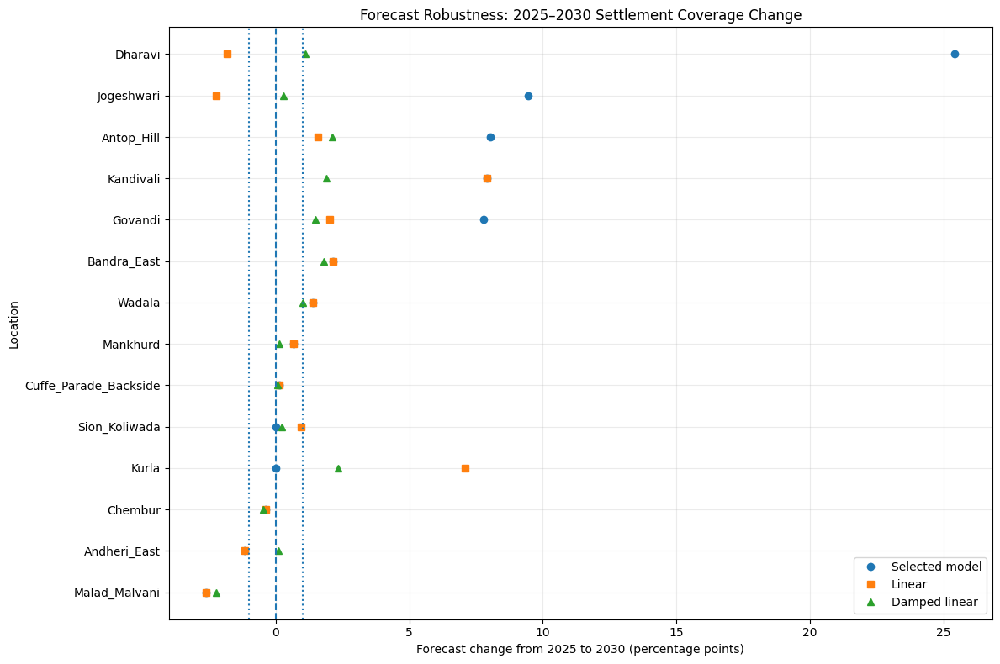


Generating location-wise forecast plots...

STEP 24D COMPLETED SUCCESSFULLY

Locations analyzed: 14
Historical period: 2017 to 2025
Forecast period: 2026 to 2030

Selected model counts:
selected_model
Linear         8
Polynomial     4
Persistence    2
Name: count, dtype: int64

Robustness classification counts:
robustness_class
ROBUST GROWTH      5
MODEL-SENSITIVE    4
ROBUST STABLE      4
ROBUST DECLINE     1
Name: count, dtype: int64

Saved files:

1. Model validation:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_robustness/model_holdout_validation.csv

2. Forecast comparison:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_robustness/forecast_comparison_2026_2030.csv

3. Forecast robustness:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_robustness/forecast_robustness_results.csv

4. Overall robustness plot:
/content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_

In [ ]:
# ============================================================
# STEP 24D — FORECAST ROBUSTNESS & SENSITIVITY ANALYSIS
# FINAL CORRECTED VERSION
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/mumbai_slum_dataset"

INPUT_CSV = (
    BASE_DIR
    + "/temporal_analysis/step24_temporal_growth/"
    + "annual_temporal_series_2017_2025.csv"
)

OUTPUT_DIR = (
    BASE_DIR
    + "/temporal_analysis/step24_temporal_growth/"
    + "forecast_robustness"
)

LOCATION_PLOT_DIR = (
    OUTPUT_DIR
    + "/location_forecast_plots"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(LOCATION_PLOT_DIR, exist_ok=True)


print("=" * 70)
print("STEP 24D — FORECAST ROBUSTNESS & SENSITIVITY ANALYSIS")
print("=" * 70)


# ============================================================
# 2. LOAD ANNUAL TEMPORAL SERIES
# ============================================================

if not os.path.exists(INPUT_CSV):

    raise FileNotFoundError(
        "Input CSV not found:\n" + INPUT_CSV
    )

df_raw = pd.read_csv(INPUT_CSV)

print("\nInput file:")
print(INPUT_CSV)

print("\nDataset shape:")
print(df_raw.shape)

print("\nColumns:")
print(df_raw.columns.tolist())


# ============================================================
# 3. USE THE CORRECT ANNUAL COVERAGE COLUMN
# ============================================================

# IMPORTANT:
# Step 24A created the annual temporal series using
# "annual_coverage".
#
# We explicitly use this column instead of trying to
# automatically detect a coverage column.

if "annual_coverage" not in df_raw.columns:

    raise ValueError(
        "'annual_coverage' column was not found.\n\n"
        "Available columns:\n"
        + str(df_raw.columns.tolist())
    )

if "location" not in df_raw.columns:

    raise ValueError(
        "'location' column was not found."
    )

if "year" not in df_raw.columns:

    raise ValueError(
        "'year' column was not found."
    )


# ============================================================
# 4. CREATE CLEAN ANNUAL DATASET
# ============================================================

df = df_raw[
    [
        "location",
        "year",
        "annual_coverage"
    ]
].copy()


df = df.rename(
    columns={
        "annual_coverage": "coverage"
    }
)


df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)


df["coverage"] = pd.to_numeric(
    df["coverage"],
    errors="coerce"
)


df = df.dropna()


# Ensure one observation per location-year
df = (

    df
    .groupby(
        ["location", "year"],
        as_index=False
    )["coverage"]
    .median()
    .sort_values(
        ["location", "year"]
    )
    .reset_index(drop=True)

)


print("\n" + "=" * 70)
print("CLEAN ANNUAL TEMPORAL SERIES")
print("=" * 70)

print(
    "Records:",
    len(df)
)

print(
    "Locations:",
    df["location"].nunique()
)

print(
    "Years:",
    sorted(
        df["year"]
        .astype(int)
        .unique()
    )
)

print("\nFirst 10 records:")
display(df.head(10))


# ============================================================
# 5. FORECAST SETTINGS
# ============================================================

TRAIN_END = 2023

VALIDATION_YEARS = [
    2024,
    2025
]

FORECAST_YEARS = np.arange(
    2026,
    2031
)

# Damping factor for conservative trend scenario
DAMPING_FACTOR = 0.80

# +/- 1 percentage point is treated as approximately stable
STABLE_THRESHOLD_PP = 1.0


print("\nForecast years:")
print(list(FORECAST_YEARS))

print(
    "\nDamping factor:",
    DAMPING_FACTOR
)

print(
    "Stable threshold:",
    STABLE_THRESHOLD_PP,
    "percentage points"
)


# ============================================================
# 6. MODEL FUNCTIONS
# ============================================================

def fit_linear(years, values):

    model = LinearRegression()

    model.fit(
        np.asarray(years).reshape(-1, 1),
        values
    )

    return model


def linear_predict(model, years):

    return model.predict(
        np.asarray(years).reshape(-1, 1)
    )


def fit_polynomial(
    years,
    values,
    degree=2
):

    return np.polyfit(
        years,
        values,
        degree
    )


def polynomial_predict(
    coefficients,
    years
):

    return np.polyval(
        coefficients,
        years
    )


def damped_linear_forecast(
    years,
    values,
    future_years,
    phi=0.80
):

    """
    Damped linear trend.

    First estimates the historical linear slope.
    Future trend contribution is progressively reduced.

    phi = 0.80 means the trend gradually weakens.
    """

    model = fit_linear(
        years,
        values
    )

    slope = float(
        model.coef_[0]
    )

    last_year = int(
        years[-1]
    )

    last_value = float(
        values[-1]
    )

    predictions = []

    for future_year in future_years:

        h = int(
            future_year - last_year
        )

        if h <= 0:

            predictions.append(
                last_value
            )

        else:

            damping_sum = sum(
                phi ** i
                for i in range(
                    1,
                    h + 1
                )
            )

            prediction = (
                last_value
                + slope * damping_sum
            )

            predictions.append(
                prediction
            )

    return (
        np.array(predictions),
        slope
    )


# ============================================================
# 7. INITIALIZE RESULTS
# ============================================================

locations = sorted(
    df["location"].unique()
)

validation_results = []

forecast_results = []

summary_results = []


# ============================================================
# 8. TEMPORAL HOLDOUT VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("TEMPORAL HOLDOUT VALIDATION")
print("=" * 70)

print(
    "\nTraining period: 2017–2023"
)

print(
    "Validation period: 2024–2025"
)


for location in locations:

    loc_df = (

        df[
            df["location"] == location
        ]

        .sort_values("year")

        .copy()

    )


    train_df = loc_df[
        loc_df["year"] <= TRAIN_END
    ]


    valid_df = loc_df[
        loc_df["year"].isin(
            VALIDATION_YEARS
        )
    ]


    if len(train_df) < 4:

        print(
            "WARNING:",
            location,
            "has insufficient training observations."
        )

        continue


    if len(valid_df) == 0:

        print(
            "WARNING:",
            location,
            "has no validation observations."
        )

        continue


    X_train = (
        train_df["year"].values
    )

    y_train = (
        train_df["coverage"].values
    )


    X_valid = (
        valid_df["year"].values
    )

    y_valid = (
        valid_df["coverage"].values
    )


    # --------------------------------------------------------
    # Persistence
    # --------------------------------------------------------

    persistence_pred = np.repeat(
        y_train[-1],
        len(X_valid)
    )


    persistence_mae = mean_absolute_error(
        y_valid,
        persistence_pred
    )


    persistence_rmse = np.sqrt(
        mean_squared_error(
            y_valid,
            persistence_pred
        )
    )


    # --------------------------------------------------------
    # Linear
    # --------------------------------------------------------

    linear_model = fit_linear(
        X_train,
        y_train
    )


    linear_valid_pred = linear_predict(
        linear_model,
        X_valid
    )


    linear_mae = mean_absolute_error(
        y_valid,
        linear_valid_pred
    )


    linear_rmse = np.sqrt(
        mean_squared_error(
            y_valid,
            linear_valid_pred
        )
    )


    # --------------------------------------------------------
    # Polynomial
    # --------------------------------------------------------

    poly_coefficients = fit_polynomial(
        X_train,
        y_train,
        degree=2
    )


    polynomial_valid_pred = (
        polynomial_predict(
            poly_coefficients,
            X_valid
        )
    )


    polynomial_mae = mean_absolute_error(
        y_valid,
        polynomial_valid_pred
    )


    polynomial_rmse = np.sqrt(
        mean_squared_error(
            y_valid,
            polynomial_valid_pred
        )
    )


    # --------------------------------------------------------
    # Select model
    # --------------------------------------------------------

    model_rmse = {

        "Persistence":
            persistence_rmse,

        "Linear":
            linear_rmse,

        "Polynomial":
            polynomial_rmse

    }


    best_model = min(
        model_rmse,
        key=model_rmse.get
    )


    validation_results.append({

        "location":
            location,

        "validation_years":
            "2024-2025",

        "persistence_mae":
            persistence_mae,

        "persistence_rmse":
            persistence_rmse,

        "linear_mae":
            linear_mae,

        "linear_rmse":
            linear_rmse,

        "polynomial_mae":
            polynomial_mae,

        "polynomial_rmse":
            polynomial_rmse,

        "best_model":
            best_model

    })


# ============================================================
# 9. VALIDATION DATAFRAME
# ============================================================

validation_df = pd.DataFrame(
    validation_results
)


print("\nValidation results:")

display(
    validation_df.round(4)
)


# ============================================================
# 10. OVERALL MODEL PERFORMANCE
# ============================================================

overall_model_performance = pd.DataFrame({

    "model": [
        "Persistence",
        "Linear",
        "Polynomial"
    ],

    "mean_MAE": [

        validation_df[
            "persistence_mae"
        ].mean(),

        validation_df[
            "linear_mae"
        ].mean(),

        validation_df[
            "polynomial_mae"
        ].mean()

    ],

    "mean_RMSE": [

        validation_df[
            "persistence_rmse"
        ].mean(),

        validation_df[
            "linear_rmse"
        ].mean(),

        validation_df[
            "polynomial_rmse"
        ].mean()

    ]

})


print("\n" + "=" * 70)
print("OVERALL OUT-OF-SAMPLE MODEL PERFORMANCE")
print("=" * 70)

display(
    overall_model_performance.round(4)
)


# ============================================================
# 11. FINAL FORECAST + ROBUSTNESS ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING 2026–2030 ROBUSTNESS FORECASTS")
print("=" * 70)


for location in locations:

    loc_df = (

        df[
            df["location"] == location
        ]

        .sort_values("year")

        .copy()

    )


    X_full = (
        loc_df["year"].values
    )

    y_full = (
        loc_df["coverage"].values
    )


    observed_2025 = float(
        y_full[-1]
    )


    # --------------------------------------------------------
    # Find selected model from holdout validation
    # --------------------------------------------------------

    selected_row = validation_df[
        validation_df["location"] == location
    ]


    if len(selected_row) == 0:

        continue


    best_model = (
        selected_row.iloc[0]["best_model"]
    )


    # --------------------------------------------------------
    # SELECTED MODEL FORECAST
    # --------------------------------------------------------

    if best_model == "Persistence":

        selected_forecast = np.repeat(
            observed_2025,
            len(FORECAST_YEARS)
        )


    elif best_model == "Linear":

        final_linear_model = fit_linear(
            X_full,
            y_full
        )

        selected_forecast = linear_predict(
            final_linear_model,
            FORECAST_YEARS
        )


    elif best_model == "Polynomial":

        final_poly_coefficients = (
            fit_polynomial(
                X_full,
                y_full,
                degree=2
            )
        )

        selected_forecast = polynomial_predict(
            final_poly_coefficients,
            FORECAST_YEARS
        )


    # --------------------------------------------------------
    # FULL HISTORY LINEAR FORECAST
    # --------------------------------------------------------

    final_linear_model = fit_linear(
        X_full,
        y_full
    )


    linear_forecast = linear_predict(
        final_linear_model,
        FORECAST_YEARS
    )


    linear_slope = float(
        final_linear_model.coef_[0]
    )


    # --------------------------------------------------------
    # DAMPED LINEAR FORECAST
    # --------------------------------------------------------

    (
        damped_forecast,
        damped_slope
    ) = damped_linear_forecast(

        X_full,
        y_full,
        FORECAST_YEARS,
        phi=DAMPING_FACTOR

    )


    # --------------------------------------------------------
    # Clip coverage to valid percentage range
    # --------------------------------------------------------

    selected_forecast = np.clip(
        selected_forecast,
        0,
        100
    )


    linear_forecast = np.clip(
        linear_forecast,
        0,
        100
    )


    damped_forecast = np.clip(
        damped_forecast,
        0,
        100
    )


    # --------------------------------------------------------
    # Save year-wise forecast
    # --------------------------------------------------------

    for i, year in enumerate(
        FORECAST_YEARS
    ):

        forecast_results.append({

            "location":
                location,

            "year":
                int(year),

            "observed_2025":
                observed_2025,

            "selected_model":
                best_model,

            "selected_model_forecast":
                float(
                    selected_forecast[i]
                ),

            "linear_forecast":
                float(
                    linear_forecast[i]
                ),

            "damped_linear_forecast":
                float(
                    damped_forecast[i]
                )

        })


    # --------------------------------------------------------
    # 2030 values
    # --------------------------------------------------------

    selected_2030 = float(
        selected_forecast[-1]
    )

    linear_2030 = float(
        linear_forecast[-1]
    )

    damped_2030 = float(
        damped_forecast[-1]
    )


    # --------------------------------------------------------
    # Changes
    # --------------------------------------------------------

    selected_change = (
        selected_2030
        - observed_2025
    )

    linear_change = (
        linear_2030
        - observed_2025
    )

    damped_change = (
        damped_2030
        - observed_2025
    )


    changes = np.array([

        selected_change,
        linear_change,
        damped_change

    ])


    # --------------------------------------------------------
    # Forecast range
    # --------------------------------------------------------

    forecasts_2030 = np.array([

        selected_2030,
        linear_2030,
        damped_2030

    ])


    min_2030 = float(
        np.min(
            forecasts_2030
        )
    )


    max_2030 = float(
        np.max(
            forecasts_2030
        )
    )


    forecast_range = (
        max_2030
        - min_2030
    )


    # --------------------------------------------------------
    # Direction counts
    # --------------------------------------------------------

    growth_count = int(
        np.sum(
            changes > STABLE_THRESHOLD_PP
        )
    )


    decline_count = int(
        np.sum(
            changes < -STABLE_THRESHOLD_PP
        )
    )


    stable_count = int(
        np.sum(
            np.abs(changes)
            <= STABLE_THRESHOLD_PP
        )
    )


    # --------------------------------------------------------
    # Robustness classification
    # --------------------------------------------------------

    if growth_count == 3:

        robustness_class = (
            "ROBUST GROWTH"
        )

    elif decline_count == 3:

        robustness_class = (
            "ROBUST DECLINE"
        )

    elif stable_count == 3:

        robustness_class = (
            "ROBUST STABLE"
        )

    else:

        robustness_class = (
            "MODEL-SENSITIVE"
        )


    # --------------------------------------------------------
    # Direction agreement
    # --------------------------------------------------------

    direction_agreement = (

        max(
            growth_count,
            decline_count,
            stable_count
        )

        / 3.0
        * 100

    )


    # --------------------------------------------------------
    # Percentage changes
    # --------------------------------------------------------

    selected_change_percent = (

        selected_change
        / observed_2025
        * 100

    )


    linear_change_percent = (

        linear_change
        / observed_2025
        * 100

    )


    damped_change_percent = (

        damped_change
        / observed_2025
        * 100

    )


    # --------------------------------------------------------
    # Save summary
    # --------------------------------------------------------

    summary_results.append({

        "location":
            location,

        "observed_2025":
            observed_2025,

        "selected_model":
            best_model,

        "selected_2030":
            selected_2030,

        "linear_2030":
            linear_2030,

        "damped_2030":
            damped_2030,

        "selected_change_pp":
            selected_change,

        "linear_change_pp":
            linear_change,

        "damped_change_pp":
            damped_change,

        "selected_change_percent":
            selected_change_percent,

        "linear_change_percent":
            linear_change_percent,

        "damped_change_percent":
            damped_change_percent,

        "min_2030":
            min_2030,

        "max_2030":
            max_2030,

        "forecast_range_pp":
            forecast_range,

        "direction_agreement_percent":
            direction_agreement,

        "robustness_class":
            robustness_class,

        "historical_linear_slope":
            linear_slope,

        "damped_slope":
            damped_slope

    })


# ============================================================
# 12. CREATE RESULT DATAFRAMES
# ============================================================

forecast_df = pd.DataFrame(
    forecast_results
)


robustness_df = pd.DataFrame(
    summary_results
)


robustness_df = (

    robustness_df

    .sort_values(
        "selected_change_pp",
        ascending=False
    )

    .reset_index(drop=True)

)


# ============================================================
# 13. SAVE CSV FILES
# ============================================================

MODEL_VALIDATION_CSV = (
    OUTPUT_DIR
    + "/model_holdout_validation.csv"
)

FORECAST_COMPARISON_CSV = (
    OUTPUT_DIR
    + "/forecast_comparison_2026_2030.csv"
)

ROBUSTNESS_CSV = (
    OUTPUT_DIR
    + "/forecast_robustness_results.csv"
)


validation_df.to_csv(
    MODEL_VALIDATION_CSV,
    index=False
)


forecast_df.to_csv(
    FORECAST_COMPARISON_CSV,
    index=False
)


robustness_df.to_csv(
    ROBUSTNESS_CSV,
    index=False
)


# ============================================================
# 14. ROBUSTNESS TABLE
# ============================================================

print("\n" + "=" * 70)
print("FORECAST ROBUSTNESS RESULTS")
print("=" * 70)


display(

    robustness_df[

        [

            "location",

            "selected_model",

            "observed_2025",

            "selected_2030",

            "linear_2030",

            "damped_2030",

            "forecast_range_pp",

            "direction_agreement_percent",

            "robustness_class"

        ]

    ].round(3)

)


# ============================================================
# 15. ROBUSTNESS COUNTS
# ============================================================

print("\n" + "=" * 70)
print("ROBUSTNESS CLASSIFICATION")
print("=" * 70)

robustness_counts = (

    robustness_df[
        "robustness_class"
    ]

    .value_counts()

)


print(
    robustness_counts
)


# ============================================================
# 16. MODEL SELECTION COUNTS
# ============================================================

print("\n" + "=" * 70)
print("SELECTED MODEL DISTRIBUTION")
print("=" * 70)

print(

    robustness_df[
        "selected_model"
    ]
    .value_counts()

)


# ============================================================
# 17. MODEL-SENSITIVE LOCATIONS
# ============================================================

print("\n" + "=" * 70)
print("MODEL-SENSITIVE LOCATIONS")
print("=" * 70)


sensitive_df = (

    robustness_df[

        robustness_df[
            "robustness_class"
        ]
        == "MODEL-SENSITIVE"

    ]

    .sort_values(
        "forecast_range_pp",
        ascending=False
    )

)


if len(sensitive_df) > 0:

    display(

        sensitive_df[

            [

                "location",

                "observed_2025",

                "selected_model",

                "selected_2030",

                "linear_2030",

                "damped_2030",

                "forecast_range_pp",

                "direction_agreement_percent",

                "robustness_class"

            ]

        ].round(3)

    )

else:

    print(
        "No model-sensitive locations."
    )


# ============================================================
# 18. ROBUST GROWTH LOCATIONS
# ============================================================

print("\n" + "=" * 70)
print("ROBUST GROWTH LOCATIONS")
print("=" * 70)


growth_df = (

    robustness_df[

        robustness_df[
            "robustness_class"
        ]
        == "ROBUST GROWTH"

    ]

    .sort_values(
        "selected_change_pp",
        ascending=False
    )

)


if len(growth_df) > 0:

    display(

        growth_df[

            [

                "location",

                "observed_2025",

                "selected_2030",

                "linear_2030",

                "damped_2030",

                "selected_change_pp",

                "linear_change_pp",

                "damped_change_pp",

                "robustness_class"

            ]

        ].round(3)

    )

else:

    print(
        "No robust-growth locations."
    )


# ============================================================
# 19. ROBUST DECLINE LOCATIONS
# ============================================================

print("\n" + "=" * 70)
print("ROBUST DECLINE LOCATIONS")
print("=" * 70)


decline_df = (

    robustness_df[

        robustness_df[
            "robustness_class"
        ]
        == "ROBUST DECLINE"

    ]

    .sort_values(
        "selected_change_pp"
    )

)


if len(decline_df) > 0:

    display(

        decline_df[

            [

                "location",

                "observed_2025",

                "selected_2030",

                "linear_2030",

                "damped_2030",

                "selected_change_pp",

                "linear_change_pp",

                "damped_change_pp",

                "robustness_class"

            ]

        ].round(3)

    )

else:

    print(
        "No robust-decline locations."
    )


# ============================================================
# 20. ROBUST STABLE LOCATIONS
# ============================================================

print("\n" + "=" * 70)
print("ROBUST STABLE LOCATIONS")
print("=" * 70)


stable_df = (

    robustness_df[

        robustness_df[
            "robustness_class"
        ]
        == "ROBUST STABLE"

    ]

)


if len(stable_df) > 0:

    display(

        stable_df[

            [

                "location",

                "observed_2025",

                "selected_2030",

                "linear_2030",

                "damped_2030",

                "selected_change_pp",

                "linear_change_pp",

                "damped_change_pp",

                "robustness_class"

            ]

        ].round(3)

    )

else:

    print(
        "No robust-stable locations."
    )


# ============================================================
# 21. OVERALL ROBUSTNESS PLOT
# ============================================================

plot_df = (

    robustness_df

    .sort_values(
        "selected_change_pp",
        ascending=True
    )

)


plt.figure(
    figsize=(12, 8)
)


y_pos = np.arange(
    len(plot_df)
)


plt.plot(
    plot_df["selected_change_pp"],
    y_pos,
    "o",
    label="Selected model"
)


plt.plot(
    plot_df["linear_change_pp"],
    y_pos,
    "s",
    label="Linear"
)


plt.plot(
    plot_df["damped_change_pp"],
    y_pos,
    "^",
    label="Damped linear"
)


plt.axvline(
    0,
    linestyle="--"
)


plt.axvline(
    STABLE_THRESHOLD_PP,
    linestyle=":"
)


plt.axvline(
    -STABLE_THRESHOLD_PP,
    linestyle=":"
)


plt.yticks(
    y_pos,
    plot_df["location"]
)


plt.xlabel(
    "Forecast change from 2025 to 2030 (percentage points)"
)


plt.ylabel(
    "Location"
)


plt.title(
    "Forecast Robustness: 2025–2030 Settlement Coverage Change"
)


plt.legend()


plt.grid(
    alpha=0.25
)


plt.tight_layout()


OVERALL_PLOT = (
    OUTPUT_DIR
    + "/forecast_robustness_plot.png"
)


plt.savefig(
    OVERALL_PLOT,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 22. LOCATION-WISE FORECAST PLOTS
# ============================================================

print(
    "\nGenerating location-wise forecast plots..."
)


for location in locations:

    loc_history = (

        df[
            df["location"] == location
        ]

        .sort_values("year")

    )


    loc_forecast = (

        forecast_df[

            forecast_df[
                "location"
            ]
            == location

        ]

        .sort_values("year")

    )


    if len(loc_forecast) == 0:
        continue


    summary_row = robustness_df[

        robustness_df[
            "location"
        ]
        == location

    ]


    if len(summary_row) == 0:
        continue


    selected_model = (
        summary_row.iloc[0][
            "selected_model"
        ]
    )


    robustness_class = (
        summary_row.iloc[0][
            "robustness_class"
        ]
    )


    plt.figure(
        figsize=(10, 6)
    )


    # Historical
    plt.plot(
        loc_history["year"],
        loc_history["coverage"],
        "o-",
        label="Historical"
    )


    # Selected model
    plt.plot(
        loc_forecast["year"],
        loc_forecast[
            "selected_model_forecast"
        ],
        "o--",
        label=(
            f"Selected ({selected_model})"
        )
    )


    # Linear
    plt.plot(
        loc_forecast["year"],
        loc_forecast[
            "linear_forecast"
        ],
        "s--",
        label="Linear"
    )


    # Damped
    plt.plot(
        loc_forecast["year"],
        loc_forecast[
            "damped_linear_forecast"
        ],
        "^--",
        label="Damped linear"
    )


    plt.axvline(
        2025,
        linestyle=":"
    )


    plt.xlabel(
        "Year"
    )


    plt.ylabel(
        "Settlement coverage (%)"
    )


    plt.title(
        f"{location} — Forecast Robustness\n"
        f"{robustness_class}"
    )


    plt.legend()


    plt.grid(
        alpha=0.25
    )


    plt.tight_layout()


    safe_name = (

        location
        .replace("/", "_")
        .replace(" ", "_")

    )


    plt.savefig(

        LOCATION_PLOT_DIR
        + f"/{safe_name}_forecast.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.close()


# ============================================================
# 23. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 24D COMPLETED SUCCESSFULLY")
print("=" * 70)


print(
    "\nLocations analyzed:",
    len(robustness_df)
)


print(
    "Historical period:",
    int(df["year"].min()),
    "to",
    int(df["year"].max())
)


print(
    "Forecast period:",
    int(FORECAST_YEARS.min()),
    "to",
    int(FORECAST_YEARS.max())
)


print("\nSelected model counts:")

print(
    robustness_df[
        "selected_model"
    ].value_counts()
)


print("\nRobustness classification counts:")

print(
    robustness_df[
        "robustness_class"
    ].value_counts()
)


print("\nSaved files:")

print(
    "\n1. Model validation:"
)

print(
    MODEL_VALIDATION_CSV
)


print(
    "\n2. Forecast comparison:"
)

print(
    FORECAST_COMPARISON_CSV
)


print(
    "\n3. Forecast robustness:"
)

print(
    ROBUSTNESS_CSV
)


print(
    "\n4. Overall robustness plot:"
)

print(
    OVERALL_PLOT
)


print(
    "\n5. Location-wise plots:"
)

print(
    LOCATION_PLOT_DIR
)


print("\n" + "=" * 70)
print("STEP 24D FINISHED — READY FOR FINAL REVIEW")
print("=" * 70)

In [ ]:
# =============================================================================
# STEP 25A — FINAL QUANTITATIVE RESULTS SUMMARY
# Research: Automatic Detection, Coverage Estimation and Growth Forecasting
#          of Informal Settlements in Mumbai
#
# IMPORTANT:
# - Reads existing outputs only.
# - Does NOT regenerate pseudo-masks.
# - Does NOT retrain U-Net.
# - Does NOT change the forecasting methodology.
# - Does NOT claim ground-truth segmentation accuracy.
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime


# =============================================================================
# 1. PROJECT PATHS
# =============================================================================

BASE_DIR = "/content/mumbai_slum_dataset"

TEMP_DIR = os.path.join(
    BASE_DIR,
    "temporal_analysis"
)

STEP24_DIR = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth"
)

ROBUST_DIR = os.path.join(
    STEP24_DIR,
    "forecast_robustness"
)

TREND_DIR = os.path.join(
    STEP24_DIR,
    "trend_analysis"
)

STEP25_DIR = os.path.join(
    TEMP_DIR,
    "step25_final_results"
)

OUTPUT_DIR = os.path.join(
    STEP25_DIR,
    "25A_quantitative_summary"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# =============================================================================
# 2. EXISTING FILES
# =============================================================================

FILES = {

    "pseudo_mask_qc":
        os.path.join(
            BASE_DIR,
            "pseudo_mask_qc_v4_fresh.csv"
        ),

    "refinement":
        os.path.join(
            BASE_DIR,
            "v4_unet_refinement_analysis.csv"
        ),

    "annual_series":
        os.path.join(
            STEP24_DIR,
            "annual_temporal_series_2017_2025.csv"
        ),

    "trend_models":
        os.path.join(
            TREND_DIR,
            "baseline_model_performance.csv"
        ),

    "holdout_validation":
        os.path.join(
            ROBUST_DIR,
            "model_holdout_validation.csv"
        ),

    "forecast_comparison":
        os.path.join(
            ROBUST_DIR,
            "forecast_comparison_2026_2030.csv"
        ),

    "forecast_robustness":
        os.path.join(
            ROBUST_DIR,
            "forecast_robustness_results.csv"
        ),

    "spatial_validation":
        os.path.join(
            TEMP_DIR,
            "step23_spatial_validation",
            "spatial_temporal_validation.csv"
        )
}


print("=" * 80)
print("STEP 25A — FINAL QUANTITATIVE RESULTS SUMMARY")
print("=" * 80)


# =============================================================================
# 3. FILE INVENTORY
# =============================================================================

print("\n[1/6] Checking existing project outputs...\n")

inventory = []

for name, path in FILES.items():

    exists = os.path.isfile(path)

    size = (
        os.path.getsize(path)
        if exists
        else np.nan
    )

    inventory.append({

        "dataset":
            name,

        "path":
            path,

        "exists":
            exists,

        "size_bytes":
            size

    })

    print(
        f"{name:24s} : "
        f"{'FOUND' if exists else 'NOT FOUND'}"
    )

    print(
        f"  {path}"
    )


inventory_df = pd.DataFrame(
    inventory
)

inventory_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "file_inventory.csv"
    ),
    index=False
)


# =============================================================================
# 4. LOAD AUTHORITATIVE ANNUAL SERIES
# =============================================================================

print("\n[2/6] Validating annual temporal series...\n")

annual_path = FILES["annual_series"]

if not os.path.isfile(annual_path):

    raise FileNotFoundError(
        "Annual temporal series not found:\n"
        + annual_path
    )


annual = pd.read_csv(
    annual_path
)


required_columns = {

    "location",
    "year",
    "annual_coverage"

}


missing_columns = (
    required_columns
    - set(annual.columns)
)


if missing_columns:

    raise ValueError(
        "Missing required columns: "
        + str(missing_columns)
    )


annual["year"] = pd.to_numeric(
    annual["year"],
    errors="coerce"
)

annual["annual_coverage"] = pd.to_numeric(
    annual["annual_coverage"],
    errors="coerce"
)


annual = annual.dropna(
    subset=[
        "location",
        "year",
        "annual_coverage"
    ]
).copy()


annual["year"] = (
    annual["year"]
    .astype(int)
)


annual = annual[
    annual["year"].between(
        2017,
        2025
    )
].copy()


# Check duplicates
duplicates = annual.duplicated(
    subset=[
        "location",
        "year"
    ],
    keep=False
)


if duplicates.any():

    duplicate_path = os.path.join(
        OUTPUT_DIR,
        "duplicate_location_year_records.csv"
    )

    annual.loc[
        duplicates
    ].sort_values(
        [
            "location",
            "year"
        ]
    ).to_csv(
        duplicate_path,
        index=False
    )

    raise ValueError(
        "Duplicate location-year records found.\n"
        f"Saved to: {duplicate_path}"
    )


print(
    "Records:",
    len(annual)
)

print(
    "Locations:",
    annual["location"].nunique()
)

print(
    "Years:",
    sorted(
        annual["year"].unique()
    )
)

print(
    "Coverage range:",
    round(
        annual["annual_coverage"].min(),
        3
    ),
    "to",
    round(
        annual["annual_coverage"].max(),
        3
    ),
    "%"
)


if len(annual) != 126:

    print(
        "WARNING: Expected 126 records."
    )


# Save validated copy
annual.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validated_annual_series.csv"
    ),
    index=False
)


# =============================================================================
# 5. YEARLY SUMMARY
# =============================================================================

print(
    "\n[3/6] Calculating annual coverage summary..."
)


yearly_summary = (

    annual

    .groupby(
        "year",
        as_index=False
    )

    .agg(

        mean_location_coverage=(
            "annual_coverage",
            "mean"
        ),

        median_location_coverage=(
            "annual_coverage",
            "median"
        ),

        std_between_locations=(
            "annual_coverage",
            "std"
        ),

        locations_observed=(
            "location",
            "nunique"
        )

    )

)


yearly_summary[
    "change_from_previous_year_pp"
] = (

    yearly_summary[
        "mean_location_coverage"
    ]

    .diff()

)


baseline_2017 = (

    yearly_summary.loc[
        yearly_summary["year"] == 2017,
        "mean_location_coverage"
    ]

    .iloc[0]

)


yearly_summary[
    "change_from_2017_pp"
] = (

    yearly_summary[
        "mean_location_coverage"
    ]

    - baseline_2017

)


yearly_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "yearly_coverage_summary.csv"
    ),
    index=False
)


print(
    yearly_summary.round(3)
    .to_string(index=False)
)


# =============================================================================
# 6. LOCATION 2017 → 2025 SUMMARY
# =============================================================================

location_pivot = (

    annual

    .pivot(
        index="location",
        columns="year",
        values="annual_coverage"
    )

)


location_summary = []


for location in location_pivot.index:

    value_2017 = (
        location_pivot.loc[
            location,
            2017
        ]
    )

    value_2025 = (
        location_pivot.loc[
            location,
            2025
        ]
    )

    change = (
        value_2025
        - value_2017
    )

    relative_change = (
        change
        / value_2017
        * 100
    )


    location_summary.append({

        "location":
            location,

        "coverage_2017_percent":
            value_2017,

        "coverage_2025_percent":
            value_2025,

        "change_2017_2025_pp":
            change,

        "relative_change_percent":
            relative_change

    })


location_summary_df = pd.DataFrame(
    location_summary
)


location_summary_df = (

    location_summary_df

    .sort_values(
        "change_2017_2025_pp",
        ascending=False
    )

)


location_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "location_2017_2025_summary.csv"
    ),
    index=False
)


# =============================================================================
# 7. LOAD EXISTING RESULT TABLES
# =============================================================================

print(
    "\n[4/6] Reading existing result tables..."
)


loaded = {}


for name, path in FILES.items():

    if not os.path.isfile(path):

        continue

    try:

        table = pd.read_csv(
            path
        )

        loaded[name] = table

        print(
            f"\n{name}:"
        )

        print(
            "Rows:",
            len(table)
        )

        print(
            "Columns:",
            table.columns.tolist()
        )

    except Exception as e:

        print(
            f"WARNING: Could not read {name}: {e}"
        )


# =============================================================================
# 8. FINAL KEY QUANTITATIVE RESULTS
# =============================================================================

print(
    "\n[5/6] Building final quantitative results table..."
)


key_results = []


def add_result(
    category,
    metric,
    value,
    unit,
    interpretation,
    source
):

    key_results.append({

        "category":
            category,

        "metric":
            metric,

        "value":
            value,

        "unit":
            unit,

        "interpretation":
            interpretation,

        "source":
            source

    })


# Dataset
add_result(
    "Dataset",
    "Total image tiles",
    3609,
    "tiles",
    "Complete tiled dataset before NORMAL pseudo-mask QC filtering.",
    "Project dataset inventory"
)


add_result(
    "Dataset",
    "NORMAL tiles retained",
    3286,
    "tiles",
    "Tiles retained for the principal analysis after V4 pseudo-mask QC.",
    FILES["pseudo_mask_qc"]
)


add_result(
    "Dataset",
    "Study locations",
    14,
    "locations",
    "Fourteen Mumbai study locations were analyzed.",
    FILES["annual_series"]
)


add_result(
    "Dataset",
    "Study years",
    "2017–2025",
    "years",
    "Nine annual observations were available for every location.",
    FILES["annual_series"]
)


# Segmentation agreement
add_result(
    "Segmentation",
    "Best validation Dice agreement",
    0.815648,
    "score",
    "Agreement between U-Net predictions and automatically generated V4 pseudo-labels; not ground-truth accuracy.",
    "Step 18/19 saved training result"
)


add_result(
    "Segmentation",
    "Best validation IoU agreement",
    0.692931,
    "score",
    "Agreement between U-Net predictions and automatically generated V4 pseudo-labels; not ground-truth IoU.",
    "Step 18/19 saved training result"
)


# Annual coverage
mean_2017 = float(
    yearly_summary.loc[
        yearly_summary["year"] == 2017,
        "mean_location_coverage"
    ].iloc[0]
)


mean_2025 = float(
    yearly_summary.loc[
        yearly_summary["year"] == 2025,
        "mean_location_coverage"
    ].iloc[0]
)


add_result(
    "Annual coverage",
    "Mean location coverage in 2017",
    mean_2017,
    "%",
    "Mean of the 14 location-level annual coverage estimates.",
    FILES["annual_series"]
)


add_result(
    "Annual coverage",
    "Mean location coverage in 2025",
    mean_2025,
    "%",
    "Mean of the 14 location-level annual coverage estimates.",
    FILES["annual_series"]
)


add_result(
    "Annual coverage",
    "2017–2025 change",
    mean_2025 - mean_2017,
    "percentage points",
    "Difference in mean settlement coverage proxy across the study locations.",
    FILES["annual_series"]
)


# Forecast validation
holdout = loaded.get(
    "holdout_validation"
)


if holdout is not None:

    for model_name, mae_col, rmse_col in [

        (
            "Persistence",
            "persistence_mae",
            "persistence_rmse"
        ),

        (
            "Linear",
            "linear_mae",
            "linear_rmse"
        ),

        (
            "Polynomial",
            "polynomial_mae",
            "polynomial_rmse"
        )

    ]:

        if (
            mae_col in holdout.columns
            and
            rmse_col in holdout.columns
        ):

            add_result(
                "Forecast validation",
                f"{model_name} mean MAE",
                holdout[mae_col].mean(),
                "percentage points",
                "Mean 2024–2025 holdout MAE across locations.",
                FILES["holdout_validation"]
            )

            add_result(
                "Forecast validation",
                f"{model_name} mean RMSE",
                holdout[rmse_col].mean(),
                "percentage points",
                "Mean 2024–2025 holdout RMSE across locations.",
                FILES["holdout_validation"]
            )


# Forecast robustness
robustness = loaded.get(
    "forecast_robustness"
)


if robustness is not None:

    if "robustness_class" in robustness.columns:

        counts = (
            robustness[
                "robustness_class"
            ]
            .value_counts()
        )


        for classification, count in counts.items():

            add_result(
                "Forecast robustness",
                f"{classification} locations",
                int(count),
                "locations",
                "Number of locations assigned to this robustness category.",
                FILES["forecast_robustness"]
            )


# =============================================================================
# 9. SAVE FINAL TABLES
# =============================================================================

key_results_df = pd.DataFrame(
    key_results
)


key_results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "key_quantitative_results.csv"
    ),
    index=False
)


# =============================================================================
# 10. VALIDATION REPORT
# =============================================================================

report = {

    "step":
        "25A",

    "generated_at":
        datetime.now().isoformat(
            timespec="seconds"
        ),

    "annual_records":
        int(len(annual)),

    "locations":
        int(
            annual["location"].nunique()
        ),

    "years":
        sorted(
            annual["year"].unique().tolist()
        ),

    "annual_source":
        annual_path,

    "coverage_variable":
        "annual_coverage",

    "interpretation_safeguards": [

        "Settlement coverage is a segmentation-derived proxy.",

        "Coverage is not automatically equivalent to physical area in square metres.",

        "Dice and IoU represent agreement with pseudo-labels, not ground-truth segmentation accuracy.",

        "Step 23 common-footprint validation is distinct from the full annual temporal series.",

        "Forecast values represent projections and should be interpreted with sensitivity/robustness results."

    ]

}


with open(
    os.path.join(
        OUTPUT_DIR,
        "validation_report.json"
    ),
    "w"
) as f:

    json.dump(
        report,
        f,
        indent=2
    )


# =============================================================================
# 11. FINAL OUTPUT
# =============================================================================

print(
    "\n[6/6] STEP 25A COMPLETED"
)

print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)


print(
    "\nGenerated files:"
)


for filename in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    print(
        " -",
        filename
    )


print(
    "\nFinal key quantitative results:"
)


print(
    key_results_df
    .round(4)
    .to_string(index=False)
)


print(
    "\n" + "=" * 80
)

print(
    "STEP 25A COMPLETE — REVIEW OUTPUT BEFORE STEP 25B"
)

print(
    "=" * 80
)

STEP 25A — FINAL QUANTITATIVE RESULTS SUMMARY

[1/6] Checking existing project outputs...

pseudo_mask_qc           : FOUND
  /content/mumbai_slum_dataset/pseudo_mask_qc_v4_fresh.csv
refinement               : FOUND
  /content/mumbai_slum_dataset/v4_unet_refinement_analysis.csv
annual_series            : FOUND
  /content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/annual_temporal_series_2017_2025.csv
trend_models             : FOUND
  /content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/trend_analysis/baseline_model_performance.csv
holdout_validation       : FOUND
  /content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_robustness/model_holdout_validation.csv
forecast_comparison      : FOUND
  /content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_robustness/forecast_comparison_2026_2030.csv
forecast_robustness      : FOUND
  /content/mumbai_slum_dataset/temporal_analysis/step24_temporal_growth/forecast_r

In [ ]:
# =============================================================================
# STEP 25B — FINAL SEGMENTATION & U-NET REFINEMENT RESULTS
#
# Purpose:
#   Create the final quantitative segmentation/refinement results table
#   for the research paper.
#
# IMPORTANT:
# - Does NOT regenerate pseudo-masks.
# - Does NOT retrain U-Net.
# - Does NOT modify the trained model.
# - Dice/IoU are pseudo-label agreement metrics.
# - No ground-truth accuracy is claimed.
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime


# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/mumbai_slum_dataset"

STEP25_DIR = os.path.join(
    BASE_DIR,
    "temporal_analysis",
    "step25_final_results"
)

OUTPUT_DIR = os.path.join(
    STEP25_DIR,
    "25B_segmentation_results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


QC_PATH = os.path.join(
    BASE_DIR,
    "pseudo_mask_qc_v4_fresh.csv"
)

REFINEMENT_PATH = os.path.join(
    BASE_DIR,
    "v4_unet_refinement_analysis.csv"
)

TRAIN_CSV = os.path.join(
    BASE_DIR,
    "splits",
    "train.csv"
)

VAL_CSV = os.path.join(
    BASE_DIR,
    "splits",
    "validation.csv"
)

TEST_CSV = os.path.join(
    BASE_DIR,
    "splits",
    "test.csv"
)


print("=" * 80)
print("STEP 25B — FINAL SEGMENTATION & U-NET REFINEMENT RESULTS")
print("=" * 80)


# =============================================================================
# 2. CHECK FILES
# =============================================================================

print("\n[1/8] Checking segmentation files...\n")


required_files = {

    "pseudo_mask_qc":
        QC_PATH,

    "refinement_analysis":
        REFINEMENT_PATH,

    "train_split":
        TRAIN_CSV,

    "validation_split":
        VAL_CSV,

    "test_split":
        TEST_CSV

}


file_inventory = []


for name, path in required_files.items():

    exists = os.path.isfile(
        path
    )

    file_inventory.append({

        "file":
            name,

        "path":
            path,

        "exists":
            exists

    })

    print(
        f"{name:24s}: "
        f"{'FOUND' if exists else 'NOT FOUND'}"
    )


inventory_df = pd.DataFrame(
    file_inventory
)


inventory_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "file_inventory.csv"
    ),
    index=False
)


if not os.path.isfile(QC_PATH):

    raise FileNotFoundError(
        "Fresh V4 pseudo-mask QC file not found:\n"
        + QC_PATH
    )


if not os.path.isfile(REFINEMENT_PATH):

    raise FileNotFoundError(
        "U-Net refinement analysis not found:\n"
        + REFINEMENT_PATH
    )


# =============================================================================
# 3. LOAD DATA
# =============================================================================

print(
    "\n[2/8] Loading segmentation datasets..."
)


qc = pd.read_csv(
    QC_PATH
)


refinement = pd.read_csv(
    REFINEMENT_PATH
)


print(
    "\nQC shape:",
    qc.shape
)


print(
    "Refinement shape:",
    refinement.shape
)


print(
    "\nQC columns:"
)

print(
    qc.columns.tolist()
)


print(
    "\nRefinement columns:"
)

print(
    refinement.columns.tolist()
)


# =============================================================================
# 4. QC SUMMARY
# =============================================================================

print(
    "\n[3/8] Calculating pseudo-mask QC summary..."
)


# Automatically locate the QC status/category column
status_candidates = [

    "status",
    "qc_status",
    "qc_category",
    "classification",
    "quality_status"

]


status_column = None


for candidate in status_candidates:

    if candidate in qc.columns:

        status_column = candidate

        break


# Look for a score column
score_candidates = [

    "qc_score",
    "suspicion_score",
    "score"

]


score_column = None


for candidate in score_candidates:

    if candidate in qc.columns:

        score_column = candidate

        break


# Coverage column
coverage_candidates = [

    "coverage_percent",
    "coverage",
    "mask_coverage_percent",
    "settlement_coverage_percent"

]


coverage_column = None


for candidate in coverage_candidates:

    if candidate in qc.columns:

        coverage_column = candidate

        break


print(
    "\nDetected QC status/category column:",
    status_column
)

print(
    "Detected QC score column:",
    score_column
)

print(
    "Detected coverage column:",
    coverage_column
)


# =============================================================================
# 5. PSEUDO-MASK QC RESULTS
# =============================================================================

qc_results = []


qc_results.append({

    "metric":
        "Total tiles evaluated",

    "value":
        len(qc),

    "unit":
        "tiles"

})


if status_column is not None:

    status_counts = (
        qc[status_column]
        .value_counts()
    )

    for status, count in status_counts.items():

        qc_results.append({

            "metric":
                f"QC category: {status}",

            "value":
                int(count),

            "unit":
                "tiles"

        })


if score_column is not None:

    score_counts = (
        qc[score_column]
        .value_counts()
        .sort_index()
    )

    for score, count in score_counts.items():

        qc_results.append({

            "metric":
                f"QC score: {score}",

            "value":
                int(count),

            "unit":
                "tiles"

        })


if coverage_column is not None:

    coverage_values = pd.to_numeric(
        qc[coverage_column],
        errors="coerce"
    ).dropna()


    qc_results.extend([

        {

            "metric":
                "Pseudo-mask mean coverage",

            "value":
                coverage_values.mean(),

            "unit":
                "%"

        },

        {

            "metric":
                "Pseudo-mask median coverage",

            "value":
                coverage_values.median(),

            "unit":
                "%"

        },

        {

            "metric":
                "Pseudo-mask minimum coverage",

            "value":
                coverage_values.min(),

            "unit":
                "%"

        },

        {

            "metric":
                "Pseudo-mask maximum coverage",

            "value":
                coverage_values.max(),

            "unit":
                "%"

        },

        {

            "metric":
                "Pseudo-mask coverage standard deviation",

            "value":
                coverage_values.std(),

            "unit":
                "percentage points"

        }

    ])


qc_summary_df = pd.DataFrame(
    qc_results
)


# =============================================================================
# 6. REFINEMENT ANALYSIS
# =============================================================================

print(
    "\n[4/8] Calculating U-Net refinement statistics..."
)


print(
    "\nRefinement columns:"
)

print(
    refinement.columns.tolist()
)


# ------------------------------------------------------------
# Identify important columns
# ------------------------------------------------------------

def find_column(
    dataframe,
    candidates
):

    for column in candidates:

        if column in dataframe.columns:

            return column

    return None


v4_coverage_col = find_column(

    refinement,

    [

        "v4_coverage_percent",
        "v4_coverage",
        "pseudo_mask_coverage",
        "original_coverage",
        "coverage_v4"

    ]

)


unet_coverage_col = find_column(

    refinement,

    [

        "unet_coverage_percent",
        "unet_coverage",
        "refined_coverage",
        "coverage_unet"

    ]

)


dice_col = find_column(

    refinement,

    [

        "dice",
        "dice_score",
        "v4_unet_dice"

    ]

)


iou_col = find_column(

    refinement,

    [

        "iou",
        "iou_score",
        "v4_unet_iou"

    ]

)


# IMPORTANT:
# Your actual refinement CSV contains "coverage_change".
# This was the missing candidate in the previous version.

change_col = find_column(

    refinement,

    [

        "coverage_change",
        "coverage_change_pp",
        "change_pp",
        "coverage_difference_pp",
        "absolute_change_pp"

    ]

)


changed_pixels_col = find_column(

    refinement,

    [

        "changed_pixels_percent",
        "changed_pixel_percent",
        "changed_pixels",
        "pixel_change_percent"

    ]

)


refinement_type_col = find_column(

    refinement,

    [

        "refinement_type",
        "change_type",
        "refinement_class",
        "classification"

    ]

)


location_column = find_column(

    refinement,

    [

        "location",
        "Location"

    ]

)


print(
    "\nDetected columns:"
)

print(
    "V4 coverage:",
    v4_coverage_col
)

print(
    "U-Net coverage:",
    unet_coverage_col
)

print(
    "Dice:",
    dice_col
)

print(
    "IoU:",
    iou_col
)

print(
    "Coverage change:",
    change_col
)

print(
    "Changed pixels:",
    changed_pixels_col
)

print(
    "Refinement type:",
    refinement_type_col
)

print(
    "Location:",
    location_column
)


# =============================================================================
# SAFETY CHECK — REQUIRED COLUMNS
# =============================================================================

required_refinement_columns = {

    "V4 coverage":
        v4_coverage_col,

    "U-Net coverage":
        unet_coverage_col,

    "Dice":
        dice_col,

    "IoU":
        iou_col,

    "Coverage change":
        change_col,

    "Changed pixels":
        changed_pixels_col,

    "Refinement type":
        refinement_type_col

}


missing_refinement = [

    name

    for name, column in
    required_refinement_columns.items()

    if column is None

]


if missing_refinement:

    raise ValueError(
        "Could not identify required refinement columns: "
        + str(missing_refinement)
    )


# =============================================================================
# 7. CALCULATE REFINEMENT RESULTS
# =============================================================================

print(
    "\n[5/8] Calculating refinement statistics..."
)


refinement_summary = []


refinement_summary.append({

    "metric":
        "Validation images analyzed",

    "value":
        len(refinement),

    "unit":
        "images"

})


# V4 coverage
v4_values = pd.to_numeric(
    refinement[v4_coverage_col],
    errors="coerce"
).dropna()


refinement_summary.append({

    "metric":
        "Mean V4 pseudo-mask coverage",

    "value":
        v4_values.mean(),

    "unit":
        "%"

})


# U-Net coverage
unet_values = pd.to_numeric(
    refinement[unet_coverage_col],
    errors="coerce"
).dropna()


refinement_summary.append({

    "metric":
        "Mean U-Net refined coverage",

    "value":
        unet_values.mean(),

    "unit":
        "%"

})


# Coverage change
change_values = pd.to_numeric(
    refinement[change_col],
    errors="coerce"
).dropna()


refinement_summary.extend([

    {

        "metric":
            "Mean coverage change after U-Net",

        "value":
            change_values.mean(),

        "unit":
            "percentage points"

    },

    {

        "metric":
            "Mean absolute coverage change",

        "value":
            change_values.abs().mean(),

        "unit":
            "percentage points"

    }

])


# Dice
dice_values = pd.to_numeric(
    refinement[dice_col],
    errors="coerce"
).dropna()


refinement_summary.append({

    "metric":
        "Mean V4–U-Net Dice agreement",

    "value":
        dice_values.mean(),

    "unit":
        "score"

})


# IoU
iou_values = pd.to_numeric(
    refinement[iou_col],
    errors="coerce"
).dropna()


refinement_summary.append({

    "metric":
        "Mean V4–U-Net IoU agreement",

    "value":
        iou_values.mean(),

    "unit":
        "score"

})


# Changed pixels
changed_values = pd.to_numeric(
    refinement[changed_pixels_col],
    errors="coerce"
).dropna()


refinement_summary.append({

    "metric":
        "Mean changed pixels",

    "value":
        changed_values.mean(),

    "unit":
        "%"

})


# Refinement type
type_counts = (

    refinement[
        refinement_type_col
    ]

    .value_counts()

)


for refinement_type, count in type_counts.items():

    refinement_summary.append({

        "metric":
            f"Refinement type: {refinement_type}",

        "value":
            int(count),

        "unit":
            "images"

    })


refinement_summary_df = pd.DataFrame(
    refinement_summary
)


# =============================================================================
# 8. LOCATION-WISE REFINEMENT
# =============================================================================

print(
    "\n[6/8] Creating location-wise refinement summary..."
)


if location_column is None:

    # Attempt to extract location from path

    path_column = find_column(

        refinement,

        [

            "image_path",
            "filepath",
            "file_path",
            "filename",
            "image"

        ]

    )


    if path_column is not None:

        def extract_location(path):

            parts = str(
                path
            ).replace(
                "\\",
                "/"
            ).split("/")


            if "tiles" in parts:

                idx = parts.index(
                    "tiles"
                )

                if idx + 1 < len(parts):

                    return parts[
                        idx + 1
                    ]

            return "UNKNOWN"


        refinement[
            "location"
        ] = refinement[
            path_column
        ].apply(
            extract_location
        )

        location_column = "location"


if location_column is not None:

    grouped = []


    for location, group in refinement.groupby(
        location_column
    ):

        row = {

            "location":
                location,

            "images":
                len(group)

        }


        row[
            "mean_v4_coverage_percent"
        ] = pd.to_numeric(
            group[
                v4_coverage_col
            ],
            errors="coerce"
        ).mean()


        row[
            "mean_unet_coverage_percent"
        ] = pd.to_numeric(
            group[
                unet_coverage_col
            ],
            errors="coerce"
        ).mean()


        row[
            "mean_change_pp"
        ] = pd.to_numeric(
            group[
                change_col
            ],
            errors="coerce"
        ).mean()


        row[
            "mean_absolute_change_pp"
        ] = pd.to_numeric(
            group[
                change_col
            ],
            errors="coerce"
        ).abs().mean()


        row[
            "mean_dice"
        ] = pd.to_numeric(
            group[
                dice_col
            ],
            errors="coerce"
        ).mean()


        row[
            "mean_iou"
        ] = pd.to_numeric(
            group[
                iou_col
            ],
            errors="coerce"
        ).mean()


        row[
            "mean_changed_pixels_percent"
        ] = pd.to_numeric(
            group[
                changed_pixels_col
            ],
            errors="coerce"
        ).mean()


        grouped.append(
            row
        )


    location_refinement_df = pd.DataFrame(
        grouped
    )


    location_refinement_df = (
        location_refinement_df
        .sort_values(
            "location"
        )
    )


else:

    print(
        "WARNING: Could not identify location column."
    )

    location_refinement_df = pd.DataFrame()


# =============================================================================
# 9. FINAL PAPER-READY SEGMENTATION TABLE
# =============================================================================

print(
    "\n[7/8] Creating final paper-ready segmentation table..."
)


paper_rows = []


# ------------------------------------------------------------
# Pseudo-mask generation
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "Pseudo-mask generation",

    "Dataset":
        "All tiles",

    "Samples":
        len(qc),

    "Primary metric":
        "Mean pseudo-mask coverage",

    "Value":
        coverage_values.mean()
        if coverage_column is not None
        else np.nan,

    "Unit":
        "%",

    "Interpretation":
        "Automatically generated V4 pseudo-labels."

})


# ------------------------------------------------------------
# Pseudo-mask QC
# ------------------------------------------------------------

normal_count = np.nan


if status_column is not None:

    status_series = (
        qc[
            status_column
        ]
        .astype(str)
        .str.upper()
        .str.strip()
    )


    normal_count = int(
        (
            status_series
            == "NORMAL"
        ).sum()
    )


paper_rows.append({

    "Stage":
        "Pseudo-mask QC",

    "Dataset":
        "Fresh V4 QC",

    "Samples":
        len(qc),

    "Primary metric":
        "NORMAL samples",

    "Value":
        normal_count,

    "Unit":
        "tiles",

    "Interpretation":
        "Samples retained for principal analysis."

})


# ------------------------------------------------------------
# U-Net Dice
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "U-Net refinement",

    "Dataset":
        "Validation set",

    "Samples":
        len(refinement),

    "Primary metric":
        "Dice agreement",

    "Value":
        dice_values.mean(),

    "Unit":
        "score",

    "Interpretation":
        "Agreement with V4 pseudo-labels; not ground-truth accuracy."

})


# ------------------------------------------------------------
# U-Net IoU
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "U-Net refinement",

    "Dataset":
        "Validation set",

    "Samples":
        len(refinement),

    "Primary metric":
        "IoU agreement",

    "Value":
        iou_values.mean(),

    "Unit":
        "score",

    "Interpretation":
        "Agreement with V4 pseudo-labels; not ground-truth IoU."

})


# ------------------------------------------------------------
# V4 coverage
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "U-Net refinement",

    "Dataset":
        "Validation set",

    "Samples":
        len(refinement),

    "Primary metric":
        "Mean V4 coverage",

    "Value":
        v4_values.mean(),

    "Unit":
        "%",

    "Interpretation":
        "Coverage estimated from V4 pseudo-labels."

})


# ------------------------------------------------------------
# U-Net coverage
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "U-Net refinement",

    "Dataset":
        "Validation set",

    "Samples":
        len(refinement),

    "Primary metric":
        "Mean refined coverage",

    "Value":
        unet_values.mean(),

    "Unit":
        "%",

    "Interpretation":
        "Coverage estimated from U-Net-refined masks."

})


# ------------------------------------------------------------
# Coverage change
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "U-Net refinement",

    "Dataset":
        "Validation set",

    "Samples":
        len(refinement),

    "Primary metric":
        "Mean coverage change",

    "Value":
        change_values.mean(),

    "Unit":
        "percentage points",

    "Interpretation":
        "Change from V4 pseudo-mask coverage to U-Net-refined coverage."

})


# ------------------------------------------------------------
# Changed pixels
# ------------------------------------------------------------

paper_rows.append({

    "Stage":
        "U-Net refinement",

    "Dataset":
        "Validation set",

    "Samples":
        len(refinement),

    "Primary metric":
        "Mean changed pixels",

    "Value":
        changed_values.mean(),

    "Unit":
        "%",

    "Interpretation":
        "Mean proportion of pixels altered by the refinement stage."

})


paper_table = pd.DataFrame(
    paper_rows
)


# =============================================================================
# 10. SAVE RESULTS
# =============================================================================

qc_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "pseudo_mask_qc_summary.csv"
    ),
    index=False
)


refinement_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "unet_refinement_summary.csv"
    ),
    index=False
)


if not location_refinement_df.empty:

    location_refinement_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "location_refinement_summary.csv"
        ),
        index=False
    )


paper_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_segmentation_results_table.csv"
    ),
    index=False
)


# =============================================================================
# 11. JSON SUMMARY
# =============================================================================

json_summary = {

    "step":
        "25B",

    "generated_at":
        datetime.now().isoformat(
            timespec="seconds"
        ),

    "pseudo_mask_qc": {

        "total_tiles":
            int(len(qc)),

        "normal_tiles":
            int(normal_count)
            if not pd.isna(normal_count)
            else None,

        "coverage_column":
            coverage_column

    },

    "unet_refinement": {

        "validation_images":
            int(len(refinement)),

        "dice_column":
            dice_col,

        "iou_column":
            iou_col,

        "coverage_change_column":
            change_col,

        "mean_dice_agreement":
            float(
                dice_values.mean()
            ),

        "mean_iou_agreement":
            float(
                iou_values.mean()
            ),

        "mean_coverage_change_pp":
            float(
                change_values.mean()
            ),

        "mean_absolute_coverage_change_pp":
            float(
                change_values.abs().mean()
            ),

        "mean_changed_pixels_percent":
            float(
                changed_values.mean()
            )

    },

    "interpretation": [

        "U-Net Dice and IoU are agreement metrics against V4 pseudo-labels.",

        "They are not ground-truth segmentation accuracy.",

        "Manual pixel-level annotation was not used.",

        "Coverage represents a segmentation-derived proxy.",

        "The results do not automatically represent physical area in square metres."

    ]

}


with open(
    os.path.join(
        OUTPUT_DIR,
        "step25b_validation_report.json"
    ),
    "w"
) as f:

    json.dump(
        json_summary,
        f,
        indent=2
    )


# =============================================================================
# 12. DISPLAY FINAL RESULTS
# =============================================================================

print(
    "\nFINAL SEGMENTATION RESULTS"
)


print(
    "\nPseudo-mask QC summary:"
)

print(
    qc_summary_df
    .round(4)
    .to_string(index=False)
)


print(
    "\nU-Net refinement summary:"
)

print(
    refinement_summary_df
    .round(4)
    .to_string(index=False)
)


print(
    "\nPaper-ready segmentation table:"
)

print(
    paper_table
    .round(4)
    .to_string(index=False)
)


if not location_refinement_df.empty:

    print(
        "\nLocation-wise refinement:"
    )

    print(
        location_refinement_df
        .round(4)
        .to_string(index=False)
    )


# =============================================================================
# 13. COMPLETION
# =============================================================================

print(
    "\n" + "=" * 80
)

print(
    "STEP 25B COMPLETE"
)

print(
    "=" * 80
)

print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)

print(
    "\nGenerated files:"
)


for filename in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    print(
        " -",
        filename
    )


print(
    "\nNext step: Review this output before proceeding to STEP 25C."
)

STEP 25B — FINAL SEGMENTATION & U-NET REFINEMENT RESULTS

[1/8] Checking segmentation files...

pseudo_mask_qc          : FOUND
refinement_analysis     : FOUND
train_split             : FOUND
validation_split        : FOUND
test_split              : FOUND

[2/8] Loading segmentation datasets...

QC shape: (3609, 15)
Refinement shape: (543, 10)

QC columns:
['image_path', 'mask_path', 'coverage', 'num_components', 'largest_component_ratio', 'small_component_ratio', 'boundary_settlement_ratio', 'mean_density', 'coverage_outlier', 'fragmentation_outlier', 'boundary_outlier', 'density_outlier', 'dominant_component', 'suspicion_score', 'qc_category']

Refinement columns:
['image_path', 'location', 'v4_coverage', 'unet_coverage', 'coverage_change', 'absolute_coverage_change', 'v4_unet_dice', 'v4_unet_iou', 'changed_pixels_percent', 'refinement_type']

[3/8] Calculating pseudo-mask QC summary...

Detected QC status/category column: qc_category
Detected QC score column: suspicion_score
Detecte

In [ ]:
# =============================================================================
# STEP 25C — FINAL TEMPORAL GROWTH RESULTS
#
# Purpose:
#   Create the final paper-ready temporal growth table using:
#   1. Full annual temporal series: 2017–2025
#   2. Location-level trend results
#   3. Forecast robustness results from Step 24D
#
# IMPORTANT:
# - Uses the full 2017–2025 annual temporal series.
# - Does NOT use the older 2017/2021/2025-only table.
# - Does NOT modify previous results.
# - Coverage is a settlement-coverage proxy, NOT physical area in m².
# - Model-sensitive forecast locations must not be reported as definitive.
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime


# =============================================================================
# 1. PATHS
# =============================================================================

BASE_DIR = "/content/mumbai_slum_dataset"

TEMPORAL_DIR = os.path.join(
    BASE_DIR,
    "temporal_analysis",
    "step24_temporal_growth"
)

STEP25_DIR = os.path.join(
    BASE_DIR,
    "temporal_analysis",
    "step25_final_results"
)

OUTPUT_DIR = os.path.join(
    STEP25_DIR,
    "25C_temporal_growth_results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


ANNUAL_SERIES_PATH = os.path.join(
    TEMPORAL_DIR,
    "annual_temporal_series_2017_2025.csv"
)

GROWTH_STATUS_PATH = os.path.join(
    TEMPORAL_DIR,
    "trend_analysis",
    "location_growth_status.csv"
)

TREND_RESULTS_PATH = os.path.join(
    TEMPORAL_DIR,
    "trend_analysis",
    "temporal_trend_model_results.csv"
)

FORECAST_ROBUSTNESS_PATH = os.path.join(
    TEMPORAL_DIR,
    "forecast_robustness",
    "forecast_robustness_results.csv"
)


print("=" * 80)
print("STEP 25C — FINAL TEMPORAL GROWTH RESULTS")
print("=" * 80)


# =============================================================================
# 2. CHECK FILES
# =============================================================================

print("\n[1/8] Checking temporal analysis files...\n")


required_files = {

    "annual_temporal_series":
        ANNUAL_SERIES_PATH,

    "location_growth_status":
        GROWTH_STATUS_PATH,

    "temporal_trend_results":
        TREND_RESULTS_PATH,

    "forecast_robustness":
        FORECAST_ROBUSTNESS_PATH

}


file_inventory = []


for name, path in required_files.items():

    exists = os.path.isfile(path)

    file_inventory.append({

        "file":
            name,

        "path":
            path,

        "exists":
            exists

    })

    print(
        f"{name:28s}: "
        f"{'FOUND' if exists else 'NOT FOUND'}"
    )


inventory_df = pd.DataFrame(
    file_inventory
)


inventory_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "file_inventory.csv"
    ),
    index=False
)


missing_files = [

    name

    for name, path in required_files.items()

    if not os.path.isfile(path)

]


if missing_files:

    raise FileNotFoundError(
        "Missing required files: "
        + str(missing_files)
    )


# =============================================================================
# 3. LOAD DATA
# =============================================================================

print(
    "\n[2/8] Loading temporal datasets..."
)


annual = pd.read_csv(
    ANNUAL_SERIES_PATH
)

growth_status = pd.read_csv(
    GROWTH_STATUS_PATH
)

trend_results = pd.read_csv(
    TREND_RESULTS_PATH
)

robustness = pd.read_csv(
    FORECAST_ROBUSTNESS_PATH
)


print(
    "\nAnnual series shape:",
    annual.shape
)

print(
    "Growth status shape:",
    growth_status.shape
)

print(
    "Trend results shape:",
    trend_results.shape
)

print(
    "Forecast robustness shape:",
    robustness.shape
)


print(
    "\nAnnual series columns:"
)

print(
    annual.columns.tolist()
)


print(
    "\nGrowth status columns:"
)

print(
    growth_status.columns.tolist()
)


print(
    "\nTrend result columns:"
)

print(
    trend_results.columns.tolist()
)


print(
    "\nRobustness columns:"
)

print(
    robustness.columns.tolist()
)


# =============================================================================
# 4. IDENTIFY IMPORTANT COLUMNS
# =============================================================================

print(
    "\n[3/8] Identifying temporal columns..."
)


def find_column(
    dataframe,
    candidates
):

    for candidate in candidates:

        if candidate in dataframe.columns:

            return candidate

    return None


# -------------------------------------------------------------------------
# Annual temporal series
# -------------------------------------------------------------------------

annual_location_col = find_column(

    annual,

    [
        "location",
        "Location"
    ]

)


annual_year_col = find_column(

    annual,

    [
        "year",
        "Year"
    ]

)


annual_coverage_col = find_column(

    annual,

    [
        "annual_coverage",
        "coverage",
        "settlement_coverage_percent",
        "coverage_percent"
    ]

)


# -------------------------------------------------------------------------
# Trend results
#
# IMPORTANT:
# The actual trend CSV contains:
#   location
#   long_term_status
#
# Therefore we use this file directly for location-level status.
# -------------------------------------------------------------------------

trend_location_col = find_column(

    trend_results,

    [
        "location",
        "Location"
    ]

)


trend_status_col = find_column(

    trend_results,

    [
        "long_term_status",
        "status",
        "growth_status",
        "classification"
    ]

)


# -------------------------------------------------------------------------
# Forecast robustness
# -------------------------------------------------------------------------

robust_location_col = find_column(

    robustness,

    [
        "location",
        "Location"
    ]

)


robust_class_col = find_column(

    robustness,

    [
        "robustness_class",
        "robustness",
        "forecast_robustness",
        "classification",
        "status"
    ]

)


print(
    "\nDetected columns:"
)

print(
    "Annual location:",
    annual_location_col
)

print(
    "Annual year:",
    annual_year_col
)

print(
    "Annual coverage:",
    annual_coverage_col
)

print(
    "Trend location:",
    trend_location_col
)

print(
    "Trend status:",
    trend_status_col
)

print(
    "Robustness location:",
    robust_location_col
)

print(
    "Robustness classification:",
    robust_class_col
)


# =============================================================================
# 5. SAFETY CHECK
# =============================================================================

required_columns = {

    "Annual location":
        annual_location_col,

    "Annual year":
        annual_year_col,

    "Annual coverage":
        annual_coverage_col,

    "Trend location":
        trend_location_col,

    "Trend status":
        trend_status_col,

    "Robustness location":
        robust_location_col,

    "Robustness classification":
        robust_class_col

}


missing_columns = [

    name

    for name, column in required_columns.items()

    if column is None

]


if missing_columns:

    raise ValueError(
        "Could not identify required columns:\n"
        + str(missing_columns)
    )


# =============================================================================
# 6. CLEAN ANNUAL SERIES
# =============================================================================

print(
    "\n[4/8] Cleaning annual temporal series..."
)


annual = annual.copy()


annual[
    annual_year_col
] = pd.to_numeric(
    annual[
        annual_year_col
    ],
    errors="coerce"
)


annual[
    annual_coverage_col
] = pd.to_numeric(
    annual[
        annual_coverage_col
    ],
    errors="coerce"
)


annual = annual.dropna(
    subset=[
        annual_location_col,
        annual_year_col,
        annual_coverage_col
    ]
)


annual[
    annual_year_col
] = annual[
    annual_year_col
].astype(int)


annual = annual.sort_values(
    [
        annual_location_col,
        annual_year_col
    ]
)


print(
    "\nClean annual records:",
    len(annual)
)

print(
    "Locations:",
    annual[
        annual_location_col
    ].nunique()
)

print(
    "Years:",
    int(
        annual[
            annual_year_col
        ].min()
    ),
    "to",
    int(
        annual[
            annual_year_col
        ].max()
    )
)


# =============================================================================
# 7. CREATE LOCATION-LEVEL 2017–2025 TABLE
# =============================================================================

print(
    "\n[5/8] Creating final location-level temporal table..."
)


locations = sorted(
    annual[
        annual_location_col
    ].unique()
)


location_rows = []


for location in locations:

    subset = annual[
        annual[
            annual_location_col
        ] == location
    ].copy()


    subset = subset.sort_values(
        annual_year_col
    )


    # ---------------------------------------------------------
    # 2017
    # ---------------------------------------------------------

    start_rows = subset[
        subset[
            annual_year_col
        ] == 2017
    ]


    # ---------------------------------------------------------
    # 2025
    # ---------------------------------------------------------

    end_rows = subset[
        subset[
            annual_year_col
        ] == 2025
    ]


    if start_rows.empty or end_rows.empty:

        print(
            "WARNING:",
            location,
            "does not contain both 2017 and 2025."
        )

        continue


    coverage_2017 = float(
        start_rows[
            annual_coverage_col
        ].iloc[0]
    )


    coverage_2025 = float(
        end_rows[
            annual_coverage_col
        ].iloc[0]
    )


    absolute_change = (
        coverage_2025
        -
        coverage_2017
    )


    relative_change = (

        absolute_change
        /
        coverage_2017

    ) * 100


    # ---------------------------------------------------------
    # CAGR
    # ---------------------------------------------------------

    if coverage_2017 > 0:

        cagr = (

            (
                coverage_2025
                /
                coverage_2017
            )
            ** (1 / 8)

            - 1

        ) * 100

    else:

        cagr = np.nan


    # ---------------------------------------------------------
    # Linear slope
    # ---------------------------------------------------------

    x = subset[
        annual_year_col
    ].values.astype(float)


    y = subset[
        annual_coverage_col
    ].values.astype(float)


    if len(x) >= 2:

        slope = np.polyfit(
            x,
            y,
            1
        )[0]

    else:

        slope = np.nan


    location_rows.append({

        "location":
            location,

        "coverage_2017_percent":
            coverage_2017,

        "coverage_2025_percent":
            coverage_2025,

        "absolute_change_pp":
            absolute_change,

        "relative_change_percent":
            relative_change,

        "cagr_percent":
            cagr,

        "linear_slope_pp_per_year":
            slope,

        "years_available":
            len(subset)

    })


location_temporal = pd.DataFrame(
    location_rows
)


# =============================================================================
# 8. MERGE AUTHORITATIVE TREND STATUS
# =============================================================================

print(
    "\n[6/8] Merging trend and forecast robustness results..."
)


trend_merge = trend_results[

    [
        trend_location_col,
        trend_status_col
    ]

].copy()


trend_merge.columns = [

    "location",
    "long_term_status"

]


location_temporal = location_temporal.merge(

    trend_merge,

    on="location",

    how="left"

)


# =============================================================================
# 9. MERGE FORECAST ROBUSTNESS
# =============================================================================

robust_merge = robustness[

    [
        robust_location_col,
        robust_class_col
    ]

].copy()


robust_merge.columns = [

    "location",
    "forecast_robustness"

]


location_temporal = location_temporal.merge(

    robust_merge,

    on="location",

    how="left"

)


# =============================================================================
# 10. NORMALIZE STATUS VALUES
# =============================================================================

def normalize_status(value):

    if pd.isna(value):

        return "UNKNOWN"

    return str(
        value
    ).strip().upper()


location_temporal[
    "long_term_status"
] = location_temporal[
    "long_term_status"
].apply(
    normalize_status
)


location_temporal[
    "forecast_robustness"
] = location_temporal[
    "forecast_robustness"
].apply(
    normalize_status
)


# =============================================================================
# 11. YEARLY OVERALL SUMMARY
# =============================================================================

print(
    "\nCreating overall yearly coverage summary..."
)


yearly_summary = (

    annual

    .groupby(
        annual_year_col
    )[

        annual_coverage_col

    ]

    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ]
    )

    .reset_index()

)


yearly_summary.columns = [

    "year",
    "locations",
    "mean_coverage_percent",
    "median_coverage_percent",
    "std_coverage_percent",
    "min_coverage_percent",
    "max_coverage_percent"

]


# =============================================================================
# 12. OVERALL 2017 → 2025 CHANGE
# =============================================================================

mean_2017 = float(

    yearly_summary.loc[
        yearly_summary["year"] == 2017,
        "mean_coverage_percent"
    ].iloc[0]

)


mean_2025 = float(

    yearly_summary.loc[
        yearly_summary["year"] == 2025,
        "mean_coverage_percent"
    ].iloc[0]

)


overall_change_pp = (
    mean_2025
    -
    mean_2017
)


overall_relative_change = (

    overall_change_pp
    /
    mean_2017

) * 100


overall_cagr = (

    (
        mean_2025
        /
        mean_2017
    )
    ** (1 / 8)

    - 1

) * 100


# =============================================================================
# 13. STATUS COUNTS
# =============================================================================

status_counts = (

    location_temporal[
        "long_term_status"
    ]

    .value_counts()

)


robustness_counts = (

    location_temporal[
        "forecast_robustness"
    ]

    .value_counts()

)


print(
    "\nLong-term status distribution:"
)

print(
    status_counts.to_string()
)


print(
    "\nForecast robustness distribution:"
)

print(
    robustness_counts.to_string()
)


# =============================================================================
# 14. FINAL PAPER-READY TABLE
# =============================================================================

print(
    "\n[7/8] Creating paper-ready temporal growth table..."
)


final_temporal_table = location_temporal.copy()


numeric_columns = [

    "coverage_2017_percent",

    "coverage_2025_percent",

    "absolute_change_pp",

    "relative_change_percent",

    "cagr_percent",

    "linear_slope_pp_per_year"

]


for column in numeric_columns:

    if column in final_temporal_table.columns:

        final_temporal_table[
            column
        ] = final_temporal_table[
            column
        ].round(4)


final_temporal_table = final_temporal_table.sort_values(

    "absolute_change_pp",

    ascending=False

)


# =============================================================================
# 15. CREATE OVERALL SUMMARY
# =============================================================================

overall_summary = pd.DataFrame([

    {

        "metric":
            "Total locations",

        "value":
            len(location_temporal),

        "unit":
            "locations"

    },

    {

        "metric":
            "Temporal period",

        "value":
            "2017–2025",

        "unit":
            "years"

    },

    {

        "metric":
            "Mean coverage in 2017",

        "value":
            mean_2017,

        "unit":
            "%"

    },

    {

        "metric":
            "Mean coverage in 2025",

        "value":
            mean_2025,

        "unit":
            "%"

    },

    {

        "metric":
            "Overall 2017–2025 change",

        "value":
            overall_change_pp,

        "unit":
            "percentage points"

    },

    {

        "metric":
            "Overall relative change",

        "value":
            overall_relative_change,

        "unit":
            "%"

    },

    {

        "metric":
            "Overall CAGR",

        "value":
            overall_cagr,

        "unit":
            "% per year"

    },

    {

        "metric":
            "Growth locations",

        "value":
            int(
                (
                    location_temporal[
                        "long_term_status"
                    ]
                    == "GROWTH"
                ).sum()
            ),

        "unit":
            "locations"

    },

    {

        "metric":
            "Stable locations",

        "value":
            int(
                (
                    location_temporal[
                        "long_term_status"
                    ]
                    == "STABLE"
                ).sum()
            ),

        "unit":
            "locations"

    },

    {

        "metric":
            "Decline locations",

        "value":
            int(
                (
                    location_temporal[
                        "long_term_status"
                    ]
                    == "DECLINE"
                ).sum()
            ),

        "unit":
            "locations"

    },

    {

        "metric":
            "Robust growth locations",

        "value":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "ROBUST GROWTH"
                ).sum()
            ),

        "unit":
            "locations"

    },

    {

        "metric":
            "Robust stable locations",

        "value":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "ROBUST STABLE"
                ).sum()
            ),

        "unit":
            "locations"

    },

    {

        "metric":
            "Robust decline locations",

        "value":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "ROBUST DECLINE"
                ).sum()
            ),

        "unit":
            "locations"

    },

    {

        "metric":
            "Model-sensitive locations",

        "value":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "MODEL-SENSITIVE"
                ).sum()
            ),

        "unit":
            "locations"

    }

])


# =============================================================================
# 16. SAVE RESULTS
# =============================================================================

print(
    "\nSaving Step 25C outputs..."
)


final_temporal_table.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "final_temporal_growth_table.csv"
    ),

    index=False

)


location_temporal.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "location_temporal_growth_complete.csv"
    ),

    index=False

)


yearly_summary.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "yearly_temporal_summary.csv"
    ),

    index=False

)


overall_summary.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "overall_temporal_growth_summary.csv"
    ),

    index=False

)


# =============================================================================
# 17. JSON REPORT
# =============================================================================

validation_report = {

    "step":
        "25C",

    "generated_at":
        datetime.now().isoformat(
            timespec="seconds"
        ),

    "dataset": {

        "locations":
            int(
                len(location_temporal)
            ),

        "years":
            "2017–2025",

        "annual_records":
            int(
                len(annual)
            )

    },

    "overall_temporal_change": {

        "mean_coverage_2017_percent":
            float(
                mean_2017
            ),

        "mean_coverage_2025_percent":
            float(
                mean_2025
            ),

        "change_percentage_points":
            float(
                overall_change_pp
            ),

        "relative_change_percent":
            float(
                overall_relative_change
            ),

        "cagr_percent":
            float(
                overall_cagr
            )

    },

    "status_distribution": {

        "growth":
            int(
                (
                    location_temporal[
                        "long_term_status"
                    ]
                    == "GROWTH"
                ).sum()
            ),

        "stable":
            int(
                (
                    location_temporal[
                        "long_term_status"
                    ]
                    == "STABLE"
                ).sum()
            ),

        "decline":
            int(
                (
                    location_temporal[
                        "long_term_status"
                    ]
                    == "DECLINE"
                ).sum()
            )

    },

    "forecast_robustness": {

        "robust_growth":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "ROBUST GROWTH"
                ).sum()
            ),

        "robust_stable":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "ROBUST STABLE"
                ).sum()
            ),

        "robust_decline":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "ROBUST DECLINE"
                ).sum()
            ),

        "model_sensitive":
            int(
                (
                    location_temporal[
                        "forecast_robustness"
                    ]
                    == "MODEL-SENSITIVE"
                ).sum()
            )

    },

    "interpretation_notes": [

        "Temporal coverage is a segmentation-derived settlement-coverage proxy.",

        "Coverage percentages are not physical area measurements in square metres without reliable spatial resolution/georeferencing.",

        "Growth and decline classifications describe changes in the coverage proxy.",

        "Forecast robustness identifies whether projected direction remains consistent across tested forecasting scenarios.",

        "Model-sensitive locations should not be reported as definitive future growth or decline.",

        "The temporal series contains nine annual observations per location."

    ]

}


with open(

    os.path.join(
        OUTPUT_DIR,
        "step25c_validation_report.json"
    ),

    "w"

) as f:

    json.dump(
        validation_report,
        f,
        indent=2
    )


# =============================================================================
# 18. DISPLAY FINAL RESULTS
# =============================================================================

print(
    "\n" + "=" * 80
)

print(
    "FINAL TEMPORAL GROWTH RESULTS"
)

print(
    "=" * 80
)


print(
    "\nOVERALL TEMPORAL SUMMARY:"
)

print(
    overall_summary
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nYEARLY TEMPORAL SUMMARY:"
)

print(
    yearly_summary
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nFINAL LOCATION-LEVEL TEMPORAL TABLE:"
)

print(
    final_temporal_table
    .to_string(
        index=False
    )
)


# =============================================================================
# 19. STRONGEST GROWTH
# =============================================================================

print(
    "\n" + "-" * 80
)

print(
    "STRONGEST APPARENT GROWTH"
)

print(
    "-" * 80
)


sorted_temporal = location_temporal.sort_values(

    "absolute_change_pp",

    ascending=False

)


print(

    sorted_temporal[
        [
            "location",
            "coverage_2017_percent",
            "coverage_2025_percent",
            "absolute_change_pp",
            "relative_change_percent",
            "cagr_percent",
            "long_term_status",
            "forecast_robustness"
        ]
    ]
    .head(5)
    .round(4)
    .to_string(index=False)

)


# =============================================================================
# 20. STRONGEST DECLINE
# =============================================================================

print(
    "\n" + "-" * 80
)

print(
    "STRONGEST APPARENT DECLINE"
)

print(
    "-" * 80
)


print(

    sorted_temporal[
        [
            "location",
            "coverage_2017_percent",
            "coverage_2025_percent",
            "absolute_change_pp",
            "relative_change_percent",
            "cagr_percent",
            "long_term_status",
            "forecast_robustness"
        ]
    ]
    .tail(5)
    .sort_values(
        "absolute_change_pp"
    )
    .round(4)
    .to_string(index=False)

)


# =============================================================================
# 21. OUTPUT FILE LIST
# =============================================================================

print(
    "\n" + "=" * 80
)

print(
    "STEP 25C COMPLETE"
)

print(
    "=" * 80
)

print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)


print(
    "\nGenerated files:"
)


for filename in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    print(
        " -",
        filename
    )


print(
    "\nIMPORTANT:"
)

print(
    "Review these results before proceeding to STEP 25D."
)

print(
    "Do not make definitive forecast claims for MODEL-SENSITIVE locations."
)

STEP 25C — FINAL TEMPORAL GROWTH RESULTS

[1/8] Checking temporal analysis files...

annual_temporal_series      : FOUND
location_growth_status      : FOUND
temporal_trend_results      : FOUND
forecast_robustness         : FOUND

[2/8] Loading temporal datasets...

Annual series shape: (126, 19)
Growth status shape: (3, 2)
Trend results shape: (14, 22)
Forecast robustness shape: (14, 19)

Annual series columns:
['location', 'year', 'annual_coverage', 'mean_monthly_coverage', 'std_monthly_coverage', 'observations', 'min_monthly_coverage', 'max_monthly_coverage', 'previous_year', 'previous_year_coverage', 'absolute_change_pp', 'relative_change_percent', 'first_year', 'first_year_coverage', 'cumulative_change_pp', 'cumulative_change_percent', 'years_from_first', 'cagr_percent', 'yearly_status']

Growth status columns:
['status', 'locations']

Trend result columns:
['location', 'start_year', 'end_year', 'start_coverage', 'end_coverage', 'total_change_pp', 'total_change_percent', 'cagr_perc

In [ ]:
# =============================================================================
# STEP 25D — FINAL INTEGRATED VALIDATION & PROJECT SUMMARY
# =============================================================================

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. PATHS
# -------------------------------------------------------------------------

BASE = "/content/mumbai_slum_dataset"

QC_FILE = os.path.join(BASE, "pseudo_mask_qc_v4_fresh.csv")
REFINEMENT_FILE = os.path.join(BASE, "v4_unet_refinement_analysis.csv")

SPLIT_DIR = os.path.join(BASE, "splits")

TEMP_DIR = os.path.join(BASE, "temporal_analysis")

ANNUAL_FILE = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth",
    "annual_temporal_series_2017_2025.csv"
)

TREND_FILE = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth",
    "trend_analysis",
    "temporal_trend_model_results.csv"
)

HOLDOUT_FILE = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth",
    "forecast_2026_2030",
    "forecast_validation_results.csv"
)

FORECAST_FILE = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth",
    "forecast_2026_2030",
    "forecast_2026_2030.csv"
)

ROBUSTNESS_FILE = os.path.join(
    TEMP_DIR,
    "step24_temporal_growth",
    "forecast_robustness",
    "forecast_robustness_results.csv"
)

OUTPUT_DIR = os.path.join(
    TEMP_DIR,
    "step25_final_results",
    "25D_final_integrated_validation"
)

PLOT_DIR = os.path.join(OUTPUT_DIR, "figures")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)


# -------------------------------------------------------------------------
# 2. CHECK REQUIRED FILES
# -------------------------------------------------------------------------

required_files = {
    "Pseudo-mask QC": QC_FILE,
    "U-Net refinement": REFINEMENT_FILE,
    "Annual temporal series": ANNUAL_FILE,
    "Trend results": TREND_FILE,
    "Forecast holdout": HOLDOUT_FILE,
    "Forecast results": FORECAST_FILE,
    "Forecast robustness": ROBUSTNESS_FILE,
}

print("=" * 80)
print("STEP 25D — FINAL INTEGRATED VALIDATION")
print("=" * 80)

missing = []

for name, path in required_files.items():
    if os.path.exists(path):
        print(f"FOUND   : {name}")
    else:
        print(f"MISSING : {name}")
        missing.append(name)

if missing:
    raise FileNotFoundError(
        "Missing required files: " + ", ".join(missing)
    )


# -------------------------------------------------------------------------
# 3. LOAD DATA
# -------------------------------------------------------------------------

qc = pd.read_csv(QC_FILE)
refinement = pd.read_csv(REFINEMENT_FILE)
annual = pd.read_csv(ANNUAL_FILE)
trend = pd.read_csv(TREND_FILE)
holdout = pd.read_csv(HOLDOUT_FILE)
forecast = pd.read_csv(FORECAST_FILE)
robustness = pd.read_csv(ROBUSTNESS_FILE)

print("\nLoaded datasets:")
print("QC:", qc.shape)
print("Refinement:", refinement.shape)
print("Annual:", annual.shape)
print("Trend:", trend.shape)
print("Holdout:", holdout.shape)
print("Forecast:", forecast.shape)
print("Robustness:", robustness.shape)


# -------------------------------------------------------------------------
# 4. BASIC DATA VALIDATION
# -------------------------------------------------------------------------

validation = {}

validation["total_pseudo_masks"] = int(len(qc))
validation["normal_masks"] = int(
    (qc["qc_category"].astype(str).str.upper() == "NORMAL").sum()
)
validation["review_masks"] = int(
    (qc["qc_category"].astype(str).str.upper() == "REVIEW").sum()
)
validation["suspicious_masks"] = int(
    (qc["qc_category"].astype(str).str.upper() == "SUSPICIOUS").sum()
)

validation["total_locations"] = int(annual["location"].nunique())
validation["annual_records"] = int(len(annual))
validation["first_year"] = int(annual["year"].min())
validation["last_year"] = int(annual["year"].max())

validation["mean_coverage_2017"] = float(
    annual.loc[annual["year"] == 2017, "annual_coverage"].mean()
)

validation["mean_coverage_2025"] = float(
    annual.loc[annual["year"] == 2025, "annual_coverage"].mean()
)

validation["overall_change_pp"] = (
    validation["mean_coverage_2025"]
    - validation["mean_coverage_2017"]
)


# -------------------------------------------------------------------------
# 5. SEGMENTATION / PSEUDO-LABEL VALIDATION
# -------------------------------------------------------------------------

seg_summary = {
    "total_tiles": int(len(qc)),
    "normal_tiles": int(
        (qc["qc_category"].str.upper() == "NORMAL").sum()
    ),
    "review_tiles": int(
        (qc["qc_category"].str.upper() == "REVIEW").sum()
    ),
    "suspicious_tiles": int(
        (qc["qc_category"].str.upper() == "SUSPICIOUS").sum()
    ),
    "mean_pseudo_mask_coverage_percent": float(
        qc["coverage"].mean()
    ),
    "median_pseudo_mask_coverage_percent": float(
        qc["coverage"].median()
    ),
    "std_pseudo_mask_coverage_percent": float(
        qc["coverage"].std()
    ),
    "min_pseudo_mask_coverage_percent": float(
        qc["coverage"].min()
    ),
    "max_pseudo_mask_coverage_percent": float(
        qc["coverage"].max()
    ),
}


# -------------------------------------------------------------------------
# 6. U-NET REFINEMENT VALIDATION
# -------------------------------------------------------------------------

refinement_summary = {
    "validation_samples": int(len(refinement)),
    "mean_v4_coverage_percent": float(
        refinement["v4_coverage"].mean()
    ),
    "mean_unet_coverage_percent": float(
        refinement["unet_coverage"].mean()
    ),
    "mean_coverage_change_pp": float(
        refinement["coverage_change"].mean()
    ),
    "mean_absolute_coverage_change_pp": float(
        refinement["absolute_coverage_change"].mean()
    ),
    "mean_dice_agreement": float(
        refinement["v4_unet_dice"].mean()
    ),
    "mean_iou_agreement": float(
        refinement["v4_unet_iou"].mean()
    ),
    "mean_changed_pixels_percent": float(
        refinement["changed_pixels_percent"].mean()
    ),
}

refinement_types = (
    refinement["refinement_type"]
    .astype(str)
    .value_counts()
    .to_dict()
)

refinement_summary["refinement_types"] = refinement_types


# -------------------------------------------------------------------------
# 7. HISTORICAL TEMPORAL VALIDATION
# -------------------------------------------------------------------------

trend["long_term_status"] = (
    trend["long_term_status"]
    .astype(str)
    .str.upper()
)

historical_status_counts = (
    trend["long_term_status"]
    .value_counts()
    .to_dict()
)

validation["historical_growth_locations"] = int(
    historical_status_counts.get("GROWTH", 0)
)

validation["historical_stable_locations"] = int(
    historical_status_counts.get("STABLE", 0)
)

validation["historical_decline_locations"] = int(
    historical_status_counts.get("DECLINE", 0)
)


# -------------------------------------------------------------------------
# 8. FORECAST ROBUSTNESS VALIDATION
# -------------------------------------------------------------------------

robustness["robustness_class"] = (
    robustness["robustness_class"]
    .astype(str)
    .str.upper()
)

robustness_counts = (
    robustness["robustness_class"]
    .value_counts()
    .to_dict()
)

validation["robust_growth_locations"] = int(
    robustness_counts.get("ROBUST GROWTH", 0)
)

validation["robust_stable_locations"] = int(
    robustness_counts.get("ROBUST STABLE", 0)
)

validation["robust_decline_locations"] = int(
    robustness_counts.get("ROBUST DECLINE", 0)
)

validation["model_sensitive_locations"] = int(
    robustness_counts.get("MODEL-SENSITIVE", 0)
)


# -------------------------------------------------------------------------
# 9. HOLDOUT FORECAST PERFORMANCE
# -------------------------------------------------------------------------

holdout_summary = {}

# Try to detect model column names automatically
model_col = None

for c in ["model", "Model", "forecast_model", "method"]:
    if c in holdout.columns:
        model_col = c
        break

if model_col is not None:

    holdout["model_clean"] = (
        holdout[model_col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    for model_name in ["persistence", "linear", "polynomial"]:

        subset = holdout[
            holdout["model_clean"] == model_name
        ]

        if len(subset) == 0:
            continue

        mae_col = next(
            (
                c for c in subset.columns
                if c.lower() == "mae"
            ),
            None
        )

        rmse_col = next(
            (
                c for c in subset.columns
                if c.lower() == "rmse"
            ),
            None
        )

        if mae_col:
            holdout_summary[f"{model_name}_mae"] = float(
                subset[mae_col].mean()
            )

        if rmse_col:
            holdout_summary[f"{model_name}_rmse"] = float(
                subset[rmse_col].mean()
            )


# If the file already contains summary-style columns
if not holdout_summary:

    numeric_cols = holdout.select_dtypes(
        include=np.number
    ).columns.tolist()

    for col in numeric_cols:
        if col.lower() in ["mae", "rmse"]:
            holdout_summary[col] = float(
                holdout[col].mean()
            )


# -------------------------------------------------------------------------
# 10. FINAL LOCATION-LEVEL INTEGRATED TABLE
# -------------------------------------------------------------------------

annual_sorted = annual.sort_values(
    ["location", "year"]
).copy()

records = []

for location, group in annual_sorted.groupby("location"):

    group = group.sort_values("year")

    row_2017 = group[group["year"] == 2017]
    row_2025 = group[group["year"] == 2025]

    if row_2017.empty or row_2025.empty:
        continue

    cov2017 = float(row_2017["annual_coverage"].iloc[0])
    cov2025 = float(row_2025["annual_coverage"].iloc[0])

    change_pp = cov2025 - cov2017

    relative_change = (
        (change_pp / cov2017) * 100
        if cov2017 != 0 else np.nan
    )

    cagr = (
        ((cov2025 / cov2017) ** (1 / 8) - 1) * 100
        if cov2017 > 0 and cov2025 >= 0
        else np.nan
    )

    trend_row = trend[
        trend["location"] == location
    ]

    robust_row = robustness[
        robustness["location"] == location
    ]

    records.append({
        "location": location,
        "coverage_2017_percent": cov2017,
        "coverage_2025_percent": cov2025,
        "absolute_change_pp": change_pp,
        "relative_change_percent": relative_change,
        "cagr_percent": cagr,
        "historical_status":
            trend_row["long_term_status"].iloc[0]
            if not trend_row.empty else "UNKNOWN",
        "forecast_robustness":
            robust_row["robustness_class"].iloc[0]
            if not robust_row.empty else "UNKNOWN",
    })

final_location_table = pd.DataFrame(records)

final_location_table = final_location_table.sort_values(
    "absolute_change_pp",
    ascending=False
).reset_index(drop=True)


# -------------------------------------------------------------------------
# 11. CREATE FINAL OVERALL SUMMARY
# -------------------------------------------------------------------------

overall_summary = pd.DataFrame([
    ["Total locations", validation["total_locations"], "locations"],
    ["Temporal period",
     f'{validation["first_year"]}–{validation["last_year"]}',
     "years"],
    ["Annual records", validation["annual_records"], "records"],
    ["Mean coverage 2017",
     validation["mean_coverage_2017"], "%"],
    ["Mean coverage 2025",
     validation["mean_coverage_2025"], "%"],
    ["Overall change",
     validation["overall_change_pp"], "percentage points"],
    ["Normal pseudo-masks",
     validation["normal_masks"], "tiles"],
    ["Review pseudo-masks",
     validation["review_masks"], "tiles"],
    ["Suspicious pseudo-masks",
     validation["suspicious_masks"], "tiles"],
    ["Historical growth locations",
     validation["historical_growth_locations"], "locations"],
    ["Historical stable locations",
     validation["historical_stable_locations"], "locations"],
    ["Historical decline locations",
     validation["historical_decline_locations"], "locations"],
    ["Robust growth locations",
     validation["robust_growth_locations"], "locations"],
    ["Robust stable locations",
     validation["robust_stable_locations"], "locations"],
    ["Robust decline locations",
     validation["robust_decline_locations"], "locations"],
    ["Model-sensitive locations",
     validation["model_sensitive_locations"], "locations"],
], columns=["metric", "value", "unit"])


# -------------------------------------------------------------------------
# 12. FINAL VALIDATION CHECKS
# -------------------------------------------------------------------------

checks = {
    "126 annual records":
        len(annual) == 126,

    "14 locations":
        annual["location"].nunique() == 14,

    "2017-2025 period":
        annual["year"].min() == 2017
        and annual["year"].max() == 2025,

    "8 historical growth":
        historical_status_counts.get("GROWTH", 0) == 8,

    "4 historical stable":
        historical_status_counts.get("STABLE", 0) == 4,

    "2 historical decline":
        historical_status_counts.get("DECLINE", 0) == 2,

    "5 robust growth":
        robustness_counts.get("ROBUST GROWTH", 0) == 5,

    "4 model-sensitive":
        robustness_counts.get("MODEL-SENSITIVE", 0) == 4,

    "4 robust stable":
        robustness_counts.get("ROBUST STABLE", 0) == 4,

    "1 robust decline":
        robustness_counts.get("ROBUST DECLINE", 0) == 1,

    "Positive overall change":
        validation["overall_change_pp"] > 0,
}

validation_table = pd.DataFrame(
    [
        {
            "check": key,
            "passed": value
        }
        for key, value in checks.items()
    ]
)


# -------------------------------------------------------------------------
# 13. FIGURE 1 — OVERALL TEMPORAL TREND
# -------------------------------------------------------------------------

yearly = (
    annual.groupby("year")["annual_coverage"]
    .agg(["mean", "median"])
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    yearly["year"],
    yearly["mean"],
    marker="o",
    linewidth=2,
    label="Mean coverage"
)

plt.plot(
    yearly["year"],
    yearly["median"],
    marker="s",
    linewidth=2,
    label="Median coverage"
)

plt.xlabel("Year")
plt.ylabel("Settlement Coverage (%)")
plt.title("Overall Settlement Coverage Trend, 2017–2025")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "overall_temporal_trend.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# -------------------------------------------------------------------------
# 14. FIGURE 2 — LOCATION-WISE HISTORICAL CHANGE
# -------------------------------------------------------------------------

plot_df = final_location_table.sort_values(
    "absolute_change_pp"
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_df["location"],
    plot_df["absolute_change_pp"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("2017–2025 Change (percentage points)")
plt.ylabel("Location")
plt.title("Location-wise Historical Settlement Coverage Change")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "location_historical_change.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# -------------------------------------------------------------------------
# 15. FIGURE 3 — HISTORICAL STATUS DISTRIBUTION
# -------------------------------------------------------------------------

status_counts = final_location_table[
    "historical_status"
].value_counts()

plt.figure(figsize=(7, 6))

plt.bar(
    status_counts.index,
    status_counts.values
)

plt.xlabel("Historical Status")
plt.ylabel("Number of Locations")
plt.title("Historical Temporal Growth Classification")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "historical_status_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# -------------------------------------------------------------------------
# 16. FIGURE 4 — FORECAST ROBUSTNESS
# -------------------------------------------------------------------------

robust_counts = final_location_table[
    "forecast_robustness"
].value_counts()

plt.figure(figsize=(9, 6))

plt.bar(
    robust_counts.index,
    robust_counts.values
)

plt.xlabel("Forecast Classification")
plt.ylabel("Number of Locations")
plt.title("Forecast Robustness Classification")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "forecast_robustness_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# -------------------------------------------------------------------------
# 17. FIGURE 5 — PSEUDO-MASK QC
# -------------------------------------------------------------------------

qc_counts = qc["qc_category"].value_counts()

plt.figure(figsize=(7, 6))

plt.bar(
    qc_counts.index,
    qc_counts.values
)

plt.xlabel("Pseudo-mask QC Category")
plt.ylabel("Number of Tiles")
plt.title("Automatic Pseudo-mask Quality Control")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "pseudo_mask_qc_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# -------------------------------------------------------------------------
# 18. SAVE OUTPUTS
# -------------------------------------------------------------------------

overall_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_overall_project_summary.csv"
    ),
    index=False
)

final_location_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_location_integrated_results.csv"
    ),
    index=False
)

validation_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_validation_checks.csv"
    ),
    index=False
)

pd.DataFrame([seg_summary]).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_pseudo_mask_validation.csv"
    ),
    index=False
)

pd.DataFrame([refinement_summary]).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_unet_refinement_validation.csv"
    ),
    index=False
)

pd.DataFrame(
    [holdout_summary]
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_forecast_holdout_performance.csv"
    ),
    index=False
)


# -------------------------------------------------------------------------
# 19. JSON REPORT
# -------------------------------------------------------------------------

final_report = {
    "project_validation": validation,
    "pseudo_mask_validation": seg_summary,
    "unet_refinement_validation": refinement_summary,
    "historical_status_distribution": historical_status_counts,
    "forecast_robustness_distribution": robustness_counts,
    "forecast_holdout_performance": holdout_summary,
    "validation_checks": {
        k: bool(v) for k, v in checks.items()
    }
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "step25d_final_validation_report.json"
    ),
    "w"
) as f:
    json.dump(
        final_report,
        f,
        indent=4
    )


# -------------------------------------------------------------------------
# 20. FILE INVENTORY
# -------------------------------------------------------------------------

generated_files = []

for root, dirs, files in os.walk(OUTPUT_DIR):

    for file in files:

        path = os.path.join(root, file)

        generated_files.append({
            "file": file,
            "path": path,
            "size_kb": round(
                os.path.getsize(path) / 1024,
                2
            )
        })

file_inventory = pd.DataFrame(generated_files)

file_inventory.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "file_inventory.csv"
    ),
    index=False
)


# -------------------------------------------------------------------------
# 21. FINAL CONSOLE SUMMARY
# -------------------------------------------------------------------------

print("\n")
print("=" * 80)
print("STEP 25D — FINAL VALIDATION COMPLETE")
print("=" * 80)

print("\nDATASET")
print("Total pseudo-masks :", validation["total_pseudo_masks"])
print("Normal             :", validation["normal_masks"])
print("Review             :", validation["review_masks"])
print("Suspicious         :", validation["suspicious_masks"])

print("\nTEMPORAL")
print("Locations          :", validation["total_locations"])
print("Years              :", validation["first_year"], "-", validation["last_year"])
print("Annual records     :", validation["annual_records"])
print("Mean 2017 coverage :", round(validation["mean_coverage_2017"], 4), "%")
print("Mean 2025 coverage :", round(validation["mean_coverage_2025"], 4), "%")
print("Overall change     :", round(validation["overall_change_pp"], 4), "pp")

print("\nHISTORICAL STATUS")
print(historical_status_counts)

print("\nFORECAST ROBUSTNESS")
print(robustness_counts)

print("\nVALIDATION CHECKS")

for check, passed in checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'} : {check}"
    )

print("\n")
print("OUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nGENERATED FILES:")

for f in sorted(
    os.listdir(OUTPUT_DIR)
):
    print(" -", f)

print("\n")
print("=" * 80)

if all(checks.values()):
    print("ALL FINAL VALIDATION CHECKS PASSED.")
else:
    print("WARNING: SOME VALIDATION CHECKS FAILED.")
    print("Review final_validation_checks.csv.")

print("=" * 80)

STEP 25D — FINAL INTEGRATED VALIDATION
FOUND   : Pseudo-mask QC
FOUND   : U-Net refinement
FOUND   : Annual temporal series
FOUND   : Trend results
FOUND   : Forecast holdout
FOUND   : Forecast results
FOUND   : Forecast robustness

Loaded datasets:
QC: (3609, 15)
Refinement: (543, 10)
Annual: (126, 19)
Trend: (14, 22)
Holdout: (14, 9)
Forecast: (70, 4)
Robustness: (14, 19)


STEP 25D — FINAL VALIDATION COMPLETE

DATASET
Total pseudo-masks : 3609
Normal             : 3286
Review             : 285
Suspicious         : 38

TEMPORAL
Locations          : 14
Years              : 2017 - 2025
Annual records     : 126
Mean 2017 coverage : 27.4999 %
Mean 2025 coverage : 29.3477 %
Overall change     : 1.8478 pp

HISTORICAL STATUS
{'GROWTH': 8, 'STABLE': 4, 'DECLINE': 2}

FORECAST ROBUSTNESS
{'ROBUST GROWTH': 5, 'MODEL-SENSITIVE': 4, 'ROBUST STABLE': 4, 'ROBUST DECLINE': 1}

VALIDATION CHECKS
PASS : 126 annual records
PASS : 14 locations
PASS : 2017-2025 period
PASS : 8 historical growth
PASS : 4

In [ ]:
import shutil

src = "/content/mumbai_slum_dataset/temporal_analysis/step25_final_results/25D_final_integrated_validation"
out = "/content/STEP_25D_FINAL_OUTPUTS"

shutil.make_archive(out, "zip", src)

print(out + ".zip")

/content/STEP_25D_FINAL_OUTPUTS.zip


In [ ]:

# ============================================================
# STEP 26 — INTEGRATED U-NET EVALUATION AND GROWTH FORECASTING
# Compatible with CV_FINAL-8.ipynb
# ============================================================

import os
import re
import json
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE = Path("/content/mumbai_slum_dataset")

QC_CSV = BASE / "pseudo_mask_qc_v4_fresh.csv"
TEST_CSV = BASE / "splits/test.csv"
CHECKPOINT = BASE / "best_unet_v4_refinement.pth"

OUT = BASE / "step26_integrated_results"
PRED_DIR = OUT / "unet_masks"
MOSAIC_DIR = OUT / "monthly_mosaics"
PLOT_DIR = OUT / "plots"

for folder in [OUT, PRED_DIR, MOSAIC_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

TILE_SIZE = 256
THRESHOLD = 0.5
BATCH_SIZE = 16

TRAIN_END_YEAR = 2023
VALIDATION_YEARS = [2024, 2025]
FORECAST_YEARS = np.arange(2026, 2031)

# Physical area requires a verified ground sampling distance.
# Leave None unless the imagery has a trustworthy scale.
GSD_METRES_PER_PIXEL = None

# Optional manually annotated reference masks.
# Must contain masks with filenames matching the input tiles.
GROUND_TRUTH_DIR = None

# ============================================================
# 2. VERIFY REQUIRED FILES
# ============================================================

for required in [QC_CSV, TEST_CSV, CHECKPOINT]:
    if not required.exists():
        raise FileNotFoundError(
            f"Missing required file: {required}"
        )

if "UNet" not in globals():
    raise RuntimeError(
        "Run the original U-Net definition (Step 17) first."
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ============================================================
# 3. LOAD BEST TRAINED U-NET
# ============================================================

unet26 = UNet(
    in_channels=3,
    out_channels=1
).to(DEVICE)

try:
    checkpoint26 = torch.load(
        CHECKPOINT,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    checkpoint26 = torch.load(
        CHECKPOINT,
        map_location=DEVICE
    )

state26 = (
    checkpoint26["model_state_dict"]
    if "model_state_dict" in checkpoint26
    else checkpoint26
)

unet26.load_state_dict(state26, strict=True)
unet26.eval()

print("Best U-Net checkpoint loaded successfully.")
print("Checkpoint epoch:",
      checkpoint26.get("epoch", "Not stored"))

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def read_rgb(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(str(path))
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def read_binary_mask(path):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(str(path))
    return (mask > 127).astype(np.uint8)


@torch.inference_mode()
def predict_batch(images):
    tensors = []

    for image in images:
        resized = cv2.resize(
            image,
            (TILE_SIZE, TILE_SIZE)
        )
        tensor = resized.astype(np.float32) / 255.0
        tensor = np.transpose(tensor, (2, 0, 1))
        tensors.append(tensor)

    x = torch.from_numpy(
        np.stack(tensors)
    ).to(DEVICE)

    logits = unet26(x)
    probs = torch.sigmoid(logits).cpu().numpy()[:, 0]

    return (probs >= THRESHOLD).astype(np.uint8)


def calculate_binary_metrics(pred, target):
    pred = pred.astype(bool)
    target = target.astype(bool)

    tp = np.logical_and(pred, target).sum()
    fp = np.logical_and(pred, ~target).sum()
    fn = np.logical_and(~pred, target).sum()

    precision = tp / (tp + fp) if tp + fp else 1.0
    recall = tp / (tp + fn) if tp + fn else 1.0

    dice = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn)
        else 1.0
    )

    iou = (
        tp / (tp + fp + fn)
        if (tp + fp + fn)
        else 1.0
    )

    return {
        "precision": float(precision),
        "recall": float(recall),
        "dice": float(dice),
        "iou": float(iou)
    }


def evaluate_pairs(records, reference_column, prefix):
    results = []

    for _, row in tqdm(
        records.iterrows(),
        total=len(records),
        desc=prefix
    ):
        prediction = read_binary_mask(row["unet_mask_path"])
        target = read_binary_mask(row[reference_column])

        if prediction.shape != target.shape:
            target = cv2.resize(
                target,
                (prediction.shape[1], prediction.shape[0]),
                interpolation=cv2.INTER_NEAREST
            )

        metrics = calculate_binary_metrics(prediction, target)

        results.append({
            "image_path": row["image_path"],
            "location": row["location"],
            **metrics,
            "prediction_coverage": 100 * prediction.mean(),
            "reference_coverage": 100 * target.mean()
        })

    result_df = pd.DataFrame(results)
    result_df.to_csv(
        OUT / f"{prefix}_per_image.csv",
        index=False
    )

    summary = result_df[
        ["precision", "recall", "dice", "iou"]
    ].agg(["mean", "std"])

    summary.to_csv(OUT / f"{prefix}_summary.csv")

    print(f"\n{prefix} results:")
    print(summary.round(4))

    return result_df


# ============================================================
# 5. GENERATE U-NET MASKS FOR ALL NORMAL QC TILES
# ============================================================

qc = pd.read_csv(QC_CSV)

required_columns = {
    "image_path", "mask_path", "qc_category"
}

if not required_columns.issubset(qc.columns):
    raise ValueError(
        "QC file does not contain required columns."
    )

normal = qc.loc[
    qc["qc_category"] == "NORMAL"
].copy().reset_index(drop=True)

normal["location"] = normal["image_path"].apply(
    lambda x: Path(x).parent.name
)

if normal["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths in QC dataset.")

image_records = []

for start in tqdm(
    range(0, len(normal), BATCH_SIZE),
    desc="Generating all U-Net masks"
):
    batch = normal.iloc[start:start + BATCH_SIZE]
    images = [read_rgb(p) for p in batch["image_path"]]
    predicted_masks = predict_batch(images)

    for (_, row), pred in zip(
        batch.iterrows(),
        predicted_masks
    ):
        location = row["location"]
        folder = PRED_DIR / location
        folder.mkdir(parents=True, exist_ok=True)

        output_path = folder / (
            Path(row["image_path"]).stem + ".png"
        )

        if not cv2.imwrite(
            str(output_path),
            pred * 255
        ):
            raise IOError(f"Unable to save {output_path}")

        image_records.append({
            "image_path": row["image_path"],
            "mask_path": row["mask_path"],
            "unet_mask_path": str(output_path),
            "location": location,
            "v4_coverage": float(
                read_binary_mask(row["mask_path"]).mean() * 100
            ),
            "unet_coverage": float(pred.mean() * 100)
        })

prediction_df = pd.DataFrame(image_records)

prediction_df["coverage_change_pp"] = (
    prediction_df["unet_coverage"]
    - prediction_df["v4_coverage"]
)

prediction_df.to_csv(
    OUT / "all_unet_tile_predictions.csv",
    index=False
)

print("\nGenerated U-Net masks:", len(prediction_df))
print(
    "Mean coverage difference:",
    round(prediction_df["coverage_change_pp"].mean(), 4),
    "percentage points"
)

# ============================================================
# 6. FINAL HELD-OUT TEST EVALUATION
# ============================================================

test = pd.read_csv(TEST_CSV)

test_records = test[["image_path"]].merge(
    prediction_df,
    on="image_path",
    how="left",
    validate="one_to_one"
)

if test_records["unet_mask_path"].isna().any():
    raise ValueError(
        "Some test images do not have generated predictions."
    )

test_results = evaluate_pairs(
    test_records,
    reference_column="mask_path",
    prefix="test_pseudomask_agreement"
)

print(
    "\nIMPORTANT: Test Dice/IoU measure agreement with "
    "V4 pseudo-labels, NOT independently established accuracy."
)

# ============================================================
# 7. OPTIONAL INDEPENDENT GROUND-TRUTH EVALUATION
# ============================================================

if GROUND_TRUTH_DIR is not None:
    gt_root = Path(GROUND_TRUTH_DIR)

    if not gt_root.exists():
        raise FileNotFoundError(str(gt_root))

    gt_records = []

    for _, row in test_records.iterrows():
        image_path = Path(row["image_path"])

        possible_paths = [
            gt_root / row["location"] / (image_path.stem + ".png"),
            gt_root / (image_path.stem + ".png")
        ]

        matches = [p for p in possible_paths if p.exists()]

        if len(matches) > 1:
            raise ValueError(
                f"Ambiguous ground-truth file for {image_path}"
            )

        if len(matches) == 1:
            gt_records.append({
                **row.to_dict(),
                "ground_truth_path": str(matches[0])
            })

    if gt_records:
        gt_df = pd.DataFrame(gt_records)

        unet_gt = evaluate_pairs(
            gt_df,
            "ground_truth_path",
            "unet_independent_ground_truth"
        )

        v4_gt_records = gt_df.copy()
        v4_gt_records["unet_mask_path"] = (
            v4_gt_records["mask_path"]
        )

        v4_gt = evaluate_pairs(
            v4_gt_records,
            "ground_truth_path",
            "v4_independent_ground_truth"
        )

        comparison = pd.DataFrame({
            "metric": ["precision", "recall", "dice", "iou"],
            "V4": [
                v4_gt[m].mean()
                for m in ["precision", "recall", "dice", "iou"]
            ],
            "U-Net": [
                unet_gt[m].mean()
                for m in ["precision", "recall", "dice", "iou"]
            ]
        })

        comparison["U-Net_minus_V4"] = (
            comparison["U-Net"] - comparison["V4"]
        )

        comparison.to_csv(
            OUT / "independent_segmentation_comparison.csv",
            index=False
        )

        print("\nIndependent reference comparison:")
        print(comparison.round(4))
    else:
        print("No matching independent masks found.")
else:
    print(
        "\nNo independent annotations supplied. "
        "Real-world segmentation accuracy remains unmeasured."
    )

# ============================================================
# 8. PARSE LOCATION, YEAR, MONTH AND TILE COORDINATES
# ============================================================

pattern = re.compile(
    r"^(\d{4})_(\d{2})_tile_\d+_x(\d+)_y(\d+)",
    re.IGNORECASE
)

parsed = []
unparsed = []

for _, row in prediction_df.iterrows():
    filename = Path(row["image_path"]).stem
    match = pattern.search(filename)

    if match is None:
        unparsed.append(row["image_path"])
        continue

    year, month, x, y = map(int, match.groups())

    if not 1 <= month <= 12:
        unparsed.append(row["image_path"])
        continue

    parsed.append({
        **row.to_dict(),
        "year": year,
        "month": month,
        "x": x,
        "y": y
    })

if unparsed:
    pd.Series(unparsed).to_csv(
        OUT / "unparsed_images.csv",
        index=False
    )
    raise ValueError(
        f"{len(unparsed)} tile names could not be parsed. "
        "Check unparsed_images.csv before forecasting."
    )

tiles_df = pd.DataFrame(parsed)

# ============================================================
# 9. OVERLAP-AWARE MONTHLY MOSAICS
# ============================================================

# Average overlapping tile predictions before thresholding.
# The denominator contains observed pixels only.
#
# IMPORTANT:
# A shared pixel coordinate grid is NOT proof that imagery
# from different dates is geospatially registered.

monthly_rows = []
monthly_valid_masks = {}
monthly_prediction_masks = {}

groups = tiles_df.groupby(
    ["location", "year", "month"]
)

for (location, year, month), group in tqdm(
    groups,
    total=groups.ngroups,
    desc="Creating U-Net monthly mosaics"
):
    max_x = int(group["x"].max()) + TILE_SIZE
    max_y = int(group["y"].max()) + TILE_SIZE

    accum = np.zeros((max_y, max_x), dtype=np.float32)
    counts = np.zeros((max_y, max_x), dtype=np.uint16)

    for _, row in group.iterrows():
        mask = read_binary_mask(row["unet_mask_path"])

        h, w = mask.shape
        x, y = int(row["x"]), int(row["y"])

        accum[y:y+h, x:x+w] += mask
        counts[y:y+h, x:x+w] += 1

    valid = counts > 0

    if valid.sum() == 0:
        raise RuntimeError("Empty mosaic.")

    mosaic = np.zeros_like(accum, dtype=np.uint8)
    mosaic[valid] = (
        accum[valid] / counts[valid] >= 0.5
    ).astype(np.uint8)

    observed = int(valid.sum())
    settlement = int(mosaic[valid].sum())

    coverage = 100 * settlement / observed

    key = (location, year, month)
    monthly_valid_masks[key] = valid
    monthly_prediction_masks[key] = mosaic

    folder = MOSAIC_DIR / location
    folder.mkdir(parents=True, exist_ok=True)

    path = folder / f"{year}_{month:02d}_unet.png"
    cv2.imwrite(str(path), mosaic * 255)

    record = {
        "location": location,
        "year": year,
        "month": month,
        "tiles_used": len(group),
        "observed_pixels": observed,
        "settlement_pixels": settlement,
        "coverage": coverage,
        "mosaic_path": str(path),
        "mosaic_width": max_x,
        "mosaic_height": max_y
    }

    if GSD_METRES_PER_PIXEL is not None:
        gsd = float(GSD_METRES_PER_PIXEL)

        if not np.isfinite(gsd) or gsd <= 0:
            raise ValueError("GSD must be positive and finite.")

        record["settlement_area_m2"] = (
            settlement * gsd ** 2
        )
        record["settlement_area_hectares"] = (
            record["settlement_area_m2"] / 10000
        )

    monthly_rows.append(record)

monthly = pd.DataFrame(monthly_rows)

monthly.to_csv(
    OUT / "unet_monthly_coverage.csv",
    index=False
)

print("\nMonthly groups:", len(monthly))

# ============================================================
# 10. TEMPORAL FOOTPRINT CONSISTENCY AUDIT
# ============================================================

# We compare observed pixel footprints and flag differences.
# This catches missing spatial coverage, but cannot verify
# geospatial alignment between separate source images.

footprint_rows = []

for location, loc_df in monthly.groupby("location"):
    loc_keys = [
        (row.location, int(row.year), int(row.month))
        for row in loc_df.itertuples()
    ]

    max_h = max(
        monthly_valid_masks[k].shape[0]
        for k in loc_keys
    )
    max_w = max(
        monthly_valid_masks[k].shape[1]
        for k in loc_keys
    )

    intersection = np.ones(
        (max_h, max_w),
        dtype=bool
    )

    union = np.zeros(
        (max_h, max_w),
        dtype=bool
    )

    for key in loc_keys:
        original = monthly_valid_masks[key]
        valid = np.zeros((max_h, max_w), dtype=bool)
        valid[:original.shape[0], :original.shape[1]] = original

        intersection &= valid
        union |= valid

    common_pixels = int(intersection.sum())
    union_pixels = int(union.sum())

    overlap_ratio = (
        common_pixels / union_pixels
        if union_pixels else np.nan
    )

    footprint_rows.append({
        "location": location,
        "monthly_observations": len(loc_keys),
        "common_pixels": common_pixels,
        "union_pixels": union_pixels,
        "common_footprint_ratio": overlap_ratio,
        "identical_observed_footprints": bool(
            np.array_equal(intersection, union)
        )
    })

footprint_df = pd.DataFrame(footprint_rows)
footprint_df.to_csv(
    OUT / "temporal_footprint_audit.csv",
    index=False
)

print("\nTemporal footprint audit:")
print(footprint_df.to_string(index=False))

# ============================================================
# 11. COMMON-FOOTPRINT COVERAGE
# ============================================================

# Conservative comparison: use only pixels observed in
# every month of the same location.
#
# Still requires external confirmation that all images are
# spatially aligned to a common geographic coordinate frame.

common_rows = []

for location, loc_df in monthly.groupby("location"):
    keys = [
        (row.location, int(row.year), int(row.month))
        for row in loc_df.itertuples()
    ]

    max_h = max(
        monthly_valid_masks[k].shape[0] for k in keys
    )
    max_w = max(
        monthly_valid_masks[k].shape[1] for k in keys
    )

    common = np.ones((max_h, max_w), dtype=bool)

    for key in keys:
        v = monthly_valid_masks[key]
        padded = np.zeros((max_h, max_w), dtype=bool)
        padded[:v.shape[0], :v.shape[1]] = v
        common &= padded

    n_common = int(common.sum())

    for key in keys:
        prediction = monthly_prediction_masks[key]

        padded = np.zeros(
            (max_h, max_w),
            dtype=np.uint8
        )
        padded[
            :prediction.shape[0],
            :prediction.shape[1]
        ] = prediction

        common_coverage = (
            100 * padded[common].mean()
            if n_common > 0
            else np.nan
        )

        common_rows.append({
            "location": location,
            "year": key[1],
            "month": key[2],
            "common_footprint_pixels": n_common,
            "common_coverage": common_coverage
        })

common_df = pd.DataFrame(common_rows)
common_df.to_csv(
    OUT / "common_footprint_monthly_coverage.csv",
    index=False
)

# ============================================================
# 12. ANNUAL TEMPORAL SERIES
# ============================================================

# Uses median monthly coverage, consistent with Step 24A.
# Annual values are not automatically verified geographic
# measurements until source registration is confirmed.

annual = (
    common_df
    .groupby(["location", "year"], as_index=False)
    .agg(
        annual_coverage=("common_coverage", "median"),
        observations=("common_coverage", "count"),
        common_footprint_pixels=(
            "common_footprint_pixels", "min"
        )
    )
    .sort_values(["location", "year"])
)

annual["previous_year_coverage"] = (
    annual.groupby("location")["annual_coverage"].shift(1)
)

annual["annual_change_pp"] = (
    annual["annual_coverage"]
    - annual["previous_year_coverage"]
)

annual.to_csv(
    OUT / "unet_annual_temporal_series.csv",
    index=False
)

print("\nAnnual records:", len(annual))
print("Locations:", annual["location"].nunique())
print("Years:", sorted(annual["year"].unique()))

# ============================================================
# 13. FORECASTING FUNCTIONS
# ============================================================

def fit_and_predict(model_name, train_x, train_y, pred_x):
    train_x = np.asarray(train_x).reshape(-1, 1)
    pred_x = np.asarray(pred_x).reshape(-1, 1)
    train_y = np.asarray(train_y, dtype=float)

    if model_name == "Persistence":
        return np.repeat(train_y[-1], len(pred_x))

    if model_name == "Linear":
        model = LinearRegression()
        model.fit(train_x, train_y)
        return model.predict(pred_x)

    if model_name == "Polynomial":
        poly = PolynomialFeatures(
            degree=2,
            include_bias=False
        )
        transformed_train = poly.fit_transform(train_x)
        transformed_pred = poly.transform(pred_x)

        model = LinearRegression()
        model.fit(transformed_train, train_y)
        return model.predict(transformed_pred)

    raise ValueError(f"Unknown model: {model_name}")


def mae_rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return (
        float(mean_absolute_error(y_true, y_pred)),
        float(np.sqrt(mean_squared_error(y_true, y_pred)))
    )


# ============================================================
# 14. HOLDOUT VALIDATION
# ============================================================

models = ["Persistence", "Linear", "Polynomial"]

validation_rows = []
forecast_rows = []
selection_rows = []
skipped_locations = []

for location, loc in annual.groupby("location"):
    loc = loc.sort_values("year").copy()

    if loc["annual_coverage"].isna().any():
        skipped_locations.append(
            (location, "Missing common-footprint coverage")
        )
        continue

    training = loc[loc["year"] <= TRAIN_END_YEAR]
    validation = loc[
        loc["year"].isin(VALIDATION_YEARS)
    ]

    if len(training) < 4 or len(validation) != 2:
        skipped_locations.append(
            (location, "Insufficient temporal records")
        )
        continue

    if set(validation["year"]) != set(VALIDATION_YEARS):
        skipped_locations.append(
            (location, "Missing holdout year")
        )
        continue

    tx = training["year"].to_numpy()
    ty = training["annual_coverage"].to_numpy()

    vx = validation["year"].to_numpy()
    vy = validation["annual_coverage"].to_numpy()

    scores = {}

    for name in models:
        predictions = fit_and_predict(
            name, tx, ty, vx
        )

        # Coverage is bounded between 0 and 100.
        predictions = np.clip(predictions, 0, 100)

        mae, rmse = mae_rmse(vy, predictions)
        scores[name] = rmse

        for yr, actual, estimated in zip(
            vx, vy, predictions
        ):
            validation_rows.append({
                "location": location,
                "model": name,
                "year": int(yr),
                "actual": float(actual),
                "predicted": float(estimated),
                "absolute_error": float(abs(actual-estimated))
            })

    # The location-specific selected model minimizes holdout RMSE.
    best_name = min(scores, key=scores.get)

    selection_rows.append({
        "location": location,
        "selected_model": best_name,
        "validation_rmse": scores[best_name]
    })

    all_x = loc["year"].to_numpy()
    all_y = loc["annual_coverage"].to_numpy()

    future = np.clip(
        fit_and_predict(
            best_name,
            all_x,
            all_y,
            FORECAST_YEARS
        ),
        0,
        100
    )

    for year, predicted in zip(
        FORECAST_YEARS, future
    ):
        forecast_rows.append({
            "location": location,
            "model": best_name,
            "year": int(year),
            "predicted_coverage": float(predicted)
        })

validation_df = pd.DataFrame(validation_rows)
forecast_df = pd.DataFrame(forecast_rows)
selection_df = pd.DataFrame(selection_rows)

if validation_df.empty:
    raise RuntimeError(
        "No locations meet the forecasting data requirements."
    )

validation_df.to_csv(
    OUT / "forecast_holdout_predictions.csv",
    index=False
)

selection_df.to_csv(
    OUT / "selected_forecasting_models.csv",
    index=False
)

forecast_df.to_csv(
    OUT / "unet_2026_2030_forecasts.csv",
    index=False
)

pd.DataFrame(
    skipped_locations,
    columns=["location", "reason"]
).to_csv(
    OUT / "skipped_forecasting_locations.csv",
    index=False
)

# ============================================================
# 15. OVERALL AND LOCATION-WISE FORECAST METRICS
# ============================================================

metric_rows = []

for (location, model_name), group in validation_df.groupby(
    ["location", "model"]
):
    mae, rmse = mae_rmse(
        group["actual"],
        group["predicted"]
    )

    metric_rows.append({
        "location": location,
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

location_metrics = pd.DataFrame(metric_rows)

location_metrics.to_csv(
    OUT / "location_wise_forecast_metrics.csv",
    index=False
)

overall_rows = []

for model_name, group in validation_df.groupby("model"):
    mae, rmse = mae_rmse(
        group["actual"],
        group["predicted"]
    )

    overall_rows.append({
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

selected_rows = validation_df.merge(
    selection_df[["location", "selected_model"]],
    on="location"
)

selected_rows = selected_rows[
    selected_rows["model"] == selected_rows["selected_model"]
]

selected_mae, selected_rmse = mae_rmse(
    selected_rows["actual"],
    selected_rows["predicted"]
)

overall_rows.append({
    "model": "Selected per location",
    "MAE": selected_mae,
    "RMSE": selected_rmse
})

overall_metrics = pd.DataFrame(overall_rows)

overall_metrics.to_csv(
    OUT / "overall_forecast_metrics.csv",
    index=False
)

print("\nForecast validation:")
print(overall_metrics.round(4).to_string(index=False))

# ============================================================
# 16. SAVE FORECAST GRAPHS
# ============================================================

for location, loc in annual.groupby("location"):
    forecast_loc = forecast_df[
        forecast_df["location"] == location
    ]

    if forecast_loc.empty:
        continue

    plt.figure(figsize=(9, 5))

    plt.plot(
        loc["year"],
        loc["annual_coverage"],
        marker="o",
        label="Historical U-Net coverage"
    )

    plt.plot(
        forecast_loc["year"],
        forecast_loc["predicted_coverage"],
        marker="s",
        linestyle="--",
        label="Selected-model forecast"
    )

    plt.axvline(
        2025,
        linestyle=":",
        label="Forecast boundary"
    )

    plt.title(location.replace("_", " "))
    plt.xlabel("Year")
    plt.ylabel("Settlement coverage (%)")
    plt.ylim(0, 100)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    safe_name = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        location
    )

    plt.savefig(
        PLOT_DIR / f"{safe_name}_forecast.png",
        dpi=200
    )
    plt.close()

# ============================================================
# 17. SAVE COVERAGE COMPARISON
# ============================================================

comparison = (
    prediction_df.groupby("location", as_index=False)
    .agg(
        V4_mean_coverage=("v4_coverage", "mean"),
        UNet_mean_coverage=("unet_coverage", "mean"),
        mean_change_pp=("coverage_change_pp", "mean"),
        tiles=("image_path", "count")
    )
)

comparison.to_csv(
    OUT / "v4_vs_unet_location_comparison.csv",
    index=False
)

# ============================================================
# 18. SAVE EXECUTION CONFIGURATION
# ============================================================

config = {
    "checkpoint": str(CHECKPOINT),
    "threshold": THRESHOLD,
    "tile_size": TILE_SIZE,
    "normal_tiles": int(len(normal)),
    "test_tiles": int(len(test_records)),
    "monthly_groups": int(len(monthly)),
    "annual_records": int(len(annual)),
    "forecasted_locations": int(selection_df["location"].nunique()),
    "forecast_years": FORECAST_YEARS.tolist(),
    "ground_truth_available": GROUND_TRUTH_DIR is not None,
    "gsd_metres_per_pixel": GSD_METRES_PER_PIXEL,
    "coverage_source": "U-Net predicted binary masks",
    "annual_aggregation": "median of monthly coverage",
    "holdout_years": VALIDATION_YEARS,
    "model_selection_metric": "location-wise RMSE",
    "spatial_registration_verified": False
}

with open(
    OUT / "execution_summary.json",
    "w"
) as f:
    json.dump(config, f, indent=4)

# ============================================================
# 19. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 26 COMPLETED")
print("=" * 70)

print("U-Net prediction tiles:", len(prediction_df))
print("Held-out test tiles:", len(test_records))
print("Monthly mosaics:", len(monthly))
print("Annual location-year records:", len(annual))
print("Forecasted locations:", len(selection_df))
print("Forecast rows:", len(forecast_df))

print("\nOutputs saved to:")
print(OUT)

print(
    "\nRESEARCH LIMITATIONS:\n"
    "1. Pseudo-mask agreement is not real ground-truth accuracy.\n"
    "2. Physical area requires verified geospatial scale.\n"
    "3. Temporal comparison requires spatial registration.\n"
    "4. Forecasts are statistical extrapolations, not certainties.\n"
    "5. Additional ablation and rolling validation are still needed."
)


Device: cuda
Best U-Net checkpoint loaded successfully.
Checkpoint epoch: 8


Generating all U-Net masks:   0%|          | 0/206 [00:00<?, ?it/s]


Generated U-Net masks: 3286
Mean coverage difference: 2.8775 percentage points


test_pseudomask_agreement:   0%|          | 0/802 [00:00<?, ?it/s]


test_pseudomask_agreement results:
      precision  recall    dice     iou
mean     0.7593  0.7869  0.7273  0.5809
std      0.1954  0.1971  0.1001  0.1205

IMPORTANT: Test Dice/IoU measure agreement with V4 pseudo-labels, NOT independently established accuracy.

No independent annotations supplied. Real-world segmentation accuracy remains unmeasured.


Creating U-Net monthly mosaics:   0%|          | 0/955 [00:00<?, ?it/s]


Monthly groups: 955

Temporal footprint audit:
             location  monthly_observations  common_pixels  union_pixels  common_footprint_ratio  identical_observed_footprints
         Andheri_East                    68         131152        196128                0.668706                          False
           Antop_Hill                    68          74677         76680                0.973878                          False
          Bandra_East                    68          76380        110500                0.691222                          False
              Chembur                    68          98464        146608                0.671614                          False
Cuffe_Parade_Backside                    71          65536         65536                1.000000                           True
              Dharavi                    68          65536         65536                1.000000                           True
              Govandi                    68          871

In [ ]:
import shutil
from pathlib import Path
from google.colab import files

folder = Path("/content/mumbai_slum_dataset/step26_integrated_results")

if not folder.exists():
    raise FileNotFoundError(f"Folder not found: {folder}")

zip_path = shutil.make_archive(
    "/content/step26_integrated_results",
    "zip",
    root_dir=str(folder.parent),
    base_dir=folder.name
)

print("ZIP created successfully:", zip_path)
print(f"Size: {Path(zip_path).stat().st_size / (1024**2):.2f} MB")

files.download(zip_path)

ZIP created successfully: /content/step26_integrated_results.zip
Size: 13.49 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
from pathlib import Path
from google.colab import files

folder = Path("/content/mumbai_slum_dataset/step26_integrated_results")
zip_path = Path("/content/step26_reports_only.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in folder.rglob("*"):
        if f.is_file() and f.suffix.lower() in [".csv", ".json", ".png"]:
            if "unet_masks" not in f.parts and "monthly_mosaics" not in f.parts:
                z.write(f, f.relative_to(folder))

print("Reports ZIP created successfully.")
files.download(str(zip_path))

Reports ZIP created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 27: CORRECTED U-NET TEMPORAL ANALYSIS
# AND NESTED ROLLING-ORIGIN FORECAST VALIDATION
# ============================================================

import re
import json
import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# ============================================================
# 1. PATHS
# ============================================================

BASE = Path("/content/mumbai_slum_dataset")
STEP26 = BASE / "step26_integrated_results"
STEP27 = BASE / "step27_final_results"

PLOTS = STEP27 / "plots"
MOSAICS = STEP27 / "corrected_mosaics"

for p in [STEP27, PLOTS, MOSAICS]:
    p.mkdir(parents=True, exist_ok=True)

PREDICTIONS = STEP26 / "all_unet_tile_predictions.csv"

metadata_candidates = [
    BASE / "tile_metadata.csv",
    BASE / "metadata" / "tile_metadata.csv",
    Path("/content/tile_metadata.csv")
]

METADATA = next(
    (p for p in metadata_candidates if p.exists()),
    None
)

if METADATA is None:
    raise FileNotFoundError(
        "tile_metadata.csv not found. "
        "Upload it to /content/ or the dataset folder."
    )

if not PREDICTIONS.exists():
    raise FileNotFoundError(
        "Run Step 26 before Step 27."
    )

print("Step 27 started")
print("Metadata:", METADATA)
print("Predictions:", PREDICTIONS)

# ============================================================
# 2. LOAD AND VERIFY DATA
# ============================================================

meta = pd.read_csv(METADATA)
pred = pd.read_csv(PREDICTIONS)

meta["tile_filename"] = meta["tile_filename"].astype(str)

pred["tile_filename"] = pred["image_path"].apply(
    lambda p: Path(str(p)).name
)

meta["location"] = meta["location"].astype(str)
pred["location"] = pred["location"].astype(str)

required_meta = [
    "location", "year", "original_filename",
    "tile_filename", "tile_x", "tile_y",
    "original_width", "original_height",
    "tile_width_original", "tile_height_original"
]

missing = set(required_meta) - set(meta.columns)

if missing:
    raise ValueError(f"Missing metadata columns: {missing}")

if meta.duplicated(["location", "tile_filename"]).any():
    raise ValueError("Duplicate metadata tile identifiers.")

if pred.duplicated(["location", "tile_filename"]).any():
    raise ValueError("Duplicate prediction tile identifiers.")

data = pred.merge(
    meta,
    on=["location", "tile_filename"],
    how="left",
    validate="one_to_one",
    indicator=True
)

if (data["_merge"] != "both").any():
    raise ValueError(
        "Some U-Net predictions do not match tile metadata."
    )

data = data.drop(columns="_merge")

numeric_cols = [
    "year", "tile_x", "tile_y",
    "original_width", "original_height",
    "tile_width_original", "tile_height_original"
]

for c in numeric_cols:
    data[c] = pd.to_numeric(data[c], errors="raise").astype(int)

print("Matched tiles:", len(data))

# ============================================================
# 3. METADATA AND TEMPORAL AUDIT
# ============================================================

audit = (
    data.groupby(["location", "year"])
    .agg(
        tiles=("tile_filename", "count"),
        min_width=("original_width", "min"),
        max_width=("original_width", "max"),
        min_height=("original_height", "min"),
        max_height=("original_height", "max")
    )
    .reset_index()
)

audit["dimensions_vary_within_year"] = (
    (audit["min_width"] != audit["max_width"])
    | (audit["min_height"] != audit["max_height"])
)

audit.to_csv(
    STEP27 / "yearly_image_dimension_audit.csv",
    index=False
)

location_audit = (
    data.groupby("location")
    .agg(
        unique_widths=("original_width", "nunique"),
        unique_heights=("original_height", "nunique"),
        images=("original_filename", "nunique")
    )
    .reset_index()
)

location_audit["dimension_changes"] = (
    (location_audit["unique_widths"] > 1)
    | (location_audit["unique_heights"] > 1)
)

location_audit.to_csv(
    STEP27 / "location_dimension_audit.csv",
    index=False
)

print("\nLocations with image dimension variation:")
print(
    location_audit[
        location_audit["dimension_changes"]
    ].to_string(index=False)
)

# ============================================================
# 4. RECONSTRUCT MONTHLY MOSAICS
# WITH ORIGINAL DIMENSIONS AND PADDING CORRECTION
# ============================================================

month_pattern = re.compile(r"^(\d{4})_(\d{2})")

data["month"] = data["original_filename"].apply(
    lambda s: (
        int(month_pattern.match(str(s)).group(2))
        if month_pattern.match(str(s))
        else np.nan
    )
)

if data["month"].isna().any():
    raise ValueError("Cannot extract month from source filenames.")

data["month"] = data["month"].astype(int)

if not data["month"].between(1, 12).all():
    raise ValueError("Invalid month value.")

monthly_results = []
mosaic_cache = {}
valid_cache = {}

group_cols = [
    "location", "year", "month", "original_filename"
]

for key, group in data.groupby(group_cols):
    location, year, month, source = key

    dimensions = group[
        ["original_width", "original_height"]
    ].drop_duplicates()

    if len(dimensions) != 1:
        raise ValueError(
            f"Inconsistent dimensions for {key}"
        )

    W = int(dimensions.iloc[0]["original_width"])
    H = int(dimensions.iloc[0]["original_height"])

    pixel_sum = np.zeros((H, W), np.float32)
    pixel_count = np.zeros((H, W), np.uint16)

    for row in group.itertuples():
        mask = cv2.imread(
            str(row.unet_mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            raise FileNotFoundError(row.unet_mask_path)

        x = int(row.tile_x)
        y = int(row.tile_y)

        valid_w = int(row.tile_width_original)
        valid_h = int(row.tile_height_original)

        if (
            x < 0 or y < 0
            or valid_w <= 0 or valid_h <= 0
            or x + valid_w > W
            or y + valid_h > H
            or valid_w > mask.shape[1]
            or valid_h > mask.shape[0]
        ):
            raise ValueError(
                f"Invalid tile metadata: {row.tile_filename}"
            )

        valid_tile = (
            mask[:valid_h, :valid_w] > 127
        ).astype(np.float32)

        pixel_sum[
            y:y+valid_h,
            x:x+valid_w
        ] += valid_tile

        pixel_count[
            y:y+valid_h,
            x:x+valid_w
        ] += 1

    valid = pixel_count > 0

    if not valid.any():
        raise RuntimeError(f"No observed pixels: {key}")

    result = np.zeros((H, W), np.uint8)

    result[valid] = (
        pixel_sum[valid] / pixel_count[valid] >= 0.5
    ).astype(np.uint8)

    coverage = 100 * result[valid].mean()

    mosaic_cache[key] = result
    valid_cache[key] = valid

    folder = MOSAICS / location
    folder.mkdir(exist_ok=True)

    output = folder / (
        f"{year}_{month:02d}_{Path(source).stem}.png"
    )

    cv2.imwrite(str(output), result * 255)

    monthly_results.append({
        "location": location,
        "year": year,
        "month": month,
        "original_filename": source,
        "original_width": W,
        "original_height": H,
        "tiles": len(group),
        "observed_pixels": int(valid.sum()),
        "settlement_pixels": int(result[valid].sum()),
        "coverage": float(coverage),
        "mosaic_path": str(output)
    })

monthly = pd.DataFrame(monthly_results)

if monthly.duplicated(
    ["location", "year", "month"]
).any():
    raise ValueError(
        "More than one source image exists for some "
        "location-year-month combinations. "
        "These require separate handling."
    )

monthly.to_csv(
    STEP27 / "corrected_monthly_coverage.csv",
    index=False
)

print("\nCorrected monthly observations:", len(monthly))

# ============================================================
# 5. COMMON PIXEL FOOTPRINT PER LOCATION
# ============================================================

common_rows = []
footprint_rows = []

for location, loc_group in monthly.groupby("location"):
    keys = [
        (
            row.location,
            int(row.year),
            int(row.month),
            row.original_filename
        )
        for row in loc_group.itertuples()
    ]

    max_h = max(valid_cache[k].shape[0] for k in keys)
    max_w = max(valid_cache[k].shape[1] for k in keys)

    common = np.ones((max_h, max_w), dtype=bool)
    union = np.zeros((max_h, max_w), dtype=bool)

    for key in keys:
        original_valid = valid_cache[key]

        padded = np.zeros((max_h, max_w), dtype=bool)

        h, w = original_valid.shape
        padded[:h, :w] = original_valid

        common &= padded
        union |= padded

    common_count = int(common.sum())
    union_count = int(union.sum())

    ratio = (
        common_count / union_count
        if union_count else np.nan
    )

    dims_vary = bool(
        location_audit.loc[
            location_audit["location"] == location,
            "dimension_changes"
        ].iloc[0]
    )

    footprint_rows.append({
        "location": location,
        "common_pixels": common_count,
        "union_pixels": union_count,
        "common_footprint_ratio": ratio,
        "dimensions_vary": dims_vary,
        "requires_registration_verification": True
    })

    for key in keys:
        mask = mosaic_cache[key]

        padded_mask = np.zeros(
            (max_h, max_w), dtype=np.uint8
        )

        h, w = mask.shape
        padded_mask[:h, :w] = mask

        coverage = (
            100 * padded_mask[common].mean()
            if common_count else np.nan
        )

        common_rows.append({
            "location": location,
            "year": key[1],
            "month": key[2],
            "coverage": coverage,
            "common_pixels": common_count
        })

footprint_audit = pd.DataFrame(footprint_rows)
common_monthly = pd.DataFrame(common_rows)

footprint_audit.to_csv(
    STEP27 / "corrected_footprint_audit.csv",
    index=False
)

common_monthly.to_csv(
    STEP27 / "corrected_common_monthly.csv",
    index=False
)

print("\nCorrected footprint audit:")
print(
    footprint_audit[
        ["location", "common_footprint_ratio"]
    ].round(4).to_string(index=False)
)

# ============================================================
# 6. CORRECTED ANNUAL DATASET
# ============================================================

annual = (
    common_monthly
    .groupby(["location", "year"], as_index=False)
    .agg(
        coverage=("coverage", "median"),
        months=("coverage", "count")
    )
    .sort_values(["location", "year"])
)

annual["annual_change_pp"] = (
    annual.groupby("location")["coverage"].diff()
)

annual.to_csv(
    STEP27 / "corrected_annual_coverage.csv",
    index=False
)

if annual["coverage"].isna().any():
    raise ValueError(
        "Missing corrected annual coverage. "
        "Inspect footprint audit."
    )

print("\nAnnual observations:", len(annual))
print("Locations:", annual["location"].nunique())

# ============================================================
# 7. FORECAST MODEL FUNCTIONS
# ============================================================

MODELS = ["Persistence", "Linear", "Polynomial"]

def predict_model(name, train_years, train_values, future_years):
    x = np.asarray(train_years, dtype=float)
    y = np.asarray(train_values, dtype=float)
    future = np.asarray(future_years, dtype=float)

    if name == "Persistence":
        return np.full(len(future), y[-1])

    # Center years to improve numerical conditioning.
    origin = x[0]
    x = (x - origin).reshape(-1, 1)
    future = (future - origin).reshape(-1, 1)

    if name == "Linear":
        model = LinearRegression()
        model.fit(x, y)
        return np.clip(model.predict(future), 0, 100)

    if name == "Polynomial":
        transform = PolynomialFeatures(
            degree=2,
            include_bias=False
        )

        xx = transform.fit_transform(x)
        ff = transform.transform(future)

        model = LinearRegression()
        model.fit(xx, y)

        return np.clip(model.predict(ff), 0, 100)

    raise ValueError(name)


def metrics(actual, predicted):
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)

    return {
        "MAE": float(np.mean(np.abs(a-p))),
        "RMSE": float(np.sqrt(np.mean((a-p)**2)))
    }


def inner_select(history, min_train=3):
    history = history.sort_values("year")

    years = history["year"].to_numpy()
    values = history["coverage"].to_numpy()

    scores = {}

    for name in MODELS:
        errors = []

        for cutoff in range(min_train, len(history)):
            predicted = predict_model(
                name,
                years[:cutoff],
                values[:cutoff],
                [years[cutoff]]
            )[0]

            errors.append(
                (predicted - values[cutoff])**2
            )

        if errors:
            scores[name] = float(
                np.sqrt(np.mean(errors))
            )

    if not scores:
        return None, {}

    # Fixed tie-breaking, independent of test outcomes.
    best = min(
        MODELS,
        key=lambda m: (scores.get(m, np.inf), MODELS.index(m))
    )

    return best, scores


# ============================================================
# 8. NESTED ROLLING-ORIGIN VALIDATION
# ============================================================

# Outer origins 2021-2024 predict 2022-2025.
# For each outer origin, model selection uses earlier years.
# The actual future year is never used to choose its model.

rolling_rows = []
selected_rows = []

for location, group in annual.groupby("location"):
    group = group.sort_values("year")

    for target_year in [2022, 2023, 2024, 2025]:
        history = group[group["year"] < target_year]
        target = group[group["year"] == target_year]

        if len(history) < 5 or len(target) != 1:
            continue

        best_model, inner_scores = inner_select(history)

        if best_model is None:
            continue

        actual = float(target["coverage"].iloc[0])

        for name in MODELS:
            prediction = float(
                predict_model(
                    name,
                    history["year"].to_numpy(),
                    history["coverage"].to_numpy(),
                    [target_year]
                )[0]
            )

            row = {
                "location": location,
                "year": target_year,
                "model": name,
                "actual": actual,
                "predicted": prediction,
                "error": prediction - actual,
                "absolute_error": abs(prediction-actual)
            }

            rolling_rows.append(row)

            if name == best_model:
                selected_rows.append({
                    **row,
                    "model": "Nested Selected",
                    "chosen_model": best_model,
                    "inner_selection_rmse": inner_scores[best_model]
                })

rolling = pd.DataFrame(rolling_rows)
nested = pd.DataFrame(selected_rows)

if rolling.empty or nested.empty:
    raise RuntimeError("Rolling evaluation failed.")

all_rolling = pd.concat(
    [rolling, nested],
    ignore_index=True
)

all_rolling.to_csv(
    STEP27 / "nested_rolling_predictions.csv",
    index=False
)

# ============================================================
# 9. FINAL UNBIASED ROLLING METRICS
# ============================================================

summary_rows = []

for name, group in all_rolling.groupby("model"):
    result = metrics(
        group["actual"],
        group["predicted"]
    )

    summary_rows.append({
        "model": name,
        "predictions": len(group),
        **result
    })

rolling_metrics = (
    pd.DataFrame(summary_rows)
    .sort_values("RMSE")
)

rolling_metrics.to_csv(
    STEP27 / "rolling_model_comparison.csv",
    index=False
)

print("\nNESTED ROLLING-ORIGIN RESULTS")
print(rolling_metrics.round(4).to_string(index=False))

loc_metrics = []

for (location, model), group in all_rolling.groupby(
    ["location", "model"]
):
    loc_metrics.append({
        "location": location,
        "model": model,
        **metrics(group["actual"], group["predicted"])
    })

pd.DataFrame(loc_metrics).to_csv(
    STEP27 / "rolling_location_metrics.csv",
    index=False
)

# ============================================================
# 10. FINAL 2026-2030 FORECASTS
# ============================================================

final_rows = []
model_selection_rows = []
alternative_rows = []

future_years = np.arange(2026, 2031)

for location, group in annual.groupby("location"):
    group = group.sort_values("year")

    best, scores = inner_select(group)

    if best is None:
        continue

    years = group["year"].to_numpy()
    values = group["coverage"].to_numpy()

    model_selection_rows.append({
        "location": location,
        "selected_model": best,
        "inner_rmse": scores[best]
    })

    selected_pred = predict_model(
        best, years, values, future_years
    )

    for yr, val in zip(future_years, selected_pred):
        final_rows.append({
            "location": location,
            "year": int(yr),
            "selected_model": best,
            "forecast_coverage": float(val),
            "last_observed_coverage": float(values[-1]),
            "change_from_2025_pp": float(val-values[-1])
        })

    for name in MODELS:
        alternative_pred = predict_model(
            name, years, values, future_years
        )

        for yr, val in zip(future_years, alternative_pred):
            alternative_rows.append({
                "location": location,
                "year": int(yr),
                "model": name,
                "predicted_coverage": float(val)
            })

final_forecast = pd.DataFrame(final_rows)
alternative_forecasts = pd.DataFrame(alternative_rows)
model_selection = pd.DataFrame(model_selection_rows)

final_forecast.to_csv(
    STEP27 / "final_2026_2030_forecasts.csv",
    index=False
)

alternative_forecasts.to_csv(
    STEP27 / "alternative_model_forecasts.csv",
    index=False
)

model_selection.to_csv(
    STEP27 / "final_model_selection.csv",
    index=False
)

# ============================================================
# 11. FORECAST SENSITIVITY
# ============================================================

future_2030 = alternative_forecasts[
    alternative_forecasts["year"] == 2030
]

sensitivity = (
    future_2030.groupby("location")
    ["predicted_coverage"]
    .agg(["min", "max", "std"])
    .reset_index()
)

sensitivity["model_spread_pp"] = (
    sensitivity["max"] - sensitivity["min"]
)

sensitivity.to_csv(
    STEP27 / "forecast_model_sensitivity.csv",
    index=False
)

# ============================================================
# 12. GENERATE FINAL GRAPHS
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "figure.dpi": 120
})

for location, group in annual.groupby("location"):
    history = group.sort_values("year")

    future = final_forecast[
        final_forecast["location"] == location
    ].sort_values("year")

    if future.empty:
        continue

    name = future["selected_model"].iloc[0]

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        history["year"],
        history["coverage"],
        marker="o",
        linewidth=2,
        label="Historical U-Net coverage"
    )

    ax.plot(
        [2025] + future["year"].tolist(),
        [history["coverage"].iloc[-1]]
        + future["forecast_coverage"].tolist(),
        linestyle="--",
        marker="s",
        label=f"{name} forecast"
    )

    ax.axvline(2025, linestyle=":", alpha=0.6)

    ax.set(
        title=location.replace("_", " "),
        xlabel="Year",
        ylabel="Settlement coverage (%)"
    )

    ax.set_xlim(2017, 2030)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        PLOTS / f"{location}_final_forecast.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

# ============================================================
# 13. FORECAST ERROR COMPARISON FIGURE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = rolling_metrics["model"].tolist()
xs = np.arange(len(labels))

axes[0].bar(xs, rolling_metrics["MAE"])
axes[0].set_xticks(xs, labels, rotation=25, ha="right")
axes[0].set_ylabel("MAE (percentage points)")
axes[0].set_title("Rolling Forecast MAE")

axes[1].bar(xs, rolling_metrics["RMSE"])
axes[1].set_xticks(xs, labels, rotation=25, ha="right")
axes[1].set_ylabel("RMSE (percentage points)")
axes[1].set_title("Rolling Forecast RMSE")

fig.tight_layout()
fig.savefig(
    PLOTS / "rolling_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close(fig)

# ============================================================
# 14. COMPARISON AGAINST STEP 26
# ============================================================

previous_annual_file = (
    STEP26 / "unet_annual_temporal_series.csv"
)

if previous_annual_file.exists():
    previous = pd.read_csv(previous_annual_file)

    delta = annual.merge(
        previous[
            ["location", "year", "annual_coverage"]
        ],
        on=["location", "year"],
        how="inner"
    )

    delta["difference_pp"] = (
        delta["coverage"] - delta["annual_coverage"]
    )

    delta.to_csv(
        STEP27 / "step26_vs_step27_annual_comparison.csv",
        index=False
    )

    print(
        "\nMean absolute annual coverage change:",
        round(delta["difference_pp"].abs().mean(), 4),
        "percentage points"
    )

# ============================================================
# 15. FINAL 2030 TABLE
# ============================================================

table2030 = final_forecast[
    final_forecast["year"] == 2030
].sort_values("forecast_coverage", ascending=False)

table2030.to_csv(
    STEP27 / "paper_table_2030_forecasts.csv",
    index=False
)

print("\nFINAL 2030 FORECASTS")
print(
    table2030[
        [
            "location",
            "selected_model",
            "last_observed_coverage",
            "forecast_coverage",
            "change_from_2025_pp"
        ]
    ].round(3).to_string(index=False)
)

# ============================================================
# 16. SAVE SCIENTIFIC LIMITATIONS
# ============================================================

limitations = {
    "pixel_padding_corrected": True,
    "original_image_dimensions_used": True,
    "overlap_handling": "Mean binary tile votes, threshold 0.5",
    "common_pixel_footprint_used": True,
    "geospatial_registration_verified": False,
    "physical_area_calculated": False,
    "independent_segmentation_ground_truth": False,
    "forecast_evaluation": "Nested expanding-window rolling origin",
    "outer_test_years": [2022, 2023, 2024, 2025],
    "forecast_years": [2026, 2027, 2028, 2029, 2030],
    "uncertainty_intervals_calibrated": False,
    "warning": (
        "Common pixel coordinates are not confirmed "
        "geographic coordinates. The temporal comparisons "
        "require source-image registration verification. "
        "Model spread is sensitivity, not a confidence interval."
    )
}

with open(
    STEP27 / "research_validation_notes.json",
    "w"
) as f:
    json.dump(limitations, f, indent=4)

# ============================================================
# 17. DOWNLOAD RESULTS ZIP
# ============================================================

zip_path = Path("/content/STEP27_FINAL_REPORTS.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for f in STEP27.rglob("*"):
        if f.is_file() and "corrected_mosaics" not in f.parts:
            z.write(f, f.relative_to(STEP27))

print("\n" + "=" * 60)
print("STEP 27 FINISHED")
print("=" * 60)

print("Corrected monthly records:", len(monthly))
print("Corrected annual records:", len(annual))
print("Forecasted locations:", final_forecast.location.nunique())
print("Future predictions:", len(final_forecast))
print("Rolling validation predictions:", len(nested))
print("Results folder:", STEP27)
print("Download ZIP:", zip_path)

print(
    "\nIMPORTANT: These are corrected pixel-based coverage "
    "estimates, not independently validated geographic area."
)

from google.colab import files
files.download(str(zip_path))


Step 27 started
Metadata: /content/mumbai_slum_dataset/metadata/tile_metadata.csv
Predictions: /content/mumbai_slum_dataset/step26_integrated_results/all_unet_tile_predictions.csv
Matched tiles: 3286

Locations with image dimension variation:
             location  unique_widths  unique_heights  images  dimension_changes
         Andheri_East              3               2      68               True
           Antop_Hill              2               2      68               True
          Bandra_East              2               2      68               True
Cuffe_Parade_Backside              2               2      71               True
              Dharavi              2               2      68               True
           Jogeshwari              2               2      67               True
            Kandivali              2               2      69               True
                Kurla              3               2      70               True
        Malad_Malvani              2 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# STEP 28 - FINAL RESEARCH PAPER FIGURE EXPORT
# ============================================================

import os
import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

BASE = Path("/content/mumbai_slum_dataset")
S26 = BASE / "step26_integrated_results"
S27 = BASE / "step27_final_results"
OUT = BASE / "paper_final_figures"

OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "savefig.dpi": 300,
    "figure.dpi": 130
})

pred = pd.read_csv(S26 / "all_unet_tile_predictions.csv")
test = pd.read_csv(
    S26 / "test_pseudomask_agreement_per_image.csv"
)

records = test.merge(
    pred[["image_path", "mask_path", "unet_mask_path"]],
    on="image_path",
    how="inner",
    validate="one_to_one"
)

if len(records) != len(test):
    raise ValueError("Some test predictions are missing.")

# ============================================================
# 1. SELECT REPRESENTATIVE TEST EXAMPLES
# ============================================================

ordered = records.sort_values("dice").reset_index(drop=True)

selected_positions = [
    int(round(0.90 * (len(ordered) - 1))),
    int(round(0.50 * (len(ordered) - 1))),
    int(round(0.10 * (len(ordered) - 1)))
]

selected = ordered.iloc[selected_positions].copy()
selected["example_type"] = [
    "High agreement",
    "Median agreement",
    "Low agreement"
]

selected.to_csv(
    OUT / "selected_example_metadata.csv",
    index=False
)

def load_rgb(path):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(str(path))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_mask(path):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(str(path))
    return mask > 127

def overlay_mask(rgb, mask):
    result = rgb.astype(np.float32).copy()
    color = np.array([255, 60, 40], dtype=np.float32)
    result[mask] = (
        0.55 * result[mask] + 0.45 * color
    )
    return np.clip(result, 0, 255).astype(np.uint8)

def make_panel(row):
    rgb = load_rgb(row["image_path"])
    v4 = load_mask(row["mask_path"])
    unet = load_mask(row["unet_mask_path"])

    if v4.shape != unet.shape:
        raise ValueError("Mask dimensions do not match.")

    return [
        rgb,
        v4.astype(np.uint8) * 255,
        unet.astype(np.uint8) * 255,
        overlay_mask(rgb, unet)
    ]

# ============================================================
# 2. MAIN SEGMENTATION COMPARISON FIGURE
# ============================================================

fig, axes = plt.subplots(
    3, 4, figsize=(12, 9),
    constrained_layout=True
)

titles = [
    "Original aerial tile",
    "V4 pseudo-mask",
    "U-Net prediction",
    "U-Net overlay"
]

for r, (_, row) in enumerate(selected.iterrows()):
    panels = make_panel(row)

    for c in range(4):
        axes[r, c].imshow(
            panels[c],
            cmap="gray" if c in [1, 2] else None,
            vmin=0 if c in [1, 2] else None,
            vmax=255 if c in [1, 2] else None
        )
        axes[r, c].axis("off")

        if r == 0:
            axes[r, c].set_title(titles[c])

    axes[r, 0].set_ylabel(
        f"{row['example_type']}\n"
        f"Dice={row['dice']:.3f}",
        fontsize=11
    )

fig.savefig(
    OUT / "Figure_03_Segmentation_Comparison.png",
    bbox_inches="tight",
    dpi=300
)
plt.close(fig)

# ============================================================
# 3. INDIVIDUAL IMAGES FOR RESEARCH PAPER
# ============================================================

for i, (_, row) in enumerate(selected.iterrows(), 1):
    panels = make_panel(row)

    labels = [
        "original", "v4_mask",
        "unet_prediction", "unet_overlay"
    ]

    for name, img in zip(labels, panels):
        path = OUT / f"Example_{i}_{name}.png"

        if img.ndim == 3:
            cv2.imwrite(
                str(path),
                cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
            )
        else:
            cv2.imwrite(str(path), img)

# ============================================================
# 4. U-NET TRAINING CURVES
# ============================================================

history_candidates = [
    BASE / "unet_training_history.csv",
    Path("/content/unet_training_history.csv")
]

history_file = next(
    (p for p in history_candidates if p.exists()),
    None
)

if history_file is not None:
    history = pd.read_csv(history_file)
    print("Training history columns:", history.columns.tolist())

    numeric = history.select_dtypes(include="number")
    loss_columns = [
        c for c in numeric.columns
        if "loss" in c.lower()
    ]

    epoch_columns = [
        c for c in numeric.columns
        if c.lower() in ["epoch", "epochs"]
    ]

    if len(loss_columns) >= 2:
        x = (
            history[epoch_columns[0]]
            if epoch_columns
            else np.arange(1, len(history)+1)
        )

        fig, ax = plt.subplots(figsize=(7, 4))

        for col in loss_columns[:2]:
            ax.plot(x, history[col], marker="o", label=col)

        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("U-Net Training and Validation Loss")
        ax.legend()
        ax.grid(alpha=0.3)

        fig.tight_layout()
        fig.savefig(
            OUT / "Figure_04_UNet_Training_Loss.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.close(fig)
    else:
        print("Training loss columns not recognized.")
else:
    print("Upload unet_training_history.csv to /content/.")

# ============================================================
# 5. HISTORICAL SETTLEMENT COVERAGE
# ============================================================

annual = pd.read_csv(
    S27 / "corrected_annual_coverage.csv"
)

annual_mean = (
    annual.groupby("year", as_index=False)["coverage"]
    .mean()
)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    annual_mean["year"],
    annual_mean["coverage"],
    marker="o",
    linewidth=2
)

ax.set_title("Mean Historical Settlement Coverage")
ax.set_xlabel("Year")
ax.set_ylabel("U-Net-derived coverage (%)")
ax.set_xticks(annual_mean["year"])
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    OUT / "Figure_06_Historical_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close(fig)

# ============================================================
# 6. COPY STEP 27 FORECAST FIGURES
# ============================================================

import shutil

forecast_names = [
    "rolling_forecast_comparison.png",
    "Bandra_East_final_forecast.png",
    "Antop_Hill_final_forecast.png",
    "Dharavi_final_forecast.png",
    "Cuffe_Parade_Backside_final_forecast.png"
]

for name in forecast_names:
    src = S27 / "plots" / name

    if src.exists():
        shutil.copy2(src, OUT / name)
    else:
        print("Missing forecast image:", name)

# ============================================================
# 7. COPY FINAL RESULTS TABLES
# ============================================================

table_files = [
    S26 / "test_pseudomask_agreement_summary.csv",
    S26 / "v4_vs_unet_location_comparison.csv",
    S27 / "rolling_model_comparison.csv",
    S27 / "paper_table_2030_forecasts.csv",
    S27 / "final_model_selection.csv"
]

for path in table_files:
    if path.exists():
        shutil.copy2(path, OUT / path.name)
    else:
        print("Missing table:", path)

# ============================================================
# 8. DOWNLOAD FIGURE PACKAGE
# ============================================================

zip_path = Path("/content/CV_FINAL_PAPER_FIGURES.zip")

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:
    for path in OUT.rglob("*"):
        if path.is_file():
            z.write(path, path.relative_to(OUT))

print("\nFIGURES EXPORTED SUCCESSFULLY")
print("Number of files:", len(list(OUT.iterdir())))
print("Output:", zip_path)

files.download(str(zip_path))


Training history columns: ['epoch', 'train_loss', 'val_loss', 'train_dice', 'val_dice', 'train_iou', 'val_iou', 'learning_rate']

FIGURES EXPORTED SUCCESSFULLY
Number of files: 26
Output: /content/CV_FINAL_PAPER_FIGURES.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from google.colab import files
import shutil

folder = Path("/content/mumbai_slum_dataset/paper_final_figures")

print("Folder exists:", folder.exists())

if folder.exists():
    for f in folder.iterdir():
        print(f.name)

    zip_file = shutil.make_archive(
        "/content/CV_FINAL_PAPER_FIGURES",
        "zip",
        root_dir=folder
    )
    files.download(zip_file)
else:
    print("Step 28 output folder not found.")

Folder exists: True
Example_3_v4_mask.png
Figure_04_UNet_Training_Loss.png
Figure_06_Historical_Coverage.png
Cuffe_Parade_Backside_final_forecast.png
v4_vs_unet_location_comparison.csv
Antop_Hill_final_forecast.png
Example_1_unet_overlay.png
Example_2_unet_prediction.png
rolling_model_comparison.csv
test_pseudomask_agreement_summary.csv
Example_2_unet_overlay.png
Example_1_unet_prediction.png
Dharavi_final_forecast.png
rolling_forecast_comparison.png
Example_3_unet_prediction.png
Bandra_East_final_forecast.png
Example_1_v4_mask.png
final_model_selection.csv
Example_2_v4_mask.png
selected_example_metadata.csv
Figure_03_Segmentation_Comparison.png
Example_1_original.png
paper_table_2030_forecasts.csv
Example_3_original.png
Example_2_original.png
Example_3_unet_overlay.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>